# UK Road Safety Open Data 2025 — Data Preprocessing
## STAGE 1: Data Understanding & Profiling
Memahami struktur, grain, key, tipe data, missing values, duplicate, dan nilai khusus pada dataset.

**Dataset:** DfT Road Safety Open Dataset Final 2025 (Collision, Vehicle, Casualty)
**Sumber:** Department for Transport (DfT), United Kingdom Road Safety Open Data

# Alur Pemrosesan Data

Notebook ini mengikuti tahapan pemrosesan data secara bertahap:

**Stage 1 — Pemahaman & Profiling Data**  

Memeriksa struktur dataset, grain, key, tipe data, missing value, duplikasi, dan nilai khusus.

**Stage 2 — Data Cleaning**  

Menangani masalah kualitas data yang telah teridentifikasi berdasarkan bukti dari data dan konteks variabel.

**Stage 3 — Data Integration**  

Menggabungkan dataset Collision, Vehicle, dan Casualty setelah key, grain, dan hubungan antar-dataset tervalidasi.

**Stage 4 — Analisis Redundansi & Pemilihan Atribut**  

Menganalisis korelasi dan memilih atribut yang relevan dengan mengurangi atribut yang redundan atau tidak diperlukan.

**Stage 5 — PCA & Reduksi Dimensi**  

Menerapkan PCA pada fitur numerik yang sesuai setelah standardisasi dan mengevaluasi varians yang dapat dipertahankan.

**Stage 6 — Visualisasi & Evaluasi**  

Menyajikan hasil pemrosesan melalui visualisasi serta membandingkan kondisi data sebelum dan sesudah preprocessing.

> **Prinsip Validasi:** Setiap keputusan dalam pemrosesan data harus didukung oleh bukti dari data dan divalidasi kembali setelah perubahan dilakukan.

### Sumber utama dan landasan teori

- **Dataset & Data Guide:** Department for Transport (DfT), *Road safety open data* — final 2025. Data DfT menyediakan record-level files untuk collisions, vehicles, dan casualties dalam format berkode, disertai Data Guide.
- **Teori preprocessing:** Han, Kamber & Pei, *Data Mining: Concepts and Techniques*, 3rd ed., Chapter 3 — data preprocessing mencakup data cleaning, data integration, data reduction, serta data transformation/discretization.

Sumber utama: https://www.gov.uk/government/statistical-data-sets/road-safety-open-data
Landasan teori: https://www.educate.elsevier.com/book/details/9780123814791


---
## 1. Load Data

Ketiga file dimuat sebagai DataFrame raw dan tidak diubah selama Stage 1. File Data Guide (.xlsx) dimuat secara terpisah sebagai metadata dan dokumentasi. Data Guide belum digunakan untuk proses decoding pada tahap ini, decoding dilakukan pada Stage 2 setelah Data Guide dipelajari secara menyeluruh.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 200)

# Ubah DATA_DIR jika file CSV disimpan di folder lain
DATA_DIR = ""

COLLISION_FILE = DATA_DIR + "dft-road-casualty-statistics-collision-2025.csv"
VEHICLE_FILE   = DATA_DIR + "dft-road-casualty-statistics-vehicle-2025.csv"
CASUALTY_FILE  = DATA_DIR + "dft-road-casualty-statistics-casualty-2025.csv"
GUIDE_FILE     = DATA_DIR + "dft-road-casualty-statistics-road-safety-open-dataset-data-guide-2025.xlsx"

# RAW dataframes tidak di overwrite sepanjang notebook ini
collision_raw = pd.read_csv(COLLISION_FILE, low_memory=False)
vehicle_raw   = pd.read_csv(VEHICLE_FILE, low_memory=False)
casualty_raw  = pd.read_csv(CASUALTY_FILE, low_memory=False)

print("Loaded successfully.")
print("collision_raw:", collision_raw.shape)
print("vehicle_raw  :", vehicle_raw.shape)
print("casualty_raw :", casualty_raw.shape)


Loaded successfully.
collision_raw: (101525, 44)
vehicle_raw  : (183948, 32)
casualty_raw : (127883, 23)


In [2]:
# Data Guide diload hanya sebagai referensi metadata (sheet names), tidak digunakan untuk decoding pada Stage 1
import openpyxl
wb = openpyxl.load_workbook(GUIDE_FILE, read_only=True)
print("Data Guide sheets:", wb.sheetnames)
wb.close()


Data Guide sheets: ['2024_code_list', '2011_to_2024_conversion']


In [3]:
# Data Guide digunakan mulai STAGE 2 untuk memverifikasi definisi kode dan nilai khusus.
# File sudah ditetapkan pada STAGE 1 sehingga tidak perlu memuat ulang data mentah.
guide = pd.read_excel(GUIDE_FILE, sheet_name="2024_code_list")
guide.columns = ["table", "field_name", "code", "label", "note"]
print("Data Guide berhasil dimuat:", guide.shape, "baris x kolom")
guide.head()


Data Guide berhasil dimuat: (1821, 5) baris x kolom


,table,field_name,code,label,note
0,collision,collision_index,NaN,NaN,unique value for each collision. The collision...
1,collision,collision_year,NaN,NaN,NaN
2,collision,collision_ref_no,NaN,NaN,In year id used by the police to reference a c...
3,collision,location_easting_osgr,NaN,NaN,Null if not known
4,collision,location_northing_osgr,NaN,NaN,Null if not known


Catatan mengenai Data Guide:
File Data Guide yang digunakan untuk rilis final 2025 memiliki sheet `2024_code_list`. Hal ini tidak langsung dianggap sebagai ketidaksesuaian, karena dokumentasi resmi DfT menyatakan bahwa spesifikasi STATS19 terbaru adalah spesifikasi 2024. Verifikasi definisi field tetap dilakukan pada STAGE 2 sebelum kode atau nilai khusus diinterpretasikan.


---
## 2. Dataset Inventory

Ringkasan jumlah baris, kolom, memory usage, dan nama file untuk ketiga dataset. Seluruh angka dihasilkan langsung dari dataframe (bukan dari dokumentasi DfT).

In [4]:
def dataset_inventory(df, filename, label):
    return {
        "Dataset": label,
        "File": filename,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Memory (MB)": round(df.memory_usage(deep=True).sum() / 1e6, 2),
    }

inventory = pd.DataFrame([
    dataset_inventory(collision_raw, COLLISION_FILE, "Collision"),
    dataset_inventory(vehicle_raw, VEHICLE_FILE, "Vehicle"),
    dataset_inventory(casualty_raw, CASUALTY_FILE, "Casualty"),
])
inventory


,Dataset,File,Rows,Columns,Memory (MB)
0,Collision,dft-road-casualty-statistics-collision-2025.csv,101525,44,76.42
1,Vehicle,dft-road-casualty-statistics-vehicle-2025.csv,183948,32,84.63
2,Casualty,dft-road-casualty-statistics-casualty-2025.csv,127883,23,43.09


In [5]:
def dtype_summary(df):
    return df.dtypes.astype(str).value_counts().to_dict()

for name, df in [("Collision", collision_raw), ("Vehicle", vehicle_raw), ("Casualty", casualty_raw)]:
    print(f"--- {name}: dtype summary ---")
    print(dtype_summary(df))
    print()


--- Collision: dtype summary ---
{'int64': 30, 'object': 8, 'float64': 6}

--- Vehicle: dtype summary ---
{'int64': 28, 'object': 4}

--- Casualty: dtype summary ---
{'int64': 18, 'object': 3, 'float64': 2}



In [6]:
print("=== COLLISION columns ===")
print(list(collision_raw.columns))
print("\n=== VEHICLE columns ===")
print(list(vehicle_raw.columns))
print("\n=== CASUALTY columns ===")
print(list(casualty_raw.columns))


=== COLLISION columns ===
['collision_index', 'collision_year', 'collision_ref_no', 'location_easting_osgr', 'location_northing_osgr', 'longitude', 'latitude', 'police_force', 'collision_severity', 'number_of_vehicles', 'number_of_casualties', 'date', 'day_of_week', 'time', 'local_authority_district', 'local_authority_ons_district', 'local_authority_highway', 'local_authority_highway_current', 'first_road_class', 'first_road_number', 'road_type', 'speed_limit', 'junction_detail_historic', 'junction_detail', 'junction_control', 'second_road_class', 'second_road_number', 'pedestrian_crossing_human_control_historic', 'pedestrian_crossing_physical_facilities_historic', 'pedestrian_crossing', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'special_conditions_at_site', 'carriageway_hazards_historic', 'carriageway_hazards', 'urban_or_rural_area', 'did_police_officer_attend_scene_of_accident', 'trunk_road_flag', 'lsoa_of_accident_location', 'enhanced_severity_collision', 

---
## 3. Column Profiling

Untuk setiap kolom pada ketiga dataset, dilakukan profiling terhadap **dtype**, jumlah dan persentase nilai unik, jumlah dan persentase **missing value (NaN)**, serta beberapa contoh nilai. Untuk kolom numerik, profiling juga mencakup **minimum, maksimum, mean, dan median**.

**Catatan:** Missing value pada tahap ini hanya mencakup NaN yang terdeteksi secara eksplisit oleh pandas. Nilai kode khusus seperti `-1` **tidak dianggap sebagai missing value** pada tahap ini. Nilai tersebut akan diprofilkan secara terpisah pada Bagian 5, sedangkan maknanya akan divalidasi pada Stage 2 berdasarkan Data Guide.

In [7]:
def profile_columns(df):
    rows = []
    n = len(df)
    for col in df.columns:
        s = df[col]
        is_numeric = pd.api.types.is_numeric_dtype(s)
        row = {
            "column": col,
            "dtype": str(s.dtype),
            "n_unique": s.nunique(dropna=True),
            "pct_unique": round(s.nunique(dropna=True) / n * 100, 3),
            "n_missing_NaN": int(s.isna().sum()),
            "pct_missing_NaN": round(s.isna().sum() / n * 100, 3),
            "sample_values": list(s.dropna().unique()[:3]),
            "min": s.min() if is_numeric else np.nan,
            "max": s.max() if is_numeric else np.nan,
            "mean": round(s.mean(), 3) if is_numeric else np.nan,
            "median": s.median() if is_numeric else np.nan,
        }
        rows.append(row)
    return pd.DataFrame(rows)

profile_collision = profile_columns(collision_raw)
profile_vehicle   = profile_columns(vehicle_raw)
profile_casualty  = profile_columns(casualty_raw)

print("COLLISION column profile:")
profile_collision


COLLISION column profile:


,column,dtype,n_unique,pct_unique,n_missing_NaN,pct_missing_NaN,sample_values,min,max,mean,median
0,collision_index,object,101525,100.000,0,0.000,"[202517H102225, 2025070815222, 2025070937984]",NaN,NaN,NaN,NaN
1,collision_year,int64,1,0.001,0,0.000,[2025],2025.00000,2.025000e+03,2025.000,2025.00000
2,collision_ref_no,object,101525,100.000,0,0.000,"[17H102225, 070815222, 070937984]",NaN,NaN,NaN,NaN
3,location_easting_osgr,float64,83236,81.986,2,0.002,"[449216.0, 363808.0, 362413.0]",71253.00000,6.551260e+05,454027.069,458353.00000
4,location_northing_osgr,float64,83768,82.510,2,0.002,"[534979.0, 389192.0, 389071.0]",10237.00000,1.162591e+06,276459.222,222829.00000
5,longitude,float64,88044,86.721,2,0.002,"[-1.2377, -2.54576, -2.56673]",-7.41772,1.755590e+00,-1.224,-1.13891
6,latitude,float64,82164,80.930,2,0.002,"[54.70743, 53.39831, 53.39712]",49.91253,6.034525e+01,52.376,51.88864
7,police_force,int64,44,0.043,0,0.000,"[17, 7, 4]",1.00000,9.900000e+01,27.963,23.00000
8,collision_severity,int64,3,0.003,0,0.000,"[2, 3, 1]",1.00000,3.000000e+00,2.723,3.00000
9,number_of_vehicles,int64,13,0.013,0,0.000,"[3, 2, 1]",1.00000,1.700000e+01,1.812,2.00000


In [8]:
print("VEHICLE column profile:")
profile_vehicle


VEHICLE column profile:


,column,dtype,n_unique,pct_unique,n_missing_NaN,pct_missing_NaN,sample_values,min,max,mean,median
0,collision_index,object,101525,55.192,0,0.0,"[2025340WN0972, 2025361657535, 2025041663134]",NaN,NaN,NaN,NaN
1,collision_year,int64,1,0.001,0,0.0,[2025],2025.0,2025.0,2025.000,2025.0
2,collision_ref_no,object,101525,55.192,0,0.0,"[340WN0972, 361657535, 041663134]",NaN,NaN,NaN,NaN
3,vehicle_reference,int64,19,0.010,0,0.0,"[1, 2, 3]",1.0,291.0,1.540,1.0
4,vehicle_type,int64,22,0.012,0,0.0,"[2, 5, 4]",-1.0,99.0,9.855,9.0
5,towing_and_articulation,int64,8,0.004,0,0.0,"[0, 5, -1]",-1.0,9.0,0.262,0.0
6,vehicle_manoeuvre_historic,int64,20,0.011,0,0.0,"[-1, 18, 9]",-1.0,99.0,1.511,-1.0
7,vehicle_manoeuvre,int64,19,0.010,0,0.0,"[19, 9, 13]",-1.0,99.0,19.243,19.0
8,vehicle_direction_from,int64,11,0.006,0,0.0,"[3, 1, 5]",-1.0,9.0,4.237,4.0
9,vehicle_direction_to,int64,11,0.006,0,0.0,"[7, 5, 3]",-1.0,9.0,4.271,4.0


In [9]:
print("CASUALTY column profile:")
profile_casualty


CASUALTY column profile:


,column,dtype,n_unique,pct_unique,n_missing_NaN,pct_missing_NaN,sample_values,min,max,mean,median
0,collision_index,object,101525,79.389,0,0.0,"[2025010555120, 2025010555533, 2025010555864]",NaN,NaN,NaN,NaN
1,collision_year,int64,1,0.001,0,0.0,[2025],2025.0,2025.0,2025.000,2025.0
2,collision_ref_no,object,101525,79.389,0,0.0,"[010555120, 010555533, 010555864]",NaN,NaN,NaN,NaN
3,vehicle_reference,int64,13,0.010,0,0.0,"[1, 3, 2]",1.0,291.0,1.420,1.0
4,casualty_reference,int64,142,0.111,0,0.0,"[1, 2, 110]",1.0,142.0,1.405,1.0
5,casualty_class,int64,3,0.002,0,0.0,"[3, 1, 2]",1.0,3.0,1.500,1.0
6,sex_of_casualty,int64,4,0.003,0,0.0,"[2, 1, -1]",-1.0,9.0,1.365,1.0
7,age_of_casualty,int64,103,0.081,0,0.0,"[14, 48, 32]",-1.0,105.0,37.729,35.0
8,age_band_of_casualty,int64,12,0.009,0,0.0,"[3, 8, 6]",-1.0,11.0,6.395,6.0
9,casualty_severity,int64,3,0.002,0,0.0,"[3, 2, 1]",1.0,3.0,2.759,3.0


---
## 4. Duplicate Profiling

Memeriksa duplikasi seluruh baris (full-row duplicate) dan kemungkinan duplikasi pada kolom identifier. Pada tahap ini, duplikasi hanya diidentifikasi dan dilaporkan, tanpa menghapus data.


In [10]:
def duplicate_report(df, name):
    full_dup = df.duplicated().sum()
    print(f"{name}: full-row duplicates = {full_dup} ({full_dup/len(df)*100:.4f}%)")
    return full_dup

dup_collision = duplicate_report(collision_raw, "Collision")
dup_vehicle   = duplicate_report(vehicle_raw, "Vehicle")
dup_casualty  = duplicate_report(casualty_raw, "Casualty")


Collision: full-row duplicates = 0 (0.0000%)


Vehicle: full-row duplicates = 0 (0.0000%)
Casualty: full-row duplicates = 0 (0.0000%)


In [11]:
# Memeriksa kemungkinan identifier duplikat berdasarkan nilai yang ada, belum ditetapkan sebagai primary key
dup_collision_index = collision_raw['collision_index'].duplicated().sum()
print("Duplicate collision_index dalam Collision:", dup_collision_index)

dup_vehicle_key = vehicle_raw.duplicated(subset=['collision_index', 'vehicle_reference']).sum()
print("Duplicate (collision_index, vehicle_reference) dalam Vehicle:", dup_vehicle_key)

dup_casualty_key = casualty_raw.duplicated(subset=['collision_index', 'vehicle_reference', 'casualty_reference']).sum()
print("Duplicate (collision_index, vehicle_reference, casualty_reference) dalam Casualty:", dup_casualty_key)


Duplicate collision_index dalam Collision: 0


Duplicate (collision_index, vehicle_reference) dalam Vehicle: 0
Duplicate (collision_index, vehicle_reference, casualty_reference) dalam Casualty: 0


---
## 5. Special Value Profiling

Mencari kemunculan nilai khusus (`-1`, `0`, blank/NaN) pada kolom numerik setiap dataset. Tidak ada interpretasi arti kode dan tidak ada penggantian/penghapusan nilai pada tahap ini, arti kode akan diverifikasi pada STAGE 2 menggunakan Data Guide.

In [12]:
def special_value_profile(df, name):
    rows = []
    n = len(df)
    for col in df.columns:
        s = df[col]
        if pd.api.types.is_numeric_dtype(s):
            cnt_neg1 = int((s == -1).sum())
            cnt_zero = int((s == 0).sum())
        else:
            cnt_neg1 = int((s.astype(str) == "-1").sum())
            cnt_zero = int((s.astype(str) == "0").sum())
        cnt_nan = int(s.isna().sum())
        if cnt_neg1 > 0 or cnt_zero > 0 or cnt_nan > 0:
            rows.append({
                "dataset": name,
                "column": col,
                "count_-1": cnt_neg1,
                "pct_-1": round(cnt_neg1/n*100, 2),
                "count_0": cnt_zero,
                "pct_0": round(cnt_zero/n*100, 2),
                "count_NaN": cnt_nan,
                "pct_NaN": round(cnt_nan/n*100, 2),
            })
    return pd.DataFrame(rows)

special_collision = special_value_profile(collision_raw, "Collision")
special_vehicle   = special_value_profile(vehicle_raw, "Vehicle")
special_casualty  = special_value_profile(casualty_raw, "Casualty")

print("Kolom Collision dengan nilai -1/0/NaN (hanya kolom dengan count > 0):")
special_collision[(special_collision["count_-1"] > 0)].sort_values("pct_-1", ascending=False)


Kolom Collision dengan nilai -1/0/NaN (hanya kolom dengan count > 0):


,dataset,column,count_-1,pct_-1,count_0,pct_0,count_NaN,pct_NaN
4,Collision,local_authority_district,101525,100.00,0,0.00,0,0.0
8,Collision,junction_detail_historic,87871,86.55,5411,5.33,0,0.0
18,Collision,special_conditions_at_site,87858,86.54,13171,12.97,0,0.0
14,Collision,pedestrian_crossing_physical_facilities_historic,87851,86.53,10692,10.53,0,0.0
19,Collision,carriageway_hazards_historic,87852,86.53,13225,13.03,0,0.0
13,Collision,pedestrian_crossing_human_control_historic,87852,86.53,13092,12.90,0,0.0
10,Collision,junction_control,44487,43.82,0,0.00,0,0.0
12,Collision,second_road_number,25105,24.73,59134,58.25,0,0.0
23,Collision,enhanced_severity_collision,13677,13.47,0,0.00,0,0.0
21,Collision,trunk_road_flag,7108,7.00,0,0.00,0,0.0


In [13]:
print("Kolom Vehicle dengan nilai -1 (count > 0), diurutkan dari persentase tertinggi:")
special_vehicle[(special_vehicle["count_-1"] > 0)].sort_values("pct_-1", ascending=False)


Kolom Vehicle dengan nilai -1 (count > 0), diurutkan dari persentase tertinggi:


,dataset,column,count_-1,pct_-1,count_0,pct_0,count_NaN,pct_NaN
22,Vehicle,age_of_vehicle,183948,100.00,0,0.00,0,0.0
2,Vehicle,vehicle_manoeuvre_historic,161547,87.82,0,0.00,0,0.0
15,Vehicle,journey_purpose_of_driver_historic,161056,87.56,0,0.00,0,0.0
6,Vehicle,vehicle_location_restricted_lane_historic,159544,86.73,22024,11.97,0,0.0
25,Vehicle,lsoa_of_driver,47012,25.56,0,0.00,0,0.0
20,Vehicle,engine_capacity_cc,44869,24.39,0,0.00,0,0.0
24,Vehicle,driver_imd_decile,41539,22.58,0,0.00,0,0.0
27,Vehicle,driver_distance_banding,41539,22.58,0,0.00,0,0.0
21,Vehicle,propulsion_code,38869,21.13,0,0.00,0,0.0
23,Vehicle,generic_make_model,37531,20.40,0,0.00,0,0.0


In [14]:
print("Kolom Casualty dengan nilai -1 (count > 0), diurutkan dari persentase tertinggi:")
special_casualty[(special_casualty["count_-1"] > 0)].sort_values("pct_-1", ascending=False)


Kolom Casualty dengan nilai -1 (count > 0), diurutkan dari persentase tertinggi:


,dataset,column,count_-1,pct_-1,count_0,pct_0,count_NaN,pct_NaN
10,Casualty,lsoa_of_casualty,18939,14.81,0,0.00,0,0.0
7,Casualty,pedestrian_road_maintenance_worker,17457,13.65,110358,86.30,0,0.0
11,Casualty,enhanced_casualty_severity,17394,13.60,0,0.00,0,0.0
9,Casualty,casualty_imd_decile,14663,11.47,0,0.00,0,0.0
15,Casualty,casualty_distance_banding,14663,11.47,0,0.00,0,0.0
1,Casualty,age_of_casualty,2741,2.14,166,0.13,0,0.0
2,Casualty,age_band_of_casualty,2741,2.14,0,0.00,0,0.0
0,Casualty,sex_of_casualty,1320,1.03,0,0.00,0,0.0
8,Casualty,casualty_type,1229,0.96,19978,15.62,0,0.0
5,Casualty,car_passenger,500,0.39,106307,83.13,0,0.0


In [15]:
# Kolom dengan variansi nol (konstan) hanya didokumentasikan, tidak dihapus pada tahap ini
def constant_columns(df):
    return [c for c in df.columns if df[c].nunique(dropna=False) == 1]

const_collision = constant_columns(collision_raw)
const_vehicle   = constant_columns(vehicle_raw)
const_casualty  = constant_columns(casualty_raw)

print("Kolom konstan (nunique==1) di Collision:", const_collision)
for c in const_collision:
    print(f"  {c} -> nilai tunggal: {collision_raw[c].unique()}")

print("\nKolom konstan di Vehicle:", const_vehicle)
for c in const_vehicle:
    print(f"  {c} -> nilai tunggal: {vehicle_raw[c].unique()}")

print("\nKolom konstan di Casualty:", const_casualty)
for c in const_casualty:
    print(f"  {c} -> nilai tunggal: {casualty_raw[c].unique()}")


Kolom konstan (nunique==1) di Collision: ['collision_year', 'local_authority_district']
  collision_year -> nilai tunggal: [2025]
  local_authority_district -> nilai tunggal: [-1]

Kolom konstan di Vehicle: ['collision_year', 'age_of_vehicle']
  collision_year -> nilai tunggal: [2025]
  age_of_vehicle -> nilai tunggal: [-1]

Kolom konstan di Casualty: ['collision_year']
  collision_year -> nilai tunggal: [2025]


### Interpretasi sementara

Beberapa kolom memiliki satu nilai yang sama pada seluruh baris. `collision_year` bernilai `2025` pada ketiga dataset. `local_authority_district` pada Collision dan `age_of_vehicle` pada Vehicle seluruhnya bernilai `-1`.

Pada tahap ini, temuan tersebut hanya dicatat dan **belum digunakan untuk menghapus kolom**. Arti nilai `-1` dan keputusan terhadap kolom tersebut akan diverifikasi pada **Stage 2** menggunakan Data Guide.


---
## 6. Numerical Profiling

Melakukan statistik deskriptif pada atribut numerik yang merepresentasikan kuantitas, seperti koordinat, jumlah, usia, kapasitas mesin, dan batas kecepatan. Atribut yang berupa kode kategorikal tidak diperlakukan sebagai data kontinu/count.

Nilai ekstrem diidentifikasi menggunakan metode IQR (Tukey) dan diberi label "POTENTIAL OUTLIER". Label tersebut hanya menunjukkan nilai yang perlu diperiksa lebih lanjut dan tidak berarti nilai tersebut merupakan kesalahan. Tidak ada nilai yang dihapus pada tahap ini.

In [16]:
def numeric_profile(df, cols):
    rows = []
    for col in cols:
        s = df[col].dropna()
        s_num = pd.to_numeric(s, errors='coerce').dropna()
        q1, q3 = s_num.quantile(0.25), s_num.quantile(0.75)
        iqr = q3 - q1
        lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
        n_potential_outlier = int(((s_num < lower) | (s_num > upper)).sum())
        rows.append({
            "column": col,
            "count": int(s_num.count()),
            "mean": round(s_num.mean(), 3),
            "median": s_num.median(),
            "std": round(s_num.std(), 3),
            "min": s_num.min(),
            "Q1": s_num.quantile(0.25),
            "Q3": s_num.quantile(0.75),
            "max": s_num.max(),
            "n_potential_outlier_IQR": n_potential_outlier,
            "pct_potential_outlier": round(n_potential_outlier/len(s_num)*100, 2),
        })
    return pd.DataFrame(rows)

collision_numeric_cols = ["number_of_vehicles", "number_of_casualties", "speed_limit",
                          "longitude", "latitude"]
numeric_profile_collision = numeric_profile(collision_raw, collision_numeric_cols)
numeric_profile_collision


,column,count,mean,median,std,min,Q1,Q3,max,n_potential_outlier_IQR,pct_potential_outlier
0,number_of_vehicles,101525,1.812,2.00000,0.690,1.00000,1.00000,2.00000,17.00000,1939,1.91
1,number_of_casualties,101525,1.260,1.00000,0.817,1.00000,1.00000,1.00000,142.00000,18208,17.93
2,speed_limit,101525,35.771,30.00000,14.638,20.00000,30.00000,40.00000,70.00000,18309,18.03
3,longitude,101523,-1.224,-1.13891,1.357,-7.41772,-2.11870,-0.13791,1.75559,470,0.46
4,latitude,101523,52.376,51.88864,1.308,49.91253,51.46446,53.32586,60.34525,1183,1.17


In [17]:
# Vehicle: age_of_driver dan engine_capacity_cc memiliki nilai -1.
# Pada tahap ini, -1 belum dianggap sebagai missing.
# Profiling dilakukan dengan dan tanpa nilai -1 untuk melihat distribusi data.
vehicle_numeric_cols = ["age_of_driver", "engine_capacity_cc"]

print("Profiling data apa adanya, termasuk nilai -1:")
display(numeric_profile(vehicle_raw, vehicle_numeric_cols))

vehicle_filtered_view = vehicle_raw[vehicle_raw["age_of_driver"] != -1]
print(f"\nProfiling tanpa nilai -1 (n={len(vehicle_filtered_view)}) untuk melihat distribusi nilai lainnya:")
display(numeric_profile(vehicle_filtered_view, ["age_of_driver"]))


Profiling data apa adanya, termasuk nilai -1:


,column,count,mean,median,std,min,Q1,Q3,max,n_potential_outlier_IQR,pct_potential_outlier
0,age_of_driver,183948,35.136,35.0,22.143,-1,21.0,51.0,105,11,0.01
1,engine_capacity_cc,183948,1346.954,1364.0,1567.964,-1,124.0,1896.0,48000,4172,2.27



Profiling tanpa nilai -1 (n=155686) untuk melihat distribusi nilai lainnya:


,column,count,mean,median,std,min,Q1,Q3,max,n_potential_outlier_IQR,pct_potential_outlier
0,age_of_driver,155686,41.695,39.0,17.299,1,28.0,54.0,105,65,0.04


In [18]:
casualty_numeric_cols = ["age_of_casualty"]
print("Profiling data apa adanya, termasuk nilai -1:")
display(numeric_profile(casualty_raw, casualty_numeric_cols))

casualty_filtered_view = casualty_raw[casualty_raw["age_of_casualty"] != -1]
print(f"\nProfiling tanpa nilai -1 (n={len(casualty_filtered_view)}) untuk melihat distribusi nilai lainnya:")
display(numeric_profile(casualty_filtered_view, ["age_of_casualty"]))


Profiling data apa adanya, termasuk nilai -1:


,column,count,mean,median,std,min,Q1,Q3,max,n_potential_outlier_IQR,pct_potential_outlier
0,age_of_casualty,127883,37.729,35.0,20.359,-1,22.0,52.0,105,12,0.01



Profiling tanpa nilai -1 (n=125142) untuk melihat distribusi nilai lainnya:


,column,count,mean,median,std,min,Q1,Q3,max,n_potential_outlier_IQR,pct_potential_outlier
0,age_of_casualty,125142,38.577,35.0,19.749,0,23.0,53.0,105,7,0.01


Catatan: Nilai speed_limit perlu diperiksa lebih lanjut untuk memastikan kesesuaiannya dengan batas kecepatan yang berlaku. Pada tahap ini, nilai hanya diprofilkan berdasarkan data yang tersedia. Validasi nilai speed_limit akan dilakukan pada Stage 2 dengan mengacu pada Data Guide dan sumber resmi terkait batas kecepatan di UK.

In [19]:
print("Nilai unik speed_limit yang teramati pada data:")
print(sorted(collision_raw['speed_limit'].unique()))


Nilai unik speed_limit yang teramati pada data:
[np.int64(20), np.int64(30), np.int64(40), np.int64(50), np.int64(60), np.int64(70)]


---
## 7. Categorical Profiling

Melakukan profiling pada atribut kode atau kategorikal dengan melihat jumlah nilai unik, nilai yang paling sering muncul (top value), jumlah kemunculannya (frequency), dan persentasenya.

Pada tahap ini, kode angka hanya dicatat sebagai nilai dan belum diartikan. Arti dari setiap kode akan diverifikasi pada Stage 2 berdasarkan Data Guide.

In [20]:
def categorical_profile(df, col, top_n=10):
    vc = df[col].value_counts(dropna=False)
    pct = df[col].value_counts(normalize=True, dropna=False) * 100
    out = pd.DataFrame({"count": vc, "pct": pct.round(2)}).head(top_n)
    out.index.name = col
    return out

print("Collision - collision_severity (nilai kategorikal, belum diinterpretasikan):")
display(categorical_profile(collision_raw, "collision_severity"))

print("\nCollision - urban_or_rural_area (nilai kategorikal, belum diinterpretasikan):")
display(categorical_profile(collision_raw, "urban_or_rural_area"))

print("\nCollision - light_conditions (nilai kategorikal, belum diinterpretasikan):")
display(categorical_profile(collision_raw, "light_conditions"))


Collision - collision_severity (nilai kategorikal, belum diinterpretasikan):


,count,pct
collision_severity,,
3,74881,73.76
2,25191,24.81
1,1453,1.43



Collision - urban_or_rural_area (nilai kategorikal, belum diinterpretasikan):


,count,pct
urban_or_rural_area,,
1,67148,66.14
2,34373,33.86
3,4,0.00



Collision - light_conditions (nilai kategorikal, belum diinterpretasikan):


,count,pct
light_conditions,,
1,72814,71.72
4,20705,20.39
6,5682,5.60
7,1588,1.56
5,720,0.71
-1,16,0.02


In [21]:
print("Vehicle - vehicle_type (nilai kategorikal, belum diinterpretasikan):")
display(categorical_profile(vehicle_raw, "vehicle_type"))

print("\nVehicle - propulsion_code (nilai kategorikal, belum diinterpretasikan):")
display(categorical_profile(vehicle_raw, "propulsion_code"))


Vehicle - vehicle_type (nilai kategorikal, belum diinterpretasikan):


,count,pct
vehicle_type,,
9,123212,66.98
1,17021,9.25
19,12555,6.83
3,7876,4.28
5,4976,2.71
8,3614,1.96
11,3023,1.64
21,2633,1.43
4,1792,0.97



Vehicle - propulsion_code (nilai kategorikal, belum diinterpretasikan):


,count,pct
propulsion_code,,
1,74024,40.24
2,50184,27.28
-1,38869,21.13
8,14193,7.72
3,6060,3.29
12,473,0.26
7,74,0.04
5,64,0.03
6,5,0.00


In [22]:
print("Casualty - casualty_severity (nilai kategorikal, belum diinterpretasikan):")
display(categorical_profile(casualty_raw, "casualty_severity"))

print("\nCasualty - casualty_class (nilai kategorikal, belum diinterpretasikan):")
display(categorical_profile(casualty_raw, "casualty_class"))


Casualty - casualty_severity (nilai kategorikal, belum diinterpretasikan):


,count,pct
casualty_severity,,
3,98587,77.09
2,27758,21.71
1,1538,1.20



Casualty - casualty_class (nilai kategorikal, belum diinterpretasikan):


,count,pct
casualty_class,,
1,83976,65.67
2,23929,18.71
3,19978,15.62


---
## 8. Candidate Key Analysis

Memeriksa kolom yang terlihat seperti identifier untuk melihat apakah nilainya unik.
Kolom yang memiliki potensi untuk mengidentifikasi setiap baris secara unik dicatat
sebagai candidate key sementara. Penetapan sebagai primary key ditunda sampai grain
dataset dipastikan pada Bagian 9.

In [23]:
def key_check(df, cols, name):
    subset = df[cols]
    n = len(df)
    n_unique = subset.drop_duplicates().shape[0]
    n_missing = subset.isna().any(axis=1).sum()
    is_unique = (n_unique == n)
    print(f"[{name}] candidate key = {cols}")
    print(f"  rows = {n}, unique combinations = {n_unique}, is_unique = {is_unique}, rows_with_missing_key_part = {n_missing}")
    return is_unique

key_check(collision_raw, ["collision_index"], "Collision")
key_check(vehicle_raw, ["collision_index", "vehicle_reference"], "Vehicle")
key_check(casualty_raw, ["collision_index", "vehicle_reference", "casualty_reference"], "Casualty")
print()

# Jumlah record per candidate key (untuk melihat distribusi -- relevan untuk grain analysis di bagian 9)
records_per_collision_in_vehicle = vehicle_raw.groupby("collision_index").size()
print("Distribusi jumlah baris Vehicle per collision_index:")
print(records_per_collision_in_vehicle.describe())

records_per_collision_in_casualty = casualty_raw.groupby("collision_index").size()
print("\nDistribusi jumlah baris Casualty per collision_index:")
print(records_per_collision_in_casualty.describe())


[Collision] candidate key = ['collision_index']
  rows = 101525, unique combinations = 101525, is_unique = True, rows_with_missing_key_part = 0


[Vehicle] candidate key = ['collision_index', 'vehicle_reference']
  rows = 183948, unique combinations = 183948, is_unique = True, rows_with_missing_key_part = 0
[Casualty] candidate key = ['collision_index', 'vehicle_reference', 'casualty_reference']
  rows = 127883, unique combinations = 127883, is_unique = True, rows_with_missing_key_part = 0



Distribusi jumlah baris Vehicle per collision_index:
count    101525.000000
mean          1.811849
std           0.689631
min           1.000000
25%           1.000000
50%           2.000000
75%           2.000000
max          17.000000
dtype: float64



Distribusi jumlah baris Casualty per collision_index:
count    101525.000000
mean          1.259621
std           0.816679
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max         142.000000
dtype: float64


---
## 9. Data Grain Analysis

Menentukan apa yang direpresentasikan oleh satu baris pada masing-masing dataset berdasarkan struktur data dan hasil pemeriksaan identifier. Hasilnya kemudian divalidasi dengan number_of_vehicles dan number_of_casualties pada dataset Collision.

Collision: satu baris merepresentasikan satu kejadian kecelakaan.
Vehicle: satu baris merepresentasikan satu kendaraan yang terlibat dalam kecelakaan.
Casualty: satu baris merepresentasikan satu korban yang terkait dengan kecelakaan dan kendaraan tertentu.

Struktur ini sesuai dengan pembagian data resmi DfT menjadi data collision, vehicle, dan casualty.

In [24]:
# Validasi jumlah kendaraan, membandingkan number_of_vehicles pada Collision dengan jumlah baris Vehicle untuk collision_index yang sama.
veh_counts = vehicle_raw.groupby("collision_index").size().rename("actual_vehicle_rows")
check_v = collision_raw[["collision_index", "number_of_vehicles"]].merge(
    veh_counts, on="collision_index", how="left")
check_v["actual_vehicle_rows"] = check_v["actual_vehicle_rows"].fillna(0).astype(int)
mismatch_v = (check_v["number_of_vehicles"] != check_v["actual_vehicle_rows"]).sum()
print(
    f"Collision dengan jumlah kendaraan yang tidak sesuai: "
    f"{mismatch_v} dari {len(check_v)}"
)

# Validasi jumlah korban, membandingkan number_of_casualties pada Collision dengan jumlah baris Casualty untuk collision_index yang sama.
cas_counts = casualty_raw.groupby("collision_index").size().rename("actual_casualty_rows")
check_c = collision_raw[["collision_index", "number_of_casualties"]].merge(
    cas_counts, on="collision_index", how="left")
check_c["actual_casualty_rows"] = check_c["actual_casualty_rows"].fillna(0).astype(int)
mismatch_c = (check_c["number_of_casualties"] != check_c["actual_casualty_rows"]).sum()
print(
    f"Collision dengan jumlah korban yang tidak sesuai: "
    f"{mismatch_c} dari {len(check_c)}"
)


Collision dengan jumlah kendaraan yang tidak sesuai: 0 dari 101525


Collision dengan jumlah korban yang tidak sesuai: 0 dari 101525


### Kesimpulan Data Grain

Hasil analisis menunjukkan bahwa ketiga dataset memiliki tingkat detail yang berbeda tetapi saling berhubungan:

* **Collision:** 1 baris mewakili 1 kejadian kecelakaan.
* **Vehicle:** 1 baris mewakili 1 kendaraan yang terlibat dalam suatu kecelakaan.
* **Casualty:** 1 baris mewakili 1 korban dalam suatu kecelakaan.

Jumlah baris pada Vehicle dan Casualty juga sesuai dengan `number_of_vehicles` dan `number_of_casualties` pada Collision untuk seluruh 101.525 collision yang diperiksa. Hal ini mendukung bahwa struktur dan grain ketiga dataset konsisten satu sama lain.

Dengan demikian, hubungan datanya dapat dipahami sebagai:

1 Collision → beberapa Vehicle → beberapa Casualty

Makna lebih spesifik dari `vehicle_reference` pada Casualty belum ditentukan pada tahap ini dan akan diverifikasi menggunakan Data Guide pada Stage 2.


---
## 10. Relationship Preview

Memeriksa hubungan antar ketiga dataset berdasarkan identifier yang digunakan bersama dan melihat pola hubungan jumlah baris (cardinality). Pada tahap ini belum dilakukan merge atau penggabungan data. Hasil pemeriksaan digunakan sebagai dasar untuk proses integrasi data pada Stage 3.

In [25]:
collision_ids = set(collision_raw["collision_index"])
vehicle_ids   = set(vehicle_raw["collision_index"])
casualty_ids  = set(casualty_raw["collision_index"])

print("Jumlah unique collision_index -> Collision:", len(collision_ids), "| Vehicle:", len(vehicle_ids), "| Casualty:", len(casualty_ids))
print("collision_index Vehicle subset of Collision? ", vehicle_ids.issubset(collision_ids))
print("collision_index Casualty subset of Collision?", casualty_ids.issubset(collision_ids))
print("collision_index di Collision tapi tidak ada di Vehicle :", len(collision_ids - vehicle_ids))
print("collision_index di Collision tapi tidak ada di Casualty:", len(collision_ids - casualty_ids))


Jumlah unique collision_index -> Collision: 101525 | Vehicle: 101525 | Casualty: 101525
collision_index Vehicle subset of Collision?  True
collision_index Casualty subset of Collision? True
collision_index di Collision tapi tidak ada di Vehicle : 0
collision_index di Collision tapi tidak ada di Casualty: 0


In [26]:
# Referential integrity Casualty -> Vehicle pada level (collision_index, vehicle_reference)
vehicle_keys  = set(zip(vehicle_raw["collision_index"], vehicle_raw["vehicle_reference"]))
casualty_keys = set(zip(casualty_raw["collision_index"], casualty_raw["vehicle_reference"]))
orphan_casualty_refs = casualty_keys - vehicle_keys
print("Pasangan (collision_index, vehicle_reference) di Casualty yang tidak ditemukan di Vehicle:", len(orphan_casualty_refs))


Pasangan (collision_index, vehicle_reference) di Casualty yang tidak ditemukan di Vehicle: 0


### Cardinality dan Relationship

Berdasarkan hasil pemeriksaan sebelumnya:

* **Collision → Vehicle:** hubungan **one-to-many**. Satu collision dapat memiliki beberapa vehicle. Hal ini didukung oleh distribusi jumlah vehicle per `collision_index` dan kecocokan dengan `number_of_vehicles`.

* **Collision → Casualty:** hubungan **one-to-many**. Satu collision dapat memiliki beberapa casualty. Hal ini didukung oleh kecocokan jumlah casualty dengan `number_of_casualties`.

* **Vehicle → Casualty:** hubungan **one-to-many**. Setiap kombinasi `collision_index` dan `vehicle_reference` pada Casualty ditemukan pada dataset Vehicle, sehingga tidak ditemukan casualty yang merujuk ke vehicle yang tidak ada.

### Catatan untuk Integrasi Data

Karena satu collision dapat memiliki beberapa vehicle dan beberapa casualty, menggabungkan Vehicle dan Casualty langsung pada level Collision dapat membuat **jumlah baris menjadi berlipat**. Oleh karena itu, penggabungan data belum dilakukan pada tahap ini dan akan dilakukan pada **Stage 3** setelah key, grain, dan cardinality divalidasi.


---
## 11. Initial Data Quality Report

Merangkum hasil pemeriksaan dari ketiga dataset berdasarkan hasil analisis pada bagian sebelumnya.

In [27]:
quality_report = pd.DataFrame([
    {
        "Dataset": "Collision",
        "Rows": collision_raw.shape[0],
        "Columns": collision_raw.shape[1],
        "Missing values (NaN)": int(collision_raw.isna().sum().sum()),
        "Full-row duplicates": int(dup_collision),
        "Columns containing -1": int((special_collision["count_-1"] > 0).sum()),
        "Candidate identifier": "collision_index (unique: True)",
        "Potential anomalies": f"{len(const_collision)} constant column(s): {const_collision}",
    },
    {
        "Dataset": "Vehicle",
        "Rows": vehicle_raw.shape[0],
        "Columns": vehicle_raw.shape[1],
        "Missing values (NaN)": int(vehicle_raw.isna().sum().sum()),
        "Full-row duplicates": int(dup_vehicle),
        "Columns containing -1": int((special_vehicle["count_-1"] > 0).sum()),
        "Candidate identifier": "(collision_index, vehicle_reference) (unique: True)",
        "Potential anomalies": f"{len(const_vehicle)} constant column(s): {const_vehicle}",
    },
    {
        "Dataset": "Casualty",
        "Rows": casualty_raw.shape[0],
        "Columns": casualty_raw.shape[1],
        "Missing values (NaN)": int(casualty_raw.isna().sum().sum()),
        "Full-row duplicates": int(dup_casualty),
        "Columns containing -1": int((special_casualty["count_-1"] > 0).sum()),
        "Candidate identifier": "(collision_index, vehicle_reference, casualty_reference) (unique: True)",
        "Potential anomalies": f"{len(const_casualty)} constant column(s): {const_casualty}",
    },
])
quality_report


,Dataset,Rows,Columns,Missing values (NaN),Full-row duplicates,Columns containing -1,Candidate identifier,Potential anomalies
0,Collision,101525,44,8,0,20,collision_index (unique: True),"2 constant column(s): ['collision_year', 'loca..."
1,Vehicle,183948,32,0,0,27,"(collision_index, vehicle_reference) (unique: ...","2 constant column(s): ['collision_year', 'age_..."
2,Casualty,127883,23,0,0,13,"(collision_index, vehicle_reference, casualty_...",1 constant column(s): ['collision_year']


---
### Visualisasi pendukung profiling

Grafik pada bagian ini digunakan untuk memperlihatkan kondisi data sebelum preprocessing dan mendukung temuan pada bagian selanjutnya. Grafik ini bukan perbandingan sebelum dan sesudah preprocessing. Perbandingan tersebut akan dibuat setelah proses cleaning dan reduction pada tahap berikutnya.

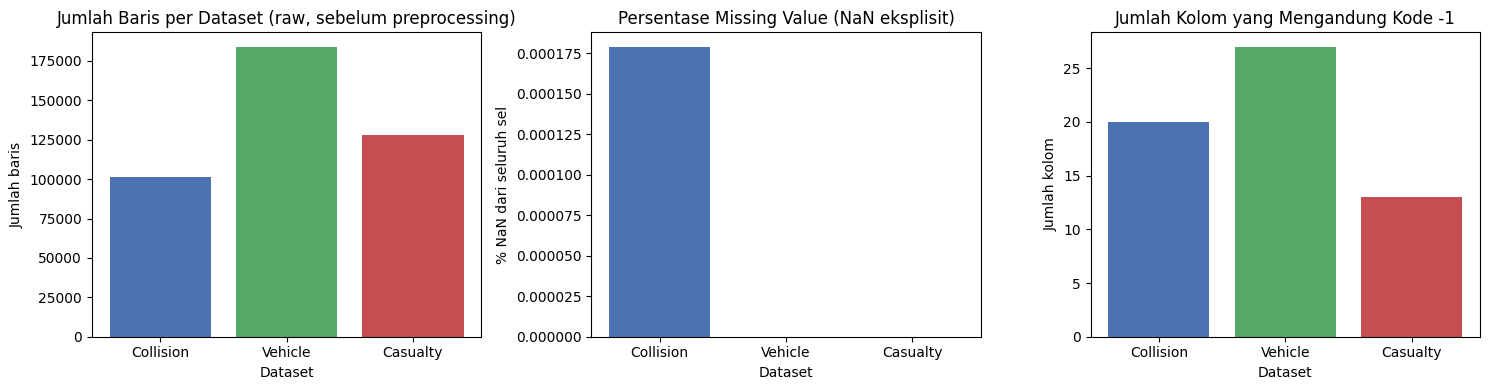

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].bar(inventory["Dataset"], inventory["Rows"], color=["#4C72B0", "#55A868", "#C44E52"])
axes[0].set_title("Jumlah Baris per Dataset (raw, sebelum preprocessing)")
axes[0].set_ylabel("Jumlah baris")
axes[0].set_xlabel("Dataset")

missing_pct = [
    collision_raw.isna().sum().sum() / collision_raw.size * 100,
    vehicle_raw.isna().sum().sum() / vehicle_raw.size * 100,
    casualty_raw.isna().sum().sum() / casualty_raw.size * 100,
]
axes[1].bar(["Collision", "Vehicle", "Casualty"], missing_pct, color=["#4C72B0", "#55A868", "#C44E52"])
axes[1].set_title("Persentase Missing Value (NaN eksplisit)")
axes[1].set_ylabel("% NaN dari seluruh sel")
axes[1].set_xlabel("Dataset")

neg1_cols_count = [
    (special_collision["count_-1"] > 0).sum(),
    (special_vehicle["count_-1"] > 0).sum(),
    (special_casualty["count_-1"] > 0).sum(),
]
axes[2].bar(["Collision", "Vehicle", "Casualty"], neg1_cols_count, color=["#4C72B0", "#55A868", "#C44E52"])
axes[2].set_title("Jumlah Kolom yang Mengandung Kode -1")
axes[2].set_ylabel("Jumlah kolom")
axes[2].set_xlabel("Dataset")

plt.tight_layout()
plt.show()


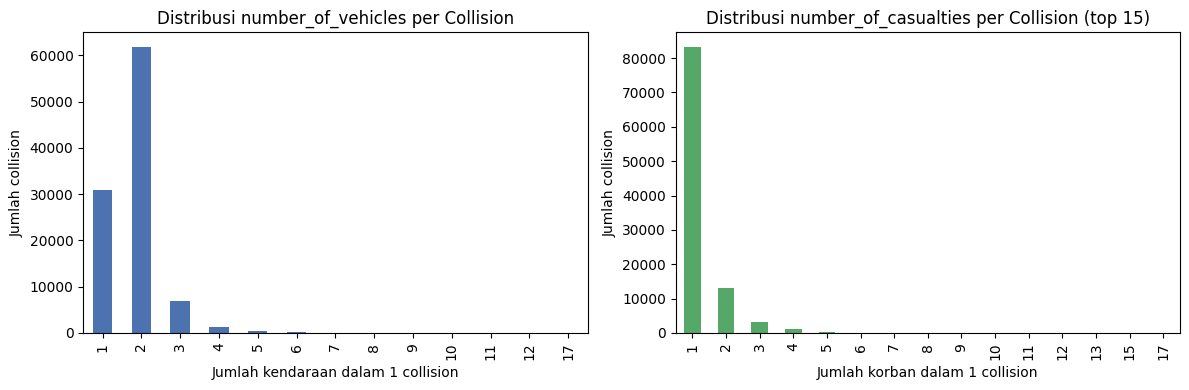

Interpretasi: mayoritas collision melibatkan 1-2 kendaraan dan 1 korban, dengan ekor distribusi ke kanan (potential outlier/kejadian besar), konsisten dengan pola umum data kecelakaan lalu lintas.


In [29]:
# Distribusi jumlah vehicle dan casualty per collision (mendukung Bagian 9 - grain)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

collision_raw["number_of_vehicles"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribusi number_of_vehicles per Collision")
axes[0].set_xlabel("Jumlah kendaraan dalam 1 collision")
axes[0].set_ylabel("Jumlah collision")

collision_raw["number_of_casualties"].value_counts().sort_index().head(15).plot(kind="bar", ax=axes[1], color="#55A868")
axes[1].set_title("Distribusi number_of_casualties per Collision (top 15)")
axes[1].set_xlabel("Jumlah korban dalam 1 collision")
axes[1].set_ylabel("Jumlah collision")

plt.tight_layout()
plt.show()
print("Interpretasi: mayoritas collision melibatkan 1-2 kendaraan dan 1 korban, dengan ekor distribusi ke kanan (potential outlier/kejadian besar), konsisten dengan pola umum data kecelakaan lalu lintas.")


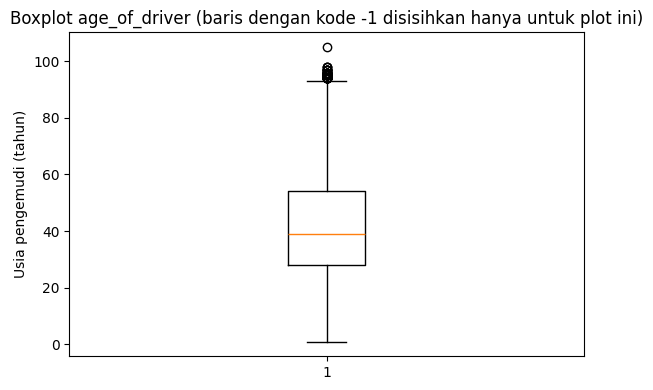

n valid = 155686 dari 183948 total baris Vehicle. Baris dengan age_of_driver == -1 tidak dihapus dari vehicle_raw.


In [30]:
# Boxplot untuk melihat potential outlier pada age_of_driver (setelah -1 disisihkan hanya untuk visualisasi, bukan penghapusan dari raw)
fig, ax = plt.subplots(figsize=(6, 4))
valid_age = vehicle_raw.loc[vehicle_raw["age_of_driver"] != -1, "age_of_driver"]
ax.boxplot(valid_age, vert=True)
ax.set_title("Boxplot age_of_driver (baris dengan kode -1 disisihkan hanya untuk plot ini)")
ax.set_ylabel("Usia pengemudi (tahun)")
plt.tight_layout()
plt.show()
print(f"n valid = {len(valid_age)} dari {len(vehicle_raw)} total baris Vehicle. Baris dengan age_of_driver == -1 tidak dihapus dari vehicle_raw.")


## 12. Masalah yang Ditemukan

### A. Confirmed Issue

*Temuan yang dapat dibuktikan langsung dari data.*

1. `local_authority_district` pada Collision bernilai `-1` pada seluruh **101.525 baris (100%)**, sehingga kolom ini tidak memiliki variasi nilai pada dataset ini.

2. `age_of_vehicle` pada Vehicle bernilai `-1` pada seluruh **183.948 baris (100%)**, sehingga kolom ini tidak memiliki variasi nilai pada dataset ini.

3. Beberapa kolom historis, yaitu `junction_detail_historic`, `pedestrian_crossing_human_control_historic`, `pedestrian_crossing_physical_facilities_historic`, `carriageway_hazards_historic`, `vehicle_manoeuvre_historic`, `vehicle_location_restricted_lane_historic`, dan `journey_purpose_of_driver_historic`, memiliki proporsi nilai `-1` yang tinggi, sekitar **86–88%**. Arti nilai `-1` dan penggunaan kolom-kolom tersebut perlu diperiksa lebih lanjut menggunakan Data Guide.

4. `location_easting_osgr`, `location_northing_osgr`, `longitude`, dan `latitude` masing-masing memiliki **2 nilai NaN** pada Collision.

### B. Potential Issue

*Temuan yang perlu diperiksa lebih lanjut dan belum dapat disimpulkan pada Stage 1.*

1. Beberapa kolom pada Vehicle dan Casualty memiliki nilai `-1` dengan proporsi sekitar **2–25%**, antara lain `engine_capacity_cc`, `propulsion_code`, `driver_imd_decile`, `age_of_driver`, `pedestrian_road_maintenance_worker`, dan `casualty_imd_decile`. Arti nilai `-1` belum ditentukan pada tahap ini dan akan diverifikasi menggunakan Data Guide.

2. Penggunaan `vehicle_reference` pada dataset Casualty, khususnya untuk casualty yang merupakan pedestrian, perlu diverifikasi menggunakan Data Guide. Struktur data saja belum cukup untuk menentukan makna detail kolom tersebut.

3. Nilai `speed_limit` yang ditemukan perlu diperiksa kembali menggunakan Data Guide dan sumber resmi untuk memastikan kesesuaiannya.

### C. Normal / Expected Characteristic

*Temuan yang tidak menunjukkan masalah berdasarkan pemeriksaan pada Stage 1.*

1. `collision_year` bernilai `2025` pada ketiga dataset. Hal ini sesuai dengan file yang digunakan, yaitu data final tahun 2025 yang diterbitkan oleh Department for Transport.

2. Tidak ditemukan **full-row duplicate** maupun duplikasi pada seluruh candidate key yang diperiksa:

   * `collision_index` pada Collision
   * `(collision_index, vehicle_reference)` pada Vehicle
   * `(collision_index, vehicle_reference, casualty_reference)` pada Casualty

3. Seluruh `collision_index` pada Vehicle dan Casualty ditemukan pada Collision. Selain itu, seluruh kombinasi `(collision_index, vehicle_reference)` pada Casualty ditemukan pada Vehicle.

4. `number_of_vehicles` dan `number_of_casualties` pada Collision sesuai dengan jumlah baris Vehicle dan Casualty untuk setiap `collision_index` yang diperiksa.


## 13. Rekomendasi STAGE 2

Sebelum melakukan cleaning, beberapa hal perlu **diverifikasi menggunakan Data Guide**:

### 1. Validitas Data Guide

* **Yang diperiksa:** kesesuaian `2024_code_list` dengan spesifikasi STATS19 yang digunakan pada rilis 2025.
* **Hasil verifikasi:** dokumentasi resmi DfT menyatakan spesifikasi STATS19 terbaru adalah spesifikasi 2024. Karena itu, nama sheet `2024_code_list` tidak dengan sendirinya menunjukkan ketidaksesuaian dengan data final 2025.
* **Sumber:** Data Guide dan dokumentasi resmi DfT.

### 2. Arti nilai `-1`

* **Yang diverifikasi:** arti `-1` pada setiap kolom yang mengandung nilai tersebut.
* **Yang terkait:** `engine_capacity_cc`, `propulsion_code`, `driver_imd_decile`, `age_of_driver`, `casualty_imd_decile`, dan kolom `*_historic`.
* **Alasan:** `-1` tidak boleh langsung dianggap sebagai missing tanpa melihat definisi pada Data Guide.
* **Sumber:** Data Guide.

### 3. Kolom dengan nilai konstan `-1`

* **Yang diverifikasi:** apakah `local_authority_district` dan `age_of_vehicle` memang tidak digunakan atau memiliki status khusus pada rilis 2025.
* **Alasan:** kedua kolom bernilai `-1` pada seluruh baris.
* **Tujuan:** menjadi dasar dokumentasi sebelum menentukan apakah kolom perlu dihapus pada tahap reduction.
* **Sumber:** Data Guide dan dokumentasi rilis DfT.

### 4. `vehicle_reference` pada Casualty

* **Yang diverifikasi:** bagaimana `vehicle_reference` digunakan untuk casualty, terutama pada pedestrian.
* **Yang terkait:** `vehicle_reference`, `casualty_class`, `pedestrian_location`, dan `pedestrian_movement`.
* **Alasan:** informasi ini diperlukan untuk menentukan hubungan data dan strategi penggabungan pada Stage 3.
* **Sumber:** Data Guide.

### 5. Nilai dan definisi kolom kode

* **Yang diverifikasi:** nilai yang diperbolehkan dan arti kode/nilai kategorikal pada `speed_limit`, `light_conditions`, `weather_conditions`, `road_surface_conditions`, `junction_detail`, dan kolom kode lainnya.
* **Alasan:** informasi ini diperlukan untuk memahami data dan memvalidasi nilai pada Stage 3.
* **Sumber:** Data Guide.


## 14. Validation Gate

### STAGE 1 STATUS: **GO TO STAGE 2**

**Alasan:**

Profiling ketiga dataset telah selesai berdasarkan hasil perhitungan langsung dari data. **Candidate key, data grain, dan hubungan antar-dataset** juga telah diperiksa menggunakan hasil uniqueness dan kecocokan jumlah data.

Tidak ditemukan masalah struktur yang menghambat proses berikutnya. Temuan yang masih perlu diperiksa, seperti **arti `-1`, kesesuaian Data Guide 2024 dengan data 2025, status kolom bernilai konstan, dan penggunaan `vehicle_reference` pada Casualty**, telah dicatat sebagai bahan verifikasi pada Stage 2.

### Keterbatasan Stage 1

Pada tahap ini, makna kolom dan kode belum diverifikasi berdasarkan Data Guide. Penentuan grain dan relationship masih didasarkan pada **struktur data dan hasil pemeriksaan pada notebook**. Validasi terhadap definisi resmi DfT akan dilakukan pada **Stage 2** setelah Data Guide dipelajari.


# STAGE 2 — Data Cleaning

## UK Road Safety Open Data 2025 (Collision, Vehicle, Casualty)

Notebook ini melanjutkan Stage 1 (Data Understanding & Profiling). Data mentah dan konfigurasi file telah dimuat pada bagian awal notebook. Setiap keputusan cleaning dibuat berdasarkan urutan:

**Bukti dari data → Definisi dari Data Guide resmi DfT → Keputusan → Tindakan → Validasi**

Pada tahap ini, notebook:

* tidak melakukan merge antar dataset;
* tidak melakukan PCA;
* tidak menghapus kolom hanya karena memiliki banyak nilai `-1` atau hanya memiliki satu nilai. Keputusan tersebut akan dipertimbangkan pada tahap attribute selection/reduction, bukan pada tahap cleaning.


## 2.1 Tujuan Data Cleaning

Menurut Han, Kamber & Pei dalam *Data Mining: Concepts and Techniques*, data cleaning digunakan untuk menangani masalah kualitas data seperti **missing value, noise, outlier, dan inkonsistensi** sebelum data digunakan pada tahap analisis berikutnya.

Tujuan data cleaning pada notebook ini adalah:

1. Memeriksa arti nilai khusus seperti `-1` berdasarkan Data Guide resmi DfT, bukan berdasarkan asumsi.

2. Menentukan status nilai berdasarkan definisi resmi, apakah merupakan missing value, nilai/kode yang valid, atau belum dapat ditentukan.

3. Memeriksa nilai yang tidak valid dan nilai ekstrem (outlier) berdasarkan aturan dan konteks data, tanpa langsung menghapusnya.

4. Menerapkan perubahan hanya jika terdapat bukti yang jelas, kemudian menyimpan hasilnya pada DataFrame baru (`*_clean`) agar data mentah (`*_raw`) tetap tersedia sebagai pembanding.

5. Memvalidasi hasil cleaning untuk memastikan perubahan yang dilakukan sesuai dengan aturan dan tidak menimbulkan masalah baru.


## 2.2 Verifikasi Data Guide

### Langkah 1 — Cek Nama Kolom pada Data dan Data Guide

Sebelum memeriksa arti setiap kode, kita membandingkan **nama kolom pada dataset** dengan **nama field pada Data Guide**.

Pengecekan ini dilakukan untuk memastikan bahwa setiap kolom pada dataset dapat dicocokkan dengan definisi yang tepat di Data Guide dan menghindari kesalahan saat mengambil arti kode.


In [31]:
def cek_selisih_nama_kolom(df, table_name, label):

    """Membandingkan nama kolom pada data dengan nama field pada Data Guide
    untuk tabel yang sama."""

    field_di_guide = set(guide.loc[guide['table'] == table_name, 'field_name'].unique())
    kolom_di_data = set(df.columns)

    hanya_di_data = sorted(kolom_di_data - field_di_guide)
    hanya_di_guide = sorted(field_di_guide - kolom_di_data)

    print(f"--- {label} ---")
    print("Kolom yang hanya ada di data:", hanya_di_data)
    print("Field yang hanya ada di Data Guide:", hanya_di_guide)
    print()

cek_selisih_nama_kolom(collision_raw, 'collision', 'Collision')
cek_selisih_nama_kolom(vehicle_raw, 'vehicle', 'Vehicle')
cek_selisih_nama_kolom(casualty_raw, 'casualty', 'Casualty')

--- Collision ---
Kolom yang hanya ada di data: ['collision_adjusted_severity_serious', 'collision_adjusted_severity_slight', 'enhanced_severity_collision']
Field yang hanya ada di Data Guide: ['collision_adjusted_serious', 'collision_adjusted_slight', 'did_police_officer_attend_scene_of_collision', 'enhanced_collision_severity', 'lsoa_of_collision_location']

--- Vehicle ---
Kolom yang hanya ada di data: []
Field yang hanya ada di Data Guide: []

--- Casualty ---
Kolom yang hanya ada di data: ['casualty_adjusted_severity_serious', 'casualty_adjusted_severity_slight']
Field yang hanya ada di Data Guide: ['casualty_adjusted_serious', 'casualty_adjusted_slight']



Temuan: terdapat beberapa nama kolom pada data yang tidak sama persis dengan nama field pada Data Guide. Beberapa nama memiliki susunan kata yang berbeda, misalnya `enhanced_severity_collision` pada data dan `enhanced_collision_severity` pada Data Guide.

Perbedaan nama tersebut belum cukup untuk menyatakan bahwa kedua field memiliki arti yang sama. Oleh karena itu, perlu dilakukan pengecekan lebih lanjut dengan membandingkan nilai unik pada kolom data dengan kode yang tercantum pada Data Guide untuk field yang diduga sesuai.


In [32]:
# Membuktikan bahwa enhanced_severity_collision (nama di data) memang setara dengan
# enhanced_collision_severity (nama di Data Guide), dengan membandingkan nilai unik vs kode di guide.
nilai_unik_data = sorted(collision_raw['enhanced_severity_collision'].unique())
kode_di_guide = sorted(guide.loc[guide['field_name'] == 'enhanced_collision_severity', 'code'].astype(int).unique())

print("Nilai unik enhanced_severity_collision di data :", nilai_unik_data)
print("Kode yang terdaftar di Data Guide (enhanced_collision_severity):", kode_di_guide)
print("Apakah persis sama?", nilai_unik_data == kode_di_guide)

# Sebagai pembanding tambahan: casualty_raw punya kolom enhanced_casualty_severity
# yang namanya PERSIS SAMA dengan Data Guide, dan kode-nya juga harus sama polanya.
nilai_unik_casualty = sorted(casualty_raw['enhanced_casualty_severity'].unique())
print("\nEnhanced severity di Casualty (nama kolom cocok persis dgn guide):", nilai_unik_casualty)
print("-> pola kodenya sama dengan enhanced_severity_collision, ini memperkuat bukti bahwa keduanya memang field yang setara.")


Nilai unik enhanced_severity_collision di data : [np.int64(-1), np.int64(1), np.int64(3), np.int64(5), np.int64(6), np.int64(7)]
Kode yang terdaftar di Data Guide (enhanced_collision_severity): [np.int64(-1), np.int64(1), np.int64(3), np.int64(5), np.int64(6), np.int64(7)]
Apakah persis sama? True

Enhanced severity di Casualty (nama kolom cocok persis dgn guide): [np.int64(-1), np.int64(1), np.int64(3), np.int64(5), np.int64(6), np.int64(7)]
-> pola kodenya sama dengan enhanced_severity_collision, ini memperkuat bukti bahwa keduanya memang field yang setara.


### Kesimpulan Langkah 1

Kumpulan nilai pada `enhanced_severity_collision` di data, yaitu `[-1, 1, 3, 5, 6, 7]`, sama persis dengan kode pada Data Guide untuk `enhanced_collision_severity`.

Kolom `enhanced_casualty_severity` yang namanya sesuai dengan Data Guide juga memiliki kumpulan kode yang sama. Hal ini menjadi bukti pendukung bahwa `enhanced_severity_collision` dan `enhanced_collision_severity` merujuk pada field yang sama, meskipun nama kolomnya berbeda urutan kata.

Berdasarkan hasil tersebut, definisi `enhanced_collision_severity` pada Data Guide dapat digunakan untuk memahami `enhanced_severity_collision` pada data.

Kolom lain yang memiliki perbedaan nama, seperti `collision_adjusted_severity_serious/slight`, `casualty_adjusted_severity_serious/slight`, `lsoa_of_accident_location`, dan `did_police_officer_attend_scene_of_accident`, akan diperiksa dengan cara yang sama sebelum definisinya digunakan.


In [33]:
# Cek did_police_officer_attend_scene_of_accident: ternyata field ini JUSTRU ada juga
# di Data Guide dengan nama persis sama (DfT mendokumentasikan dua versi nama sekaligus).
sub = guide[guide['field_name'] == 'did_police_officer_attend_scene_of_accident']
print(sub.to_string(index=False))
print("\nNilai unik di data:", sorted(collision_raw['did_police_officer_attend_scene_of_accident'].unique()))
print("-> Nama kolom di data ternyata PERSIS ADA di Data Guide. Tidak ada masalah penamaan di kolom ini.")


    table                                  field_name code                                                                    label note
collision did_police_officer_attend_scene_of_accident    1                                                                      Yes  NaN
collision did_police_officer_attend_scene_of_accident    2                                                                       No  NaN
collision did_police_officer_attend_scene_of_accident    3 No - accident was reported using a self completion  form (self rep only)  NaN
collision did_police_officer_attend_scene_of_accident   -1                                             Data missing or out of range  NaN

Nilai unik di data: [np.int64(1), np.int64(2), np.int64(3)]
-> Nama kolom di data ternyata PERSIS ADA di Data Guide. Tidak ada masalah penamaan di kolom ini.


In [34]:
# Kolom *_adjusted_severity_* (collision & casualty) tidak memiliki daftar kode di Data Guide.
# Nilainya berupa angka desimal 0 - 1, sehingga dicek range nilainya untuk memastikan bentuk datanya.

print("collision_adjusted_severity_serious, contoh nilai:", sorted(collision_raw['collision_adjusted_severity_serious'].unique())[:5], "...")
print("Range:", collision_raw['collision_adjusted_severity_serious'].min(), "sampai", collision_raw['collision_adjusted_severity_serious'].max())

print("\n-> Nilai kolom berupa angka desimal antara 0 dan 1, bukan kode kategori.")
print("Data Guide juga tidak mencantumkan daftar kode untuk field pasangannya.")
print("Karena bukan kolom kode kategori, kolom ini tidak dibahas pada pemeriksaan nilai -1 di Bagian 2.3.")

collision_adjusted_severity_serious, contoh nilai: [np.float64(0.0), np.float64(0.00088), np.float64(0.00099), np.float64(0.00105), np.float64(0.0011)] ...
Range: 0.0 sampai 1.0

-> Nilai kolom berupa angka desimal antara 0 dan 1, bukan kode kategori.
Data Guide juga tidak mencantumkan daftar kode untuk field pasangannya.
Karena bukan kolom kode kategori, kolom ini tidak dibahas pada pemeriksaan nilai -1 di Bagian 2.3.


### Langkah 2 — Buat fungsi untuk membaca definisi resmi dari Data Guide

Supaya semua definisi yang dipakai di notebook ini benar-benar diambil dari Data Guide (bukan diketik manual), kita buat satu fungsi bantu.

In [35]:
# Kalau nama kolom di data beda dengan nama field di Data Guide (lihat Langkah 1),
# kita catat padanannya di sini, hanya untuk kolom yang sudah dibuktikan di Langkah 1.
PADANAN_NAMA = {
    'enhanced_severity_collision': 'enhanced_collision_severity',
}

def lihat_definisi(table_name, kolom):
    """Menampilkan daftar kode dan artinya untuk satu kolom, langsung dari Data Guide."""
    nama_di_guide = PADANAN_NAMA.get(kolom, kolom)
    hasil = guide.loc[(guide['table'] == table_name) & (guide['field_name'] == nama_di_guide),
                       ['code', 'label', 'note']]
    if hasil.empty:
        print(f"[{kolom}] -> TIDAK DITEMUKAN definisi apapun di Data Guide.")
    return hasil

# Contoh pakai fungsi ini untuk kolom-kolom yang jadi perhatian utama di STAGE 1:
for kolom in ['local_authority_district', 'age_of_vehicle', 'propulsion_code', 'driver_distance_banding']:
    print(f"=== Definisi resmi untuk: {kolom} ===")
    print(lihat_definisi('collision' if kolom == 'local_authority_district' else 'vehicle', kolom).to_string(index=False))
    print()


=== Definisi resmi untuk: local_authority_district ===
code                        label note
   1                  Westminster  NaN
   2                       Camden  NaN
   3                    Islington  NaN
   4                      Hackney  NaN
   5                Tower Hamlets  NaN
   6                    Greenwich  NaN
   7                     Lewisham  NaN
   8                    Southwark  NaN
   9                      Lambeth  NaN
  10                   Wandsworth  NaN
  11       Hammersmith and Fulham  NaN
  12       Kensington and Chelsea  NaN
  13               Waltham Forest  NaN
  14                    Redbridge  NaN
  15                     Havering  NaN
  16         Barking and Dagenham  NaN
  17                       Newham  NaN
  18                       Bexley  NaN
  19                      Bromley  NaN
  20                      Croydon  NaN
  21                       Sutton  NaN
  22                       Merton  NaN
  23         Kingston upon Thames  NaN
  24     

### Bacaan Hasil

* `local_authority_district`: kode `-1` berarti `Code deprecated`. Jadi, `-1` bukan missing value, tetapi menunjukkan bahwa kode tersebut sudah tidak digunakan.

* `age_of_vehicle`: tidak memiliki daftar kode pada Data Guide. Karena itu, arti `-1` belum dapat ditentukan berdasarkan Data Guide ini.

* `propulsion_code`: kode `-1` berarti `Undefined`. Jadi, `-1` merupakan kategori yang memiliki arti khusus, bukan nilai kosong.

* `driver_distance_banding`: kode `-1` tercantum pada Data Guide, tetapi labelnya kosong. Karena tidak ada keterangan resmi yang menjelaskan artinya pada field ini, status `-1` belum dapat dipastikan dan tidak langsung dianggap sebagai missing value.


In [36]:
print(lihat_definisi('casualty', 'casualty_distance_banding').to_string(index=False))


code                                                                   label                     note
   1               Collision occurred within 5km of casualties home postcode field introduced in 2023
   2   Collision occurred between 5.001 and 10km of casualties home postcode field introduced in 2023
   3  Collision occurred between 10.001 and 20km of casualties home postcode field introduced in 2023
   4 Collision occurred between 20.001 and 100km of casualties home postcode field introduced in 2023
   5               Collision occurred over 100km of casualties home postcode field introduced in 2023
  -1                                            Data missing or out of range field introduced in 2023


## 2.3 Verifikasi Special Value (khususnya `-1`)

Pada tahap ini, memeriksa setiap kolom yang memiliki nilai `-1` untuk mengetahui arti resminya berdasarkan Data Guide.

Hasil pemeriksaan digunakan untuk menentukan status nilai `-1`, misalnya sebagai kode khusus, data missing, atau nilai yang belum dapat dipastikan.

Seluruh hasil pemeriksaan diambil langsung dari data dan Data Guide, bukan ditentukan secara manual.


In [37]:
def cari_kolom_dengan_neg1(df, table_name, nama_padanan=None):
    """Mencari semua kolom numerik yang punya nilai -1, lalu ambil jumlah dan persentasenya."""
    if nama_padanan is None:
        nama_padanan = {}
    hasil = []
    n = len(df)
    for col in df.columns:
        s = df[col]
        if pd.api.types.is_numeric_dtype(s):
            jumlah = int((s == -1).sum())
            if jumlah > 0:
                nama_di_guide = nama_padanan.get(col, col)
                definisi = guide.loc[(guide['table'] == table_name) &
                                      (guide['field_name'] == nama_di_guide) &
                                      (guide['code'].astype(str) == '-1'), 'label']
                arti_resmi = definisi.iloc[0] if len(definisi) > 0 else "TIDAK ADA DI DATA GUIDE"
                hasil.append({
                    'dataset': table_name,
                    'kolom': col,
                    'jumlah_-1': jumlah,
                    'persen_-1': round(jumlah / n * 100, 2),
                    'arti_resmi_di_data_guide': arti_resmi,
                })
    return pd.DataFrame(hasil)

tabel_collision = cari_kolom_dengan_neg1(collision_raw, 'collision', PADANAN_NAMA)
tabel_vehicle = cari_kolom_dengan_neg1(vehicle_raw, 'vehicle')
tabel_casualty = cari_kolom_dengan_neg1(casualty_raw, 'casualty')

tabel_special_value = pd.concat([tabel_collision, tabel_vehicle, tabel_casualty], ignore_index=True)
tabel_special_value = tabel_special_value.sort_values(['dataset', 'persen_-1'], ascending=[True, False])
tabel_special_value


,dataset,kolom,jumlah_-1,persen_-1,arti_resmi_di_data_guide
50,casualty,pedestrian_road_maintenance_worker,17457,13.65,Data missing or out of range
53,casualty,enhanced_casualty_severity,17394,13.60,Data missing or out of range
52,casualty,casualty_imd_decile,14663,11.47,Data missing or out of range
54,casualty,casualty_distance_banding,14663,11.47,Data missing or out of range
44,casualty,age_of_casualty,2741,2.14,Data missing or out of range
45,casualty,age_band_of_casualty,2741,2.14,Data missing or out of range
43,casualty,sex_of_casualty,1320,1.03,Data missing or out of range
51,casualty,casualty_type,1229,0.96,Data missing or out of range
48,casualty,car_passenger,500,0.39,Data missing or out of range
49,casualty,bus_or_coach_passenger,282,0.22,Data missing or out of range


In [38]:
def klasifikasi_status(arti_resmi):
    """Mengubah teks arti resmi dari Data Guide menjadi satu kategori status yang konsisten."""
    if arti_resmi == "TIDAK ADA DI DATA GUIDE":
        return "BELUM DAPAT DIPASTIKAN (tidak ada definisi di Data Guide)"
    if pd.isna(arti_resmi):
        # Kode -1 tercatat di Data Guide, tapi kolom labelnya dikosongkan (tidak diisi apa-apa)
        return "BELUM DAPAT DIPASTIKAN (kode ada di Data Guide tapi label kosong)"
    if "deprecated" in arti_resmi.lower():
        return "Kolom sudah tidak dipakai (bukan missing value)"
    if arti_resmi.strip().lower() == "undefined":
        return "Kategori valid tersendiri (bukan missing value)"
    if "missing" in arti_resmi.lower() or arti_resmi.strip().lower() == "unknown":
        return "Missing value resmi"
    return "Perlu ditinjau manual"

tabel_special_value['status'] = tabel_special_value['arti_resmi_di_data_guide'].apply(klasifikasi_status)
tabel_special_value


,dataset,kolom,jumlah_-1,persen_-1,arti_resmi_di_data_guide,status
50,casualty,pedestrian_road_maintenance_worker,17457,13.65,Data missing or out of range,Missing value resmi
53,casualty,enhanced_casualty_severity,17394,13.60,Data missing or out of range,Missing value resmi
52,casualty,casualty_imd_decile,14663,11.47,Data missing or out of range,Missing value resmi
54,casualty,casualty_distance_banding,14663,11.47,Data missing or out of range,Missing value resmi
44,casualty,age_of_casualty,2741,2.14,Data missing or out of range,Missing value resmi
45,casualty,age_band_of_casualty,2741,2.14,Data missing or out of range,Missing value resmi
43,casualty,sex_of_casualty,1320,1.03,Data missing or out of range,Missing value resmi
51,casualty,casualty_type,1229,0.96,Data missing or out of range,Missing value resmi
48,casualty,car_passenger,500,0.39,Data missing or out of range,Missing value resmi
49,casualty,bus_or_coach_passenger,282,0.22,Data missing or out of range,Missing value resmi


### Catatan `driver_distance_banding`

`driver_distance_banding` dikategorikan sebagai "BELUM DAPAT DIPASTIKAN" karena Data Guide tidak memberikan label untuk kode `-1` pada kolom ini.

Meskipun `casualty_distance_banding` memiliki keterangan `Data missing or out of range` untuk kode `-1`, arti tersebut tidak langsung diterapkan pada `driver_distance_banding` karena belum ada keterangan tertulis yang mendukung.

Oleh karena itu, nilai `-1` pada `driver_distance_banding` tidak diubah pada Stage 2. Kolom ini dicatat sebagai temuan yang perlu diverifikasi lebih lanjut menggunakan dokumentasi resmi DfT lainnya.

---
## 2.4 Missing Value

Ada dua jenis "missing" yang perlu dibedakan:
1. **NaN eksplisit** (kosong beneran di file CSV) — hanya ditemukan di 4 kolom koordinat Collision (dari STAGE 1).
2. **Kode khusus `-1`** yang menurut Data Guide artinya "Data missing or out of range" atau "Unknown" — ini akan ditangani di bagian 2.6 (Apply Cleaning), memakai tabel keputusan pada 2.5.

### 2.4.1 NaN eksplisit pada koordinat Collision

In [39]:
kolom_koordinat = ['location_easting_osgr', 'location_northing_osgr', 'longitude', 'latitude']
for kolom in kolom_koordinat:
    jumlah_nan = collision_raw[kolom].isna().sum()
    print(f"{kolom}: {jumlah_nan} NaN dari {len(collision_raw)} baris ({jumlah_nan/len(collision_raw)*100:.4f}%)")

# Cek apakah NaN-nya ada di baris yang sama (1 collision yang koordinatnya semuanya tidak diketahui)
baris_nan_koordinat = collision_raw[collision_raw[kolom_koordinat].isna().any(axis=1)]
print(f"\nJumlah baris (collision) yang punya minimal satu NaN di kolom koordinat: {len(baris_nan_koordinat)}")
baris_nan_koordinat[['collision_index'] + kolom_koordinat + ['collision_severity', 'number_of_vehicles', 'number_of_casualties']]


location_easting_osgr: 2 NaN dari 101525 baris (0.0020%)
location_northing_osgr: 2 NaN dari 101525 baris (0.0020%)
longitude: 2 NaN dari 101525 baris (0.0020%)
latitude: 2 NaN dari 101525 baris (0.0020%)

Jumlah baris (collision) yang punya minimal satu NaN di kolom koordinat: 2


,collision_index,location_easting_osgr,location_northing_osgr,longitude,latitude,collision_severity,number_of_vehicles,number_of_casualties
21934,2025622500752,NaN,NaN,NaN,NaN,2,2,1
90721,2025622500721,NaN,NaN,NaN,NaN,3,2,1


### Penanganan NaN pada Koordinat

Terdapat 2 baris Collision yang memiliki `NaN` pada keempat kolom koordinat. Berdasarkan Data Guide, `NaN` berarti lokasi tidak diketahui sehingga nilai tersebut merupakan kondisi yang diperbolehkan.

Kedua baris tetap dipertahankan karena informasi lain pada baris tersebut masih tersedia dan dapat digunakan untuk analisis selain analisis lokasi. Nilai `NaN` tidak diubah atau dihapus.

Jika suatu analisis membutuhkan koordinat lengkap, kedua baris tersebut dapat disaring khusus untuk analisis tersebut.

### 2.4.2 Missing Value dari Kode Khusus (`-1`)

Berdasarkan hasil verifikasi pada Bagian 2.3, nilai `-1` hanya akan diubah menjadi `NaN` pada kolom yang menurut Data Guide secara resmi menunjukkan data missing.

Kolom dengan status "Kolom sudah tidak dipakai", "Kategori valid tersendiri", dan "BELUM DAPAT DIPASTIKAN" tidak diubah. Masing-masing tetap dipertahankan sesuai dengan arti yang diberikan atau belum dapat dipastikan dari Data Guide.

In [40]:
# Ringkasan jumlah kolom per status, supaya jelas skalanya
tabel_special_value['status'].value_counts()


status
Missing value resmi                                                  51
Kolom sudah tidak dipakai (bukan missing value)                       1
BELUM DAPAT DIPASTIKAN (tidak ada definisi di Data Guide)             1
BELUM DAPAT DIPASTIKAN (kode ada di Data Guide tapi label kosong)     1
Kategori valid tersendiri (bukan missing value)                       1
Name: count, dtype: int64

## 2.5 Invalid Value & Range Validation

Nilai dianggap invalid jika tidak sesuai dengan rentang atau kode yang ditetapkan dalam Data Guide.

Untuk kolom yang tidak memiliki rentang atau daftar nilai resmi, tidak membuat batas sendiri. Dengan demikian, penilaian invalid value tetap berdasarkan definisi resmi dan tidak menggunakan asumsi pribadi.

In [41]:
# speed_limit: Data Guide secara eksplisit menuliskan "20,30,40,50,60,70 are the only valid speed limits"
definisi_speed_limit = guide.loc[(guide['field_name'] == 'speed_limit') & (guide['code'].isna()), 'note']
print("Catatan resmi Data Guide untuk speed_limit:")
print(definisi_speed_limit.iloc[0])

nilai_valid_resmi = [20, 30, 40, 50, 60, 70]
nilai_yang_muncul_di_data = sorted(collision_raw['speed_limit'].unique())
nilai_tidak_valid = [v for v in nilai_yang_muncul_di_data if v not in nilai_valid_resmi]

print("\nNilai speed_limit yang benar-benar muncul di data:", nilai_yang_muncul_di_data)
print("Nilai yang TIDAK termasuk daftar resmi:", nilai_tidak_valid if nilai_tidak_valid else "TIDAK ADA")


Catatan resmi Data Guide untuk speed_limit:
20,30,40,50,60,70 are the only valid speed limits on public highways

Nilai speed_limit yang benar-benar muncul di data: [np.int64(20), np.int64(30), np.int64(40), np.int64(50), np.int64(60), np.int64(70)]
Nilai yang TIDAK termasuk daftar resmi: TIDAK ADA


### Kesimpulan `speed_limit`

Semua nilai `speed_limit` yang ditemukan pada data, yaitu `20, 30, 40, 50, 60, dan 70`, sesuai dengan daftar nilai resmi pada Data Guide.

Tidak ditemukan nilai invalid berdasarkan definisi tersebut, sehingga kolom `speed_limit` tidak memerlukan perubahan pada tahap cleaning.

In [42]:
# Untuk age_of_driver, age_of_casualty, engine_capacity_cc: Data Guide TIDAK memberi angka batas
# resmi (bukan seperti speed_limit). Kita hanya bisa melihat rentang nilai yang ADA di data,
# bukan menentukan sendiri berapa batas "valid"-nya.
print("age_of_driver (tanpa kode -1), rentang nilai:")
print(vehicle_raw.loc[vehicle_raw['age_of_driver'] != -1, 'age_of_driver'].describe()[['min', 'max']])

print("\nage_of_casualty (tanpa kode -1), rentang nilai:")
print(casualty_raw.loc[casualty_raw['age_of_casualty'] != -1, 'age_of_casualty'].describe()[['min', 'max']])

print("\nengine_capacity_cc (tanpa kode -1), rentang nilai:")
print(vehicle_raw.loc[vehicle_raw['engine_capacity_cc'] != -1, 'engine_capacity_cc'].describe()[['min', 'max']])


age_of_driver (tanpa kode -1), rentang nilai:


min      1.0
max    105.0
Name: age_of_driver, dtype: float64

age_of_casualty (tanpa kode -1), rentang nilai:


min      0.0
max    105.0
Name: age_of_casualty, dtype: float64

engine_capacity_cc (tanpa kode -1), rentang nilai:
min        1.0
max    48000.0
Name: engine_capacity_cc, dtype: float64


### Kesimpulan

Data Guide tidak memberikan batas angka resmi untuk `age_of_driver`, `age_of_casualty`, dan `engine_capacity_cc`. Oleh karena itu, tidak dapat menyatakan bahwa suatu nilai merupakan nilai invalid hanya berdasarkan rentang yang ditemukan.

Nilai maksimum `105` tahun pada usia dan `48.000 cc` pada kapasitas mesin dicatat sebagai potential outlier untuk diperiksa lebih lanjut pada Bagian 2.6.

Tidak ada nilai yang diubah atau dihapus pada tahap validasi ini.

## 2.6 Outlier Screening

Pada tahap ini, metode IQR (Interquartile Range) digunakan untuk menemukan potential outlier berdasarkan pola distribusi data.

Hasil IQR hanya digunakan sebagai tanda untuk pemeriksaan lebih lanjut, bukan sebagai alasan untuk langsung menghapus data. Setiap potential outlier perlu diperiksa berdasarkan konteks data dan informasi yang tersedia sebelum menentukan tindakan.

In [43]:
def screening_outlier_iqr(series, nama_kolom):
    """Menghitung batas outlier dengan metode IQR (Tukey), lalu menghitung berapa banyak
    nilai yang berada di luar batas tersebut. Ini HANYA untuk screening, bukan keputusan hapus."""
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    batas_bawah, batas_atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    jumlah_potensi_outlier = int(((series < batas_bawah) | (series > batas_atas)).sum())
    print(f"[{nama_kolom}] batas wajar (metode IQR): {batas_bawah:.1f} sampai {batas_atas:.1f}")
    print(f"  -> jumlah nilai di luar batas ini (Potential Outlier, bukan error): {jumlah_potensi_outlier} dari {len(series)} ({jumlah_potensi_outlier/len(series)*100:.2f}%)")
    return batas_bawah, batas_atas

print("=== Vehicle: age_of_driver (kode -1 disisihkan dulu supaya tidak mengganggu hitungan) ===")
screening_outlier_iqr(vehicle_raw.loc[vehicle_raw['age_of_driver'] != -1, 'age_of_driver'], 'age_of_driver')

print("\n=== Casualty: age_of_casualty (kode -1 disisihkan dulu) ===")
screening_outlier_iqr(casualty_raw.loc[casualty_raw['age_of_casualty'] != -1, 'age_of_casualty'], 'age_of_casualty')

print("\n=== Vehicle: engine_capacity_cc (kode -1 disisihkan dulu) ===")
screening_outlier_iqr(vehicle_raw.loc[vehicle_raw['engine_capacity_cc'] != -1, 'engine_capacity_cc'], 'engine_capacity_cc')

print("\n=== Collision: number_of_vehicles ===")
screening_outlier_iqr(collision_raw['number_of_vehicles'], 'number_of_vehicles')

print("\n=== Collision: number_of_casualties ===")
screening_outlier_iqr(collision_raw['number_of_casualties'], 'number_of_casualties')


=== Vehicle: age_of_driver (kode -1 disisihkan dulu supaya tidak mengganggu hitungan) ===


[age_of_driver] batas wajar (metode IQR): -11.0 sampai 93.0
  -> jumlah nilai di luar batas ini (Potential Outlier, bukan error): 65 dari 155686 (0.04%)

=== Casualty: age_of_casualty (kode -1 disisihkan dulu) ===


[age_of_casualty] batas wajar (metode IQR): -22.0 sampai 98.0
  -> jumlah nilai di luar batas ini (Potential Outlier, bukan error): 7 dari 125142 (0.01%)

=== Vehicle: engine_capacity_cc (kode -1 disisihkan dulu) ===
[engine_capacity_cc] batas wajar (metode IQR): 24.0 sampai 3160.0
  -> jumlah nilai di luar batas ini (Potential Outlier, bukan error): 6146 dari 139079 (4.42%)

=== Collision: number_of_vehicles ===
[number_of_vehicles] batas wajar (metode IQR): -0.5 sampai 3.5
  -> jumlah nilai di luar batas ini (Potential Outlier, bukan error): 1939 dari 101525 (1.91%)

=== Collision: number_of_casualties ===
[number_of_casualties] batas wajar (metode IQR): 1.0 sampai 1.0
  -> jumlah nilai di luar batas ini (Potential Outlier, bukan error): 18208 dari 101525 (17.93%)


(np.float64(1.0), np.float64(1.0))

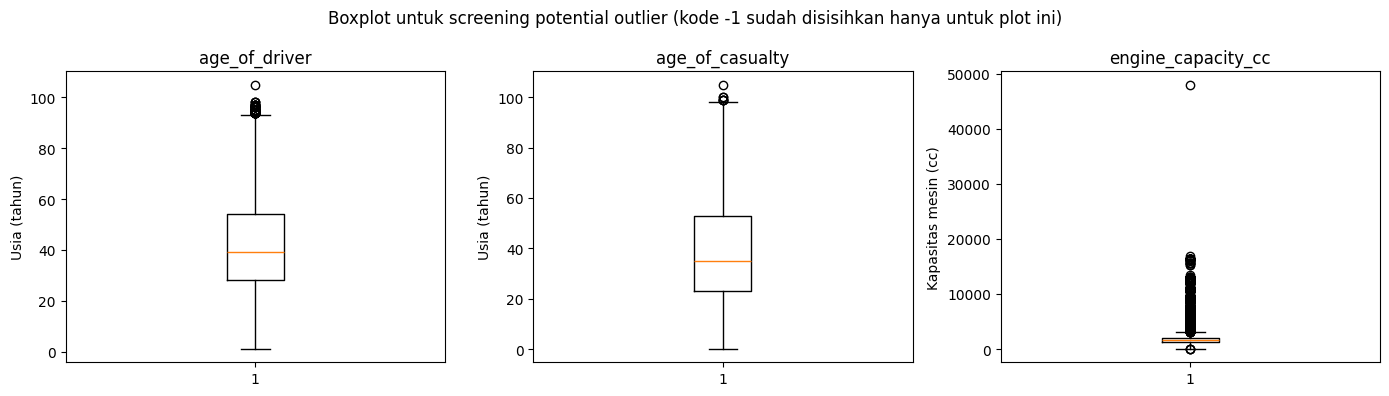

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].boxplot(vehicle_raw.loc[vehicle_raw['age_of_driver'] != -1, 'age_of_driver'])
axes[0].set_title("age_of_driver")
axes[0].set_ylabel("Usia (tahun)")

axes[1].boxplot(casualty_raw.loc[casualty_raw['age_of_casualty'] != -1, 'age_of_casualty'])
axes[1].set_title("age_of_casualty")
axes[1].set_ylabel("Usia (tahun)")

axes[2].boxplot(vehicle_raw.loc[vehicle_raw['engine_capacity_cc'] != -1, 'engine_capacity_cc'])
axes[2].set_title("engine_capacity_cc")
axes[2].set_ylabel("Kapasitas mesin (cc)")

plt.suptitle("Boxplot untuk screening potential outlier (kode -1 sudah disisihkan hanya untuk plot ini)")
plt.tight_layout()
plt.show()


### Keputusan Potential Outlier

Boxplot menunjukkan adanya beberapa nilai yang berada di luar batas IQR pada `age_of_driver`, `age_of_casualty`, dan `engine_capacity_cc`. Nilai tersebut ditandai sebagai potential outlier untuk diperiksa lebih lanjut.

Semua potential outlier tetap dipertahankan dan tidak diubah karena hasil IQR hanya menunjukkan nilai yang berbeda dari pola umum data, bukan membuktikan bahwa nilai tersebut salah.

* `age_of_driver` dan `age_of_casualty`: terdapat beberapa nilai usia tinggi yang terdeteksi sebagai potential outlier. Tidak ada bukti dari data yang diperiksa bahwa nilai tersebut merupakan kesalahan.
* `engine_capacity_cc`: terdapat beberapa nilai kapasitas mesin yang tinggi dan satu nilai yang sangat tinggi. Data Guide tidak memberikan batas resmi untuk kolom ini, sehingga nilai tersebut tidak dapat dinyatakan invalid hanya berdasarkan boxplot.
* `number_of_vehicles` dan `number_of_casualties`: jika terdapat nilai yang terdeteksi sebagai potential outlier, nilai tersebut juga tetap dipertahankan karena belum ada bukti bahwa nilai tersebut merupakan kesalahan data.

Dengan demikian, tidak ada nilai yang dihapus atau diubah pada tahap outlier screening. Nilai potential outlier tetap tersedia untuk analisis selanjutnya.

## 2.7 Cleaning Decision Table

Tabel ini merangkum seluruh keputusan cleaning yang telah dibuat berdasarkan hasil pemeriksaan pada bagian sebelumnya.

Hanya kolom dengan tindakan "Ubah `-1` menjadi `NaN`" yang akan mengalami perubahan data pada Bagian 2.8. Kolom lainnya tetap dipertahankan sesuai dengan hasil verifikasi.

In [45]:
# Daftar kolom yang -1 nya dikonversi menjadi NaN, karena Data Guide secara eksplisit
# menyatakan -1 = "Data missing or out of range" atau "Unknown" untuk nomor jalan.
# Daftar ini disusun berdasarkan hasil pencarian otomatis di bagian 2.3 (tabel_special_value),
# Bukan diketik manual tetapi diambil dari baris berstatus "Missing value resmi".
KOLOM_DIUBAH_JADI_NAN = {
    'collision': sorted(tabel_special_value.loc[
        (tabel_special_value['dataset'] == 'collision') &
        (tabel_special_value['status'] == 'Missing value resmi'), 'kolom'].tolist()),
    'vehicle': sorted(tabel_special_value.loc[
        (tabel_special_value['dataset'] == 'vehicle') &
        (tabel_special_value['status'] == 'Missing value resmi'), 'kolom'].tolist()),
    'casualty': sorted(tabel_special_value.loc[
        (tabel_special_value['dataset'] == 'casualty') &
        (tabel_special_value['status'] == 'Missing value resmi'), 'kolom'].tolist()),
}

for dataset, kolom_list in KOLOM_DIUBAH_JADI_NAN.items():
    print(f"{dataset}: {len(kolom_list)} kolom akan diubah -1 -> NaN")
    print(f"  {kolom_list}")
    print()


collision: 17 kolom akan diubah -1 -> NaN
  ['carriageway_hazards', 'carriageway_hazards_historic', 'enhanced_severity_collision', 'first_road_class', 'first_road_number', 'junction_control', 'junction_detail', 'junction_detail_historic', 'light_conditions', 'pedestrian_crossing', 'pedestrian_crossing_human_control_historic', 'pedestrian_crossing_physical_facilities_historic', 'road_surface_conditions', 'second_road_class', 'second_road_number', 'special_conditions_at_site', 'trunk_road_flag']

vehicle: 22 kolom akan diubah -1 -> NaN
  ['age_band_of_driver', 'age_of_driver', 'driver_imd_decile', 'engine_capacity_cc', 'first_point_of_impact', 'hit_object_in_carriageway', 'hit_object_off_carriageway', 'journey_purpose_of_driver', 'journey_purpose_of_driver_historic', 'junction_location', 'sex_of_driver', 'skidding_and_overturning', 'towing_and_articulation', 'vehicle_direction_from', 'vehicle_direction_to', 'vehicle_leaving_carriageway', 'vehicle_left_hand_drive', 'vehicle_location_restr

In [46]:
# Kolom yang tidak diubah dan alasan keputusannya.
KOLOM_TIDAK_DIUBAH = pd.DataFrame([
    {
        "dataset": "collision",
        "kolom": "local_authority_district",
        "temuan": "-1 pada 100% baris",
        "bukti": "collision_raw['local_authority_district'].eq(-1).mean() == 1.0",
        "sumber_definisi": "Data Guide: kode -1 = 'Code deprecated'",
        "tindakan": "Tidak diubah dan tidak dihapus",
        "alasan": "Kode -1 bukan missing value, tetapi menunjukkan kode yang sudah tidak digunakan. Penghapusan kolom dipertimbangkan pada tahap attribute selection, bukan cleaning."
    },
    {
        "dataset": "vehicle",
        "kolom": "age_of_vehicle",
        "temuan": "-1 pada 100% baris",
        "bukti": "vehicle_raw['age_of_vehicle'].eq(-1).mean() == 1.0",
        "sumber_definisi": "Data Guide tidak memberikan definisi kode untuk kolom ini",
        "tindakan": "Tidak diubah",
        "alasan": "Arti -1 belum dapat dipastikan berdasarkan Data Guide, sehingga tidak diubah menjadi NaN."
    },
    {
        "dataset": "vehicle",
        "kolom": "propulsion_code",
        "temuan": "-1 muncul pada sebagian baris",
        "bukti": "Lihat tabel_special_value",
        "sumber_definisi": "Data Guide: kode -1 = 'Undefined'",
        "tindakan": "Tidak diubah",
        "alasan": "Data Guide menetapkan -1 sebagai 'Undefined'. Karena memiliki arti khusus, nilai ini dipertahankan dan tidak diubah menjadi NaN."
    },
    {
        "dataset": "vehicle",
        "kolom": "driver_distance_banding",
        "temuan": "-1 muncul pada sebagian baris",
        "bukti": "Lihat tabel_special_value",
        "sumber_definisi": "Data Guide mencantumkan kode -1, tetapi labelnya kosong",
        "tindakan": "Tidak diubah",
        "alasan": "Arti -1 belum dapat dipastikan karena Data Guide tidak memberikan label untuk kode tersebut. Keterangan pada casualty_distance_banding tidak langsung diterapkan pada kolom ini."
    }
])

KOLOM_TIDAK_DIUBAH

,dataset,kolom,temuan,bukti,sumber_definisi,tindakan,alasan
0,collision,local_authority_district,-1 pada 100% baris,collision_raw['local_authority_district'].eq(-...,Data Guide: kode -1 = 'Code deprecated',Tidak diubah dan tidak dihapus,"Kode -1 bukan missing value, tetapi menunjukka..."
1,vehicle,age_of_vehicle,-1 pada 100% baris,vehicle_raw['age_of_vehicle'].eq(-1).mean() ==...,Data Guide tidak memberikan definisi kode untu...,Tidak diubah,Arti -1 belum dapat dipastikan berdasarkan Dat...
2,vehicle,propulsion_code,-1 muncul pada sebagian baris,Lihat tabel_special_value,Data Guide: kode -1 = 'Undefined',Tidak diubah,Data Guide menetapkan -1 sebagai 'Undefined'. ...
3,vehicle,driver_distance_banding,-1 muncul pada sebagian baris,Lihat tabel_special_value,"Data Guide mencantumkan kode -1, tetapi labeln...",Tidak diubah,Arti -1 belum dapat dipastikan karena Data Gui...


In [47]:
# Ringkasan keputusan untuk koordinat, speed_limit, dan potential outlier.
KEPUTUSAN_LAIN = pd.DataFrame([
    {
        "dataset": "collision",
        "kolom": "location_easting_osgr, location_northing_osgr, longitude, latitude",
        "temuan": "2 baris memiliki NaN",
        "bukti": "isna().sum() == 2 untuk setiap kolom",
        "sumber_definisi": "Data Guide: 'Null if not known'",
        "tindakan": "Dipertahankan, tidak dihapus atau diimputasi",
        "alasan": "NaN digunakan untuk menunjukkan lokasi yang tidak diketahui. Baris tersebut tetap memiliki informasi lain yang dapat digunakan."
    },
    {
        "dataset": "collision",
        "kolom": "speed_limit",
        "temuan": "Semua nilai sesuai dengan daftar resmi",
        "bukti": "Nilai unik hanya 20, 30, 40, 50, 60, dan 70",
        "sumber_definisi": "Data Guide: daftar nilai speed limit resmi",
        "tindakan": "Tidak ada tindakan",
        "alasan": "Tidak ditemukan nilai yang tidak sesuai dengan daftar resmi."
    },
    {
        "dataset": "vehicle & casualty",
        "kolom": "age_of_driver, age_of_casualty, engine_capacity_cc, number_of_vehicles, number_of_casualties",
        "temuan": "Terdapat potential outlier berdasarkan IQR",
        "bukti": "Lihat hasil screening_outlier_iqr() pada Bagian 2.6",
        "sumber_definisi": "Data Guide tidak memberikan batas angka resmi untuk kolom yang diperiksa",
        "tindakan": "Dipertahankan, tidak dihapus atau diubah",
        "alasan": "IQR hanya menandai nilai yang berada di luar batas statistik. Tidak ada bukti yang cukup untuk menyatakan nilai tersebut sebagai kesalahan data."
    }
])

KEPUTUSAN_LAIN

,dataset,kolom,temuan,bukti,sumber_definisi,tindakan,alasan
0,collision,"location_easting_osgr, location_northing_osgr,...",2 baris memiliki NaN,isna().sum() == 2 untuk setiap kolom,Data Guide: 'Null if not known',"Dipertahankan, tidak dihapus atau diimputasi",NaN digunakan untuk menunjukkan lokasi yang ti...
1,collision,speed_limit,Semua nilai sesuai dengan daftar resmi,"Nilai unik hanya 20, 30, 40, 50, 60, dan 70",Data Guide: daftar nilai speed limit resmi,Tidak ada tindakan,Tidak ditemukan nilai yang tidak sesuai dengan...
2,vehicle & casualty,"age_of_driver, age_of_casualty, engine_capacit...",Terdapat potential outlier berdasarkan IQR,Lihat hasil screening_outlier_iqr() pada Bagia...,Data Guide tidak memberikan batas angka resmi ...,"Dipertahankan, tidak dihapus atau diubah",IQR hanya menandai nilai yang berada di luar b...


## 2.8 Apply Cleaning

Pada tahap ini, perubahan yang telah ditetapkan pada Bagian 2.7 diterapkan dengan mengubah nilai `-1` menjadi `NaN` hanya pada kolom yang telah ditentukan.

Kolom lainnya tetap dipertahankan tanpa perubahan. Data asli tetap disimpan pada DataFrame `*_raw`, sedangkan hasil cleaning disimpan pada DataFrame `*_clean`.


In [48]:
# Buat salinan dari data mentah, collision_raw/vehicle_raw/casualty_raw tidak disentuh sama sekali.
collision_clean = collision_raw.copy()
vehicle_clean = vehicle_raw.copy()
casualty_clean = casualty_raw.copy()

def ubah_neg1_jadi_nan(df, daftar_kolom):
    """Mengganti nilai -1 menjadi NaN, HANYA untuk kolom yang sudah divalidasi lewat Data Guide."""
    for kolom in daftar_kolom:
        df[kolom] = df[kolom].replace(-1, np.nan)
    return df

collision_clean = ubah_neg1_jadi_nan(collision_clean, KOLOM_DIUBAH_JADI_NAN['collision'])
vehicle_clean = ubah_neg1_jadi_nan(vehicle_clean, KOLOM_DIUBAH_JADI_NAN['vehicle'])
casualty_clean = ubah_neg1_jadi_nan(casualty_clean, KOLOM_DIUBAH_JADI_NAN['casualty'])

print("Cleaning selesai diterapkan.")
print("Kolom yang diubah di Collision:", len(KOLOM_DIUBAH_JADI_NAN['collision']))
print("Kolom yang diubah di Vehicle  :", len(KOLOM_DIUBAH_JADI_NAN['vehicle']))
print("Kolom yang diubah di Casualty :", len(KOLOM_DIUBAH_JADI_NAN['casualty']))


Cleaning selesai diterapkan.
Kolom yang diubah di Collision: 17
Kolom yang diubah di Vehicle  : 22
Kolom yang diubah di Casualty : 12


## 2.9 Cleaning Validation (Before vs After)

Pada tahap ini, hasil cleaning dibandingkan dengan data sebelum cleaning untuk memastikan perubahan yang dilakukan sesuai dengan keputusan pada tahap sebelumnya.

Pemeriksaan meliputi:

* jumlah baris dan kolom tetap sama;
* candidate key tetap unik;
* grain setiap dataset tetap terjaga;
* referential integrity tetap terjaga; dan
* jumlah nilai yang berubah dari `-1` menjadi `NaN` sesuai dengan hasil cleaning.

In [49]:
def bandingkan_shape(raw, clean, nama):
    sama_baris = raw.shape[0] == clean.shape[0]
    sama_kolom = raw.shape[1] == clean.shape[1]
    print(f"[{nama}] baris: {raw.shape[0]} -> {clean.shape[0]} (sama? {sama_baris}) | "
          f"kolom: {raw.shape[1]} -> {clean.shape[1]} (sama? {sama_kolom})")

bandingkan_shape(collision_raw, collision_clean, "Collision")
bandingkan_shape(vehicle_raw, vehicle_clean, "Vehicle")
bandingkan_shape(casualty_raw, casualty_clean, "Casualty")


[Collision] baris: 101525 -> 101525 (sama? True) | kolom: 44 -> 44 (sama? True)
[Vehicle] baris: 183948 -> 183948 (sama? True) | kolom: 32 -> 32 (sama? True)
[Casualty] baris: 127883 -> 127883 (sama? True) | kolom: 23 -> 23 (sama? True)


In [50]:
def bandingkan_missing(raw, clean, nama):
    nan_sebelum = int(raw.isna().sum().sum())
    nan_sesudah = int(clean.isna().sum().sum())
    print(f"[{nama}] total NaN sebelum: {nan_sebelum} -> sesudah: {nan_sesudah} "
          f"(bertambah {nan_sesudah - nan_sebelum}, ini yang tadinya kode -1)")

bandingkan_missing(collision_raw, collision_clean, "Collision")
bandingkan_missing(vehicle_raw, vehicle_clean, "Vehicle")
bandingkan_missing(casualty_raw, casualty_clean, "Casualty")


[Collision] total NaN sebelum: 8 -> sesudah: 549076 (bertambah 549068, ini yang tadinya kode -1)
[Vehicle] total NaN sebelum: 0 -> sesudah: 684796 (bertambah 684796, ini yang tadinya kode -1)


[Casualty] total NaN sebelum: 0 -> sesudah: 73074 (bertambah 73074, ini yang tadinya kode -1)


In [51]:
# Cek candidate key masih unik setelah cleaning (harus tetap unik, karena kita
# hanya mengganti nilai -1 -> NaN, tidak menyentuh kolom key sama sekali)
print("collision_index unik?", collision_clean['collision_index'].is_unique)
print("(collision_index, vehicle_reference) unik?",
      not vehicle_clean.duplicated(subset=['collision_index', 'vehicle_reference']).any())
print("(collision_index, vehicle_reference, casualty_reference) unik?",
      not casualty_clean.duplicated(subset=['collision_index', 'vehicle_reference', 'casualty_reference']).any())


collision_index unik? True
(collision_index, vehicle_reference) unik? True


(collision_index, vehicle_reference, casualty_reference) unik? True


In [52]:
# Cek referential integrity masih sama seperti STAGE 1 (harus tetap utuh)
collision_ids = set(collision_clean['collision_index'])
vehicle_ids = set(vehicle_clean['collision_index'])
casualty_ids = set(casualty_clean['collision_index'])

print("Semua collision_index di Vehicle ada di Collision?", vehicle_ids.issubset(collision_ids))
print("Semua collision_index di Casualty ada di Collision?", casualty_ids.issubset(collision_ids))

vehicle_keys = set(zip(vehicle_clean['collision_index'], vehicle_clean['vehicle_reference']))
casualty_keys = set(zip(casualty_clean['collision_index'], casualty_clean['vehicle_reference']))
print("Semua (collision_index, vehicle_reference) di Casualty ada di Vehicle?",
      casualty_keys.issubset(vehicle_keys))


Semua collision_index di Vehicle ada di Collision? True
Semua collision_index di Casualty ada di Collision? True


Semua (collision_index, vehicle_reference) di Casualty ada di Vehicle? True


In [53]:
# Tabel ringkasan before-after final
ringkasan_before_after = pd.DataFrame([
    {
        "Dataset": "Collision",
        "Rows (before)": collision_raw.shape[0],
        "Rows (after)": collision_clean.shape[0],
        "Columns (before)": collision_raw.shape[1],
        "Columns (after)": collision_clean.shape[1],
        "Missing (before)": int(collision_raw.isna().sum().sum()),
        "Missing (after)": int(collision_clean.isna().sum().sum()),
        "Full-row duplicate (before)": int(collision_raw.duplicated().sum()),
        "Full-row duplicate (after)": int(collision_clean.duplicated().sum()),
        "Candidate key unik?": collision_clean["collision_index"].is_unique
    },
    {
        "Dataset": "Vehicle",
        "Rows (before)": vehicle_raw.shape[0],
        "Rows (after)": vehicle_clean.shape[0],
        "Columns (before)": vehicle_raw.shape[1],
        "Columns (after)": vehicle_clean.shape[1],
        "Missing (before)": int(vehicle_raw.isna().sum().sum()),
        "Missing (after)": int(vehicle_clean.isna().sum().sum()),
        "Full-row duplicate (before)": int(vehicle_raw.duplicated().sum()),
        "Full-row duplicate (after)": int(vehicle_clean.duplicated().sum()),
        "Candidate key unik?": not vehicle_clean.duplicated(
            subset=["collision_index", "vehicle_reference"]
        ).any()
    },
    {
        "Dataset": "Casualty",
        "Rows (before)": casualty_raw.shape[0],
        "Rows (after)": casualty_clean.shape[0],
        "Columns (before)": casualty_raw.shape[1],
        "Columns (after)": casualty_clean.shape[1],
        "Missing (before)": int(casualty_raw.isna().sum().sum()),
        "Missing (after)": int(casualty_clean.isna().sum().sum()),
        "Full-row duplicate (before)": int(casualty_raw.duplicated().sum()),
        "Full-row duplicate (after)": int(casualty_clean.duplicated().sum()),
        "Candidate key unik?": not casualty_clean.duplicated(
            subset=[
                "collision_index",
                "vehicle_reference",
                "casualty_reference"
            ]
        ).any()
    }
])

ringkasan_before_after

,Dataset,Rows (before),Rows (after),Columns (before),Columns (after),Missing (before),Missing (after),Full-row duplicate (before),Full-row duplicate (after),Candidate key unik?
0,Collision,101525,101525,44,44,8,549076,0,0,True
1,Vehicle,183948,183948,32,32,0,684796,0,0,True
2,Casualty,127883,127883,23,23,0,73074,0,0,True


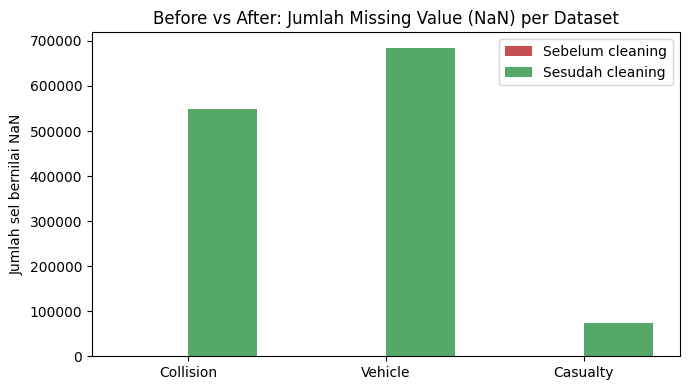

Kenaikan jumlah NaN terjadi karena nilai -1 pada kolom yang telah ditentukan diubah menjadi NaN berdasarkan hasil verifikasi Data Guide.


In [54]:
# Visualisasi before-after: perbandingan jumlah missing value per dataset
fig, ax = plt.subplots(figsize=(7, 4))

x = np.arange(len(ringkasan_before_after))
lebar = 0.35

ax.bar(
    x - lebar / 2,
    ringkasan_before_after["Missing (before)"],
    lebar,
    label="Sebelum cleaning",
    color="#C44E52"
)

ax.bar(
    x + lebar / 2,
    ringkasan_before_after["Missing (after)"],
    lebar,
    label="Sesudah cleaning",
    color="#55A868"
)

ax.set_xticks(x)
ax.set_xticklabels(ringkasan_before_after["Dataset"])
ax.set_ylabel("Jumlah sel bernilai NaN")
ax.set_title("Before vs After: Jumlah Missing Value (NaN) per Dataset")
ax.legend()

plt.tight_layout()
plt.show()

print(
    "Kenaikan jumlah NaN terjadi karena nilai -1 pada kolom yang telah ditentukan "
    "diubah menjadi NaN berdasarkan hasil verifikasi Data Guide."
)

# STAGE 2 VALIDATION GATE

### A. Data Quality

- Masalah yang ditemukan pada Stage 1 sudah ditangani atau memiliki alasan yang jelas untuk dipertahankan:
  - `local_authority_district` → nilai `-1` dipertahankan karena Data Guide mendefinisikannya sebagai `Code deprecated`, bukan missing value.
  - `age_of_vehicle` → nilai `-1` dipertahankan karena Data Guide tidak memberikan definisi untuk kode tersebut. Statusnya dicatat sebagai Belum Dapat Dipastikan.
  - Kolom `*_historic` → nilai `-1` diubah menjadi `NaN` pada kolom yang berdasarkan Data Guide menunjukkan data missing atau out of range.
  - NaN pada kolom koordinat → dipertahankan karena Data Guide menyatakan `Null if not known`.

- Missing value, baik `NaN` maupun kode `-1` yang telah terbukti menunjukkan data missing, sudah memiliki treatment yang jelas dan tercatat pada tabel keputusan di Bagian 2.7.

- Special value seperti `-1` sudah diperiksa berdasarkan Data Guide pada Bagian 2.3. Nilai `-1` tidak langsung dianggap sebagai missing.

- Invalid value sudah diperiksa pada kolom yang memiliki daftar nilai resmi. Pada `speed_limit`, seluruh nilai yang ditemukan sesuai dengan Data Guide sehingga tidak ditemukan nilai invalid.

- Potential outlier pada usia, kapasitas mesin, jumlah kendaraan, dan jumlah korban sudah diperiksa menggunakan IQR. Nilai tersebut tetap dipertahankan karena hasil IQR hanya menunjukkan potential outlier dan tidak membuktikan bahwa nilai tersebut merupakan kesalahan data.


### B. Data Integrity

- Candidate key tetap unik setelah cleaning:
  - Collision: `collision_index`
  - Vehicle: `(collision_index, vehicle_reference)`
  - Casualty: `(collision_index, vehicle_reference, casualty_reference)`

- Grain setiap dataset tetap terjaga:
  - Collision: 1 baris = 1 collision
  - Vehicle: 1 baris = 1 vehicle involvement
  - Casualty: 1 baris = 1 casualty

- Tidak terjadi perubahan jumlah baris. Jumlah baris pada `*_clean` sama dengan `*_raw` untuk ketiga dataset.

- Seluruh perubahan nilai `-1` menjadi `NaN` dan nilai `-1` yang dipertahankan sudah dicatat pada tabel keputusan di Bagian 2.7.

- Referential integrity antara Collision, Vehicle, dan Casualty tetap terjaga setelah cleaning.

- Data mentah (`collision_raw`, `vehicle_raw`, dan `casualty_raw`) tetap tersedia dan tidak diubah.


### C. Reproducibility

- Seluruh proses cleaning dilakukan menggunakan kode sehingga dapat dijalankan kembali dari awal notebook.

- Setiap keputusan cleaning didukung oleh hasil pemeriksaan data dan Data Guide, bukan berdasarkan nilai yang ditulis secara manual.


## Hal yang Masih BELUM DAPAT DIPASTIKAN

Beberapa temuan belum dapat ditentukan berdasarkan Data Guide yang digunakan. Temuan tersebut tetap dicatat untuk dipertimbangkan pada tahap berikutnya.

1. `age_of_vehicle` pada Vehicle memiliki nilai `-1` pada seluruh baris. Data Guide tidak memberikan definisi untuk kode `-1`, sehingga nilai tersebut dipertahankan tanpa perubahan.

2. `driver_distance_banding` pada Vehicle memiliki kode `-1` tanpa label pada Data Guide. Karena tidak ada keterangan resmi mengenai arti kode tersebut, nilai `-1` dipertahankan tanpa perubahan.

3. `local_authority_district` pada Collision memiliki nilai `-1` pada seluruh baris. Data Guide mendefinisikan `-1` sebagai `Code deprecated`. Nilai tersebut dipertahankan pada tahap cleaning. Keputusan untuk menggunakan atau menghapus kolom dipertimbangkan pada tahap attribute selection/reduction.

Ketiga temuan tersebut tidak menghalangi proses cleaning karena tidak ada perubahan yang dilakukan tanpa dasar definisi yang cukup.


## STAGE 2 STATUS: GO TO NEXT STAGE

### Kesimpulan

Proses cleaning telah selesai dan setiap perubahan nilai didasarkan pada hasil pemeriksaan data serta definisi pada Data Guide DfT.

Nilai `-1` hanya diubah menjadi `NaN` pada kolom yang telah diverifikasi sebagai missing value berdasarkan Data Guide. Nilai `-1` dengan arti lain atau arti yang belum dapat dipastikan tetap dipertahankan.

Setelah cleaning:
- jumlah baris setiap dataset tetap sama;
- candidate key tetap unik;
- grain setiap dataset tetap terjaga;
- referential integrity tetap terjaga; dan
- data mentah tetap tersedia sebagai pembanding.

Dengan hasil tersebut, `collision_clean`, `vehicle_clean`, dan `casualty_clean` dapat digunakan pada tahap berikutnya. Tiga temuan yang masih belum dapat dipastikan tetap dicatat sebagai informasi untuk dipertimbangkan pada tahap attribute selection/reduction.

# STAGE 3 — Data Integration
## UK Road Safety Open Data 2025 (Collision, Vehicle, Casualty)

### 3.1 Tujuan Data Integration

Setelah Stage 1 (profiling) dan Stage 2 (cleaning) selesai, tahap ini menggabungkan tiga tabel yang saling berhubungan (`collision_clean`, `vehicle_clean`, `casualty_clean`) menjadi satu tabel yang bisa dipakai bersama-sama pada tahap analisis berikutnya.

Menurut Han, Kamber & Pei (*Data Mining: Concepts and Techniques*, Bab 3), **data integration** bukan sekadar menyambungkan tabel, tapi harus melalui pengecekan:
- apakah key (kolom penyambung) benar-benar cocok satu sama lain,
- apakah hubungan antar tabel sesuai dugaan (one-to-one, one-to-many, dst.),
- apakah penggabungan menimbulkan duplikasi baris yang tidak semestinya (row multiplication).

**Aturan penting di tahap ini:**
- Sumber data yang dipakai adalah hasil Stage 2 (`*_clean`), **bukan** data mentah (`*_raw`).
- Setiap langkah harus mengikuti pola: **Evidence (bukti) → Decision (keputusan) → Action (tindakan) → Validation (pengecekan ulang)**.

---
## 3.2 Input Validation

### 3.2.1 Audit Input Hasil Stage 2 (Step 1)

Sebelum digabungkan, kita cek dulu kondisi ketiga dataframe hasil cleaning: berapa baris, berapa kolom, dan apakah candidate key-nya (hasil stage 1) masih unik seperti seharusnya.

In [55]:
def hitung_duplicate_key(df, kolom_key):
    return int(df.duplicated(subset=kolom_key).sum())

audit_input = pd.DataFrame([
    {"Dataset": "Collision", "Grain": "1 row = 1 collision", "Candidate Key": "collision_index",
     "Rows": collision_clean.shape[0], "Columns": collision_clean.shape[1],
     "Duplicate Key": hitung_duplicate_key(collision_clean, ["collision_index"])},
    {"Dataset": "Vehicle", "Grain": "1 row = 1 vehicle involvement", "Candidate Key": "collision_index + vehicle_reference",
     "Rows": vehicle_clean.shape[0], "Columns": vehicle_clean.shape[1],
     "Duplicate Key": hitung_duplicate_key(vehicle_clean, ["collision_index", "vehicle_reference"])},
    {"Dataset": "Casualty", "Grain": "1 row = 1 casualty", "Candidate Key": "collision_index + vehicle_reference + casualty_reference",
     "Rows": casualty_clean.shape[0], "Columns": casualty_clean.shape[1],
     "Duplicate Key": hitung_duplicate_key(casualty_clean, ["collision_index", "vehicle_reference", "casualty_reference"])},
])
audit_input


,Dataset,Grain,Candidate Key,Rows,Columns,Duplicate Key
0,Collision,1 row = 1 collision,collision_index,101525,44,0
1,Vehicle,1 row = 1 vehicle involvement,collision_index + vehicle_reference,183948,32,0
2,Casualty,1 row = 1 casualty,collision_index + vehicle_reference + casualty...,127883,23,0


**Evidence:** ketiga dataset punya 0 duplicate key, dan jumlah baris/kolomnya sama persis dengan hasil STAGE 2.
**Decision:** kondisi input sesuai dengan yang diharapkan berdasarkan Stage 1/2, sehingga proses integration boleh dilanjutkan.
**Validation:** dicek ulang lewat kode di atas (bukan diasumsikan dari laporan Stage 1/2 sebelumnya).

### 3.2.2 Validasi Ulang Candidate Key (Step 2)

Ini pengecekan yang sama seperti di atas, tapi ditampilkan lebih detail (jumlah baris vs jumlah key unik), sesuai permintaan Step 2.

In [56]:
def validasi_key(df, kolom_key, nama):
    n_rows = len(df)
    n_unique = df.drop_duplicates(subset=kolom_key).shape[0]
    n_duplicate = n_rows - n_unique
    print(f"[{nama}] rows = {n_rows} | unique key = {n_unique} | duplicate key = {n_duplicate}")
    if n_duplicate > 0:
        print("  Contoh key yang duplikat:")
        print(df[df.duplicated(subset=kolom_key, keep=False)][kolom_key].drop_duplicates().head())
    return n_duplicate

dup_collision = validasi_key(collision_clean, ["collision_index"], "Collision")
dup_vehicle = validasi_key(vehicle_clean, ["collision_index", "vehicle_reference"], "Vehicle")
dup_casualty = validasi_key(casualty_clean, ["collision_index", "vehicle_reference", "casualty_reference"], "Casualty")


[Collision] rows = 101525 | unique key = 101525 | duplicate key = 0


[Vehicle] rows = 183948 | unique key = 183948 | duplicate key = 0
[Casualty] rows = 127883 | unique key = 127883 | duplicate key = 0


**Kesimpulan:** tidak ditemukan duplicate key sama sekali di ketiga dataset (hasil di atas semuanya 0). Karena tidak ada duplicate, tidak perlu investigasi tambahan di bagian ini.

## 3.3 Referential Integrity

Sebelum melakukan penggabungan data, hubungan antar-dataset diperiksa terlebih dahulu untuk memastikan setiap baris pada dataset anak memiliki pasangan yang sesuai pada dataset induk.

Pemeriksaan dilakukan pada:
- `Vehicle` terhadap `Collision`
- `Casualty` terhadap `Collision`
- `Casualty` terhadap `Vehicle`

Jika ditemukan baris yang tidak memiliki pasangan (*unmatched*), baris tersebut dicatat dan diperiksa lebih lanjut. Baris *unmatched* tidak langsung dihapus.

In [57]:
def cek_referential_integrity(df_anak, kolom_key, key_induk_set, nama):
    """Mengecek berapa banyak baris di tabel anak yang key-nya TIDAK ditemukan di tabel induk."""
    if len(kolom_key) == 1:
        cocok = df_anak[kolom_key[0]].isin(key_induk_set)
    else:
        pasangan = list(zip(*[df_anak[k] for k in kolom_key]))
        cocok = pd.Series([p in key_induk_set for p in pasangan], index=df_anak.index)
    jumlah_cocok = int(cocok.sum())
    jumlah_tidak_cocok = int((~cocok).sum())
    persen_tidak_cocok = jumlah_tidak_cocok / len(df_anak) * 100
    print(f"[{nama}] cocok = {jumlah_cocok} | tidak cocok (unmatched) = {jumlah_tidak_cocok} ({persen_tidak_cocok:.4f}%)")
    return jumlah_tidak_cocok

# 1) Vehicle -> Collision
key_collision = set(collision_clean['collision_index'])
unmatched_1 = cek_referential_integrity(vehicle_clean, ['collision_index'], key_collision, "Vehicle -> Collision")

# 2) Casualty -> Collision
unmatched_2 = cek_referential_integrity(casualty_clean, ['collision_index'], key_collision, "Casualty -> Collision")

# 3) Casualty -> Vehicle
key_vehicle = set(zip(vehicle_clean['collision_index'], vehicle_clean['vehicle_reference']))
unmatched_3 = cek_referential_integrity(casualty_clean, ['collision_index', 'vehicle_reference'], key_vehicle, "Casualty -> Vehicle")


[Vehicle -> Collision] cocok = 183948 | tidak cocok (unmatched) = 0 (0.0000%)


[Casualty -> Collision] cocok = 127883 | tidak cocok (unmatched) = 0 (0.0000%)


[Casualty -> Vehicle] cocok = 127883 | tidak cocok (unmatched) = 0 (0.0000%)


### Evidence
Ketiga pemeriksaan menunjukkan 0 baris yang tidak memiliki pasangan (*unmatched*), atau 0%.

### Decision
Referential integrity antar ketiga dataset tetap terjaga. Dengan demikian, proses merge dapat dilanjutkan karena tidak ditemukan key yang tidak memiliki pasangan.

### Validation
Hasil pemeriksaan dihitung langsung menggunakan data hasil Stage 2, sehingga kondisi setelah cleaning benar-benar diperiksa kembali dan tidak hanya menggunakan hasil dari Stage 1.

---
## 3.4 Cardinality Validation

Sebelum merge, kita pastikan dulu jenis hubungannya benar-benar **one-to-many**, memakai fitur bawaan pandas (`validate="one_to_many"`), yang akan otomatis memunculkan error kalau ternyata cardinality-nya tidak sesuai.

In [58]:
# Uji cardinality Collision -> Vehicle dengan percobaan merge kecil-kecilan (memakai validate)
try:
    _tes_cv = collision_clean.merge(vehicle_clean, on="collision_index", how="left", validate="one_to_many")
    print("Collision -> Vehicle: cardinality one-to-many TERBUKTI VALID oleh pandas (tidak ada error).")
except Exception as e:
    print("Collision -> Vehicle: GAGAL validasi one-to-many. Detail error:")
    print(e)


Collision -> Vehicle: cardinality one-to-many TERBUKTI VALID oleh pandas (tidak ada error).


In [59]:
# Uji cardinality Vehicle -> Casualty
try:
    _tes_vc = vehicle_clean.merge(casualty_clean, on=["collision_index", "vehicle_reference"], how="left", validate="one_to_many")
    print("Vehicle -> Casualty: cardinality one-to-many TERBUKTI VALID oleh pandas (tidak ada error).")
except Exception as e:
    print("Vehicle -> Casualty: GAGAL validasi one-to-many. Detail error:")
    print(e)


Vehicle -> Casualty: cardinality one-to-many TERBUKTI VALID oleh pandas (tidak ada error).


### Kesimpulan

Hubungan `Collision → Vehicle` dan `Vehicle → Casualty` terbukti bersifat one-to-many berdasarkan hasil validasi saat proses merge.

Validasi dilakukan menggunakan parameter `validate` pada pandas, sehingga hubungan yang digunakan pada merge diperiksa langsung terhadap data dan bukan hanya berdasarkan asumsi dari Stage 1.

## 3.5 Collision → Vehicle Integration

Pada tahap ini, dataset `Collision` digabungkan dengan dataset `Vehicle` menggunakan `collision_index`.

Hubungan kedua dataset bersifat one-to-many, yaitu satu `Collision` dapat memiliki satu atau lebih `Vehicle`. Oleh karena itu, setelah merge jumlah baris hasil gabungan dapat lebih banyak daripada jumlah baris pada `Collision`.

Pertambahan jumlah baris tersebut merupakan konsekuensi dari hubungan one-to-many dan bukan menunjukkan adanya duplikasi data.

In [60]:
# Cek dulu kolom mana yang namanya sama persis di kedua tabel (selain key merge),
# supaya kita tahu kolom mana yang nanti diberi akhiran (suffix) oleh pandas.
kolom_sama = set(collision_clean.columns) & set(vehicle_clean.columns) - {"collision_index"}
print("Kolom dengan nama sama di Collision & Vehicle (akan diberi suffix _collision / _vehicle):", kolom_sama)


Kolom dengan nama sama di Collision & Vehicle (akan diberi suffix _collision / _vehicle): {'collision_year', 'collision_ref_no'}


In [61]:
collision_vehicle = collision_clean.merge(
    vehicle_clean,
    on="collision_index",
    how="left",
    suffixes=("_collision", "_vehicle"),
    validate="one_to_many",
)

print("collision_vehicle shape:", collision_vehicle.shape)

print("\nGrain hasil integration:")
print("1 baris = 1 vehicle involvement yang dilengkapi dengan data collision.")

print(
    "Jumlah baris hasil integration dapat lebih besar daripada jumlah collision "
    "karena satu collision dapat memiliki lebih dari satu vehicle."
)

collision_vehicle shape: (183948, 75)

Grain hasil integration:
1 baris = 1 vehicle involvement yang dilengkapi dengan data collision.
Jumlah baris hasil integration dapat lebih besar daripada jumlah collision karena satu collision dapat memiliki lebih dari satu vehicle.


In [62]:
print("\nJumlah collision :", collision_clean.shape[0])
print("Jumlah vehicle   :", vehicle_clean.shape[0])
print("Jumlah baris hasil merge:", collision_vehicle.shape[0])


Jumlah collision : 101525
Jumlah vehicle   : 183948
Jumlah baris hasil merge: 183948


### 3.6 Validasi Collision → Vehicle (Step 6)

Pada tahap ini, hasil integration diperiksa untuk memastikan:
- seluruh `Collision` tetap terwakili;
- seluruh `Vehicle` tetap terwakili;
- hubungan berdasarkan `collision_index` tetap sesuai; dan
- perubahan jumlah baris setelah merge dapat dijelaskan berdasarkan hubungan one-to-many.

In [63]:
# 1) Collision coverage: semua collision_index di collision_clean harus tetap muncul di hasil merge
collision_coverage = collision_clean['collision_index'].isin(collision_vehicle['collision_index']).all()
print("Semua collision di collision_clean tetap ada di collision_vehicle?", collision_coverage)

# 2) Vehicle coverage: semua (collision_index, vehicle_reference) di vehicle_clean harus tetap muncul
key_vehicle_awal = set(zip(vehicle_clean['collision_index'], vehicle_clean['vehicle_reference']))
key_vehicle_hasil = set(zip(collision_vehicle['collision_index'], collision_vehicle['vehicle_reference']))
print("Semua key Vehicle tetap terwakili di collision_vehicle?", key_vehicle_awal.issubset(key_vehicle_hasil))

# 3) Candidate key unik?
dup_cv = collision_vehicle.duplicated(subset=["collision_index", "vehicle_reference"]).sum()
print("Duplicate key (collision_index, vehicle_reference) pada collision_vehicle:", dup_cv)

# 4) Row count -- bandingkan, JANGAN mengharapkan sama dengan jumlah Collision
print(f"\nJumlah baris Collision (sebelum)     : {len(collision_clean)}")
print(f"Jumlah baris Vehicle (sebelum)        : {len(vehicle_clean)}")
print(f"Jumlah baris collision_vehicle (sesudah): {len(collision_vehicle)}")
print("-> Jumlah baris hasil merge sama dengan jumlah baris Vehicle, karena setiap vehicle menghasilkan tepat satu baris (relasi one-to-many dari sisi Collision).")


Semua collision di collision_clean tetap ada di collision_vehicle? True
Semua key Vehicle tetap terwakili di collision_vehicle? True


Duplicate key (collision_index, vehicle_reference) pada collision_vehicle: 0

Jumlah baris Collision (sebelum)     : 101525
Jumlah baris Vehicle (sebelum)        : 183948
Jumlah baris collision_vehicle (sesudah): 183948
-> Jumlah baris hasil merge sama dengan jumlah baris Vehicle, karena setiap vehicle menghasilkan tepat satu baris (relasi one-to-many dari sisi Collision).


### Evidence
- Coverage `Collision`: 100%
- Coverage `Vehicle`: 100%
- Duplicate key: 0
- Jumlah baris hasil merge: 183.948
- Jumlah baris `Vehicle` sebelum merge: 183.948

Hasil tersebut menunjukkan bahwa seluruh `Collision` dan `Vehicle` tetap terwakili setelah integration.

### Decision
Hasil integration dapat digunakan untuk tahap berikutnya. Grain `collision_vehicle` adalah level `vehicle involvement`, bukan level `collision`.

### Action
Data hasil integration disimpan sebagai `collision_vehicle` untuk digunakan pada proses integration berikutnya.

### Validation
Seluruh hasil pemeriksaan dihitung langsung menggunakan kode dari data hasil Stage 2 dan hasil integration, bukan berdasarkan asumsi.

## 3.7 Vehicle → Casualty Integration

Pada tahap ini, dataset `Vehicle` digabungkan dengan dataset `Casualty` menggunakan gabungan key `collision_index` dan `vehicle_reference`.

Kedua kolom tersebut digunakan agar setiap `Casualty` hanya dihubungkan dengan `Vehicle` yang sesuai dalam collision yang sama.

`collision_index` saja tidak cukup karena satu collision dapat memiliki lebih dari satu vehicle. Jika hanya menggunakan `collision_index`, satu casualty dapat terhubung ke beberapa vehicle dalam collision yang sama dan menyebabkan jumlah baris bertambah secara tidak tepat.

In [64]:
kolom_sama_vc = set(vehicle_clean.columns) & set(casualty_clean.columns) - {"collision_index", "vehicle_reference"}
print("Kolom dengan nama sama di Vehicle & Casualty (akan diberi suffix _vehicle / _casualty):", kolom_sama_vc)


Kolom dengan nama sama di Vehicle & Casualty (akan diberi suffix _vehicle / _casualty): {'collision_ref_no', 'collision_year'}


In [65]:
vehicle_casualty = vehicle_clean.merge(
    casualty_clean,
    on=["collision_index", "vehicle_reference"],
    how="left",
    suffixes=("_vehicle", "_casualty"),
    validate="one_to_many",
)

print("vehicle_casualty shape:", vehicle_casualty.shape)


vehicle_casualty shape: (200247, 53)


In [66]:
# Cek dulu apa arti baris-baris di vehicle_casualty sebelum menyimpulkan grain-nya
jumlah_baris_ada_casualty = vehicle_casualty['casualty_reference'].notna().sum()
jumlah_baris_tanpa_casualty = vehicle_casualty['casualty_reference'].isna().sum()

print(f"Baris dengan casualty_reference terisi (benar-benar 1 casualty)      : {jumlah_baris_ada_casualty}")
print(f"Baris dengan casualty_reference kosong (vehicle TANPA casualty)      : {jumlah_baris_tanpa_casualty}")
print(f"Total                                                                : {len(vehicle_casualty)}")
print(f"\nJumlah baris Casualty asli (casualty_clean)                         : {len(casualty_clean)}")
print("-> Baris dengan casualty_reference terisi (di atas) HARUS SAMA dengan jumlah casualty_clean, karena referential integrity Casualty->Vehicle 100% (dibuktikan di bagian 3).")
print("   Kecocokan ini:", jumlah_baris_ada_casualty == len(casualty_clean))


Baris dengan casualty_reference terisi (benar-benar 1 casualty)      : 127883
Baris dengan casualty_reference kosong (vehicle TANPA casualty)      : 72364
Total                                                                : 200247

Jumlah baris Casualty asli (casualty_clean)                         : 127883
-> Baris dengan casualty_reference terisi (di atas) HARUS SAMA dengan jumlah casualty_clean, karena referential integrity Casualty->Vehicle 100% (dibuktikan di bagian 3).
   Kecocokan ini: True


### Penjelasan Grain `vehicle_casualty`

Grain `vehicle_casualty` perlu dipahami berdasarkan hasil `left merge`:

- Jika `casualty_reference` terisi, setiap baris mewakili 1 casualty yang terkait dengan 1 vehicle tertentu.
- Jika `casualty_reference` bernilai `NaN`, setiap baris mewakili 1 vehicle involvement yang tidak memiliki casualty yang terhubung pada key tersebut.

Baris dengan `casualty_reference` yang kosong tetap dipertahankan karena menggunakan `how="left"`. Dengan demikian, vehicle yang tidak memiliki casualty tetap ada dalam hasil integration.

Kondisi tersebut merupakan konsekuensi dari penggunaan `left merge`, bukan kesalahan pada proses merge.

### 3.8 Validasi Vehicle → Casualty (Step 8)

In [67]:
# 1) Semua vehicle tetap terwakili?
key_vehicle_hasil2 = set(zip(vehicle_casualty['collision_index'], vehicle_casualty['vehicle_reference']))
print("Semua key Vehicle tetap terwakili di vehicle_casualty?", key_vehicle_awal.issubset(key_vehicle_hasil2))

# 2) Semua casualty tetap terwakili?
key_casualty_awal = set(zip(casualty_clean['collision_index'], casualty_clean['vehicle_reference'], casualty_clean['casualty_reference']))
key_casualty_hasil = set(zip(
    vehicle_casualty.loc[vehicle_casualty['casualty_reference'].notna(), 'collision_index'],
    vehicle_casualty.loc[vehicle_casualty['casualty_reference'].notna(), 'vehicle_reference'],
    vehicle_casualty.loc[vehicle_casualty['casualty_reference'].notna(), 'casualty_reference'],
))
print("Semua key Casualty tetap terwakili di vehicle_casualty?", key_casualty_awal == key_casualty_hasil)

# 3) Candidate key Casualty (collision_index, vehicle_reference, casualty_reference) tetap unik?
dup_vc = vehicle_casualty.duplicated(subset=["collision_index", "vehicle_reference", "casualty_reference"]).sum()
print("Duplicate key (collision_index, vehicle_reference, casualty_reference) pada vehicle_casualty:", dup_vc)


Semua key Vehicle tetap terwakili di vehicle_casualty? True


Semua key Casualty tetap terwakili di vehicle_casualty? True


Duplicate key (collision_index, vehicle_reference, casualty_reference) pada vehicle_casualty: 0


### Evidence
Seluruh key `Vehicle` dan `Casualty` tetap terwakili dalam hasil `vehicle_casualty`. Tidak ditemukan duplicate key.

### Decision
Integration `Vehicle → Casualty` dinyatakan valid berdasarkan hasil pemeriksaan key.

### Action
Hasil integration disimpan sebagai `vehicle_casualty` untuk digunakan pada tahap integration berikutnya.

### Validation
Validasi dilakukan dengan membandingkan himpunan key sebelum dan sesudah merge. Dengan demikian, pemeriksaan tidak hanya berdasarkan jumlah baris, tetapi juga memastikan key dari data sebelum merge tetap terwakili setelah merge.

## 3.9 Integrasi Hierarki (Collision → Vehicle → Casualty)

Pada tahap ini, ketiga dataset digabungkan secara bertahap melalui `collision_vehicle` yang sudah berisi data `Collision` dan `Vehicle`.

Selanjutnya, `Casualty` digabungkan menggunakan gabungan key `collision_index` dan `vehicle_reference`.

Kedua key tersebut digunakan untuk memastikan setiap `Casualty` terhubung dengan `Vehicle` yang sesuai dalam `Collision` yang sama. `collision_index` saja tidak digunakan karena satu `Collision` dapat memiliki lebih dari satu `Vehicle`.

In [68]:
integrated_data = collision_vehicle.merge(
    casualty_clean,
    on=["collision_index", "vehicle_reference"],
    how="left",
    validate="one_to_many",
)

print("integrated_data shape:", integrated_data.shape)
print("Jumlah baris ini HARUS SAMA dengan vehicle_casualty, karena secara struktur ini adalah tabel yang sama, hanya ditambah kolom-kolom Collision:")
print("  vehicle_casualty:", vehicle_casualty.shape[0], "baris")
print("  integrated_data :", integrated_data.shape[0], "baris")
print("  Sama persis?", vehicle_casualty.shape[0] == integrated_data.shape[0])


integrated_data shape: (200247, 96)
Jumlah baris ini HARUS SAMA dengan vehicle_casualty, karena secara struktur ini adalah tabel yang sama, hanya ditambah kolom-kolom Collision:
  vehicle_casualty: 200247 baris
  integrated_data : 200247 baris
  Sama persis? True


In [69]:
# Validasi candidate key final
dup_integrated = integrated_data.duplicated(subset=["collision_index", "vehicle_reference", "casualty_reference"]).sum()
print("Duplicate key (collision_index, vehicle_reference, casualty_reference) pada integrated_data:", dup_integrated)

jumlah_ada_casualty = integrated_data['casualty_reference'].notna().sum()
jumlah_tanpa_casualty = integrated_data['casualty_reference'].isna().sum()
print(f"\nBaris dengan casualty (1 baris = 1 casualty)          : {jumlah_ada_casualty}")
print(f"Baris tanpa casualty (1 baris = 1 vehicle tanpa korban): {jumlah_tanpa_casualty}")


Duplicate key (collision_index, vehicle_reference, casualty_reference) pada integrated_data: 0

Baris dengan casualty (1 baris = 1 casualty)          : 127883
Baris tanpa casualty (1 baris = 1 vehicle tanpa korban): 72364


### Pernyataan Grain Akhir `integrated_data`

`integrated_data` mempertahankan level dasar **vehicle involvement** dari hasil `Collision → Vehicle`, kemudian memperluas baris tersebut ketika satu vehicle memiliki satu atau lebih casualty.

> **Grain dasar: 1 baris = 1 vehicle involvement; jika vehicle memiliki lebih dari satu casualty, vehicle tersebut dapat muncul pada beberapa baris, masing-masing untuk satu casualty.**

Kondisinya:
- Jika `casualty_reference` terisi, baris merepresentasikan 1 casualty yang terkait dengan 1 vehicle dan 1 collision.
- Jika `casualty_reference` bernilai `NaN`, baris merepresentasikan 1 vehicle involvement yang tidak memiliki casualty yang terhubung pada merge tersebut.

Pernyataan ini penting agar jumlah baris tidak salah ditafsirkan sebagai jumlah collision, vehicle, atau casualty secara langsung.

---
## 3.10 Row Multiplication Analysis

Membandingkan jumlah baris di setiap tahap, supaya jelas dari mana asal setiap perubahan jumlah baris.

In [70]:
tabel_row_multiplication = pd.DataFrame([
    {"Tahap": "Collision (clean)", "Jumlah Baris": len(collision_clean)},
    {"Tahap": "Vehicle (clean)", "Jumlah Baris": len(vehicle_clean)},
    {"Tahap": "Casualty (clean)", "Jumlah Baris": len(casualty_clean)},
    {"Tahap": "Collision -> Vehicle", "Jumlah Baris": len(collision_vehicle)},
    {"Tahap": "Vehicle -> Casualty", "Jumlah Baris": len(vehicle_casualty)},
    {"Tahap": "Integrated (Collision->Vehicle->Casualty)", "Jumlah Baris": len(integrated_data)},
])
tabel_row_multiplication


,Tahap,Jumlah Baris
0,Collision (clean),101525
1,Vehicle (clean),183948
2,Casualty (clean),127883
3,Collision -> Vehicle,183948
4,Vehicle -> Casualty,200247
5,Integrated (Collision->Vehicle->Casualty),200247


### Penjelasan Perubahan Jumlah Baris

Perubahan jumlah baris dibaca berdasarkan tabel hasil perhitungan pada bagian sebelumnya, bukan dengan mengharapkan jumlah baris tetap sama pada semua dataset.

1. **Collision → Vehicle**  
   Jumlah baris hasil mengikuti grain `Vehicle` karena satu collision dapat memiliki beberapa vehicle. Dengan `left merge`, collision tetap dipertahankan dan setiap vehicle yang cocok menjadi baris pada hasil.

2. **Vehicle → Casualty**  
   Jumlah baris dapat bertambah karena satu vehicle dapat terkait dengan beberapa casualty. Vehicle yang tidak memiliki casualty tetap dipertahankan karena merge menggunakan `how="left"`.

3. **Vehicle-Casualty → Integrated Data**  
   Jumlah baris seharusnya tetap sama ketika informasi Collision ditambahkan ke hasil Vehicle-Casualty, karena tidak ada relasi baru yang digunakan untuk memperbanyak baris.

Perubahan jumlah baris tidak dianggap sebagai duplikasi secara otomatis. Validitasnya ditentukan melalui key, grain, referential integrity, cardinality, dan pemeriksaan duplicate key.


## 3.11 Duplicate Key Setelah Merge

Pada tahap ini, candidate key diperiksa kembali pada setiap level grain untuk memastikan tidak terjadi duplikasi key setelah proses integration.

Pemeriksaan menggunakan kolom yang sesuai dengan grain masing-masing dataset, bukan hanya `df.duplicated()` tanpa menentukan kolom key. Hal ini penting karena pada dataset hasil merge, beberapa baris dapat memiliki nilai yang sama pada sebagian kolom tetapi tetap mewakili unit data yang berbeda.

In [71]:
def rangkum_duplicate(df, kolom_key, nama):
    n_rows = len(df)
    n_unique = df.drop_duplicates(subset=kolom_key).shape[0]
    n_dup = n_rows - n_unique
    return {"Level Grain": nama, "Rows": n_rows, "Unique Key": n_unique, "Duplicate Key": n_dup}

tabel_duplicate_akhir = pd.DataFrame([
    rangkum_duplicate(collision_vehicle, ["collision_index", "vehicle_reference"], "collision_vehicle (level Vehicle)"),
    rangkum_duplicate(integrated_data, ["collision_index", "vehicle_reference", "casualty_reference"], "integrated_data (level Vehicle+Casualty)"),
])
tabel_duplicate_akhir


,Level Grain,Rows,Unique Key,Duplicate Key
0,collision_vehicle (level Vehicle),183948,183948,0
1,integrated_data (level Vehicle+Casualty),200247,200247,0


### Kesimpulan

Tidak ditemukan duplicate key pada seluruh level grain yang diperiksa. Kolom `Duplicate Key` menunjukkan nilai `0` pada setiap pemeriksaan.

Karena tidak ditemukan duplicate key, tidak diperlukan pemeriksaan atau investigasi tambahan terkait duplikasi key.

## 3.12 Missing Value Akibat Integration

Pada tahap ini, `NaN` pada `integrated_data` dibedakan berdasarkan sumbernya:

1. **Missing dari Stage 2**, yaitu nilai yang memang sudah ada pada data hasil cleaning.
2. **Missing akibat integration**, yaitu `NaN` pada kolom yang berasal dari `Casualty` ketika `casualty_reference` tidak memiliki pasangan pada `left merge`.

Pembedaan ini penting agar `NaN` yang muncul karena tidak adanya pasangan data tidak salah diperlakukan sebagai kesalahan yang harus diimputasi atau dihapus.


In [72]:
# Missing akibat integration ditentukan dari baris yang tidak memiliki pasangan Casualty.
# Pemeriksaan ini tidak menyamakan seluruh NaN pada kolom Casualty dengan missing akibat merge,
# karena sebagian kolom Casualty dapat memang sudah memiliki missing value sejak Stage 2.
kolom_asli_casualty = [c for c in casualty_clean.columns if c not in ["collision_index", "vehicle_reference"]]

baris_tanpa_casualty = integrated_data["casualty_reference"].isna()
missing_casualty_pada_baris_tanpa_casualty = integrated_data.loc[
    baris_tanpa_casualty, kolom_asli_casualty
].isna().sum().sort_values(ascending=False)

print(f"Jumlah baris tanpa pasangan Casualty setelah merge: {int(baris_tanpa_casualty.sum())}")
print("\nNaN pada kolom asli Casualty di baris tanpa pasangan:")
display(missing_casualty_pada_baris_tanpa_casualty.to_frame("NaN_count").head(10))

print(
    "\nInterpretasi: NaN pada kolom Casualty pada baris tanpa pasangan merupakan "
    "missing yang dihasilkan oleh left merge. NaN pada baris yang memiliki "
    "casualty_reference tetap merupakan missing bawaan Stage 2 dan tidak dianggap "
    "sebagai missing akibat integration."
)


Jumlah baris tanpa pasangan Casualty setelah merge: 72364

NaN pada kolom asli Casualty di baris tanpa pasangan:


,NaN_count
collision_year,72364
collision_ref_no,72364
casualty_reference,72364
casualty_class,72364
sex_of_casualty,72364
age_of_casualty,72364
age_band_of_casualty,72364
casualty_severity,72364
pedestrian_location,72364
pedestrian_movement,72364



Interpretasi: NaN pada kolom Casualty pada baris tanpa pasangan merupakan missing yang dihasilkan oleh left merge. NaN pada baris yang memiliki casualty_reference tetap merupakan missing bawaan Stage 2 dan tidak dianggap sebagai missing akibat integration.


### Evidence

Baris dengan `casualty_reference` bernilai `NaN` merupakan vehicle yang tidak memiliki pasangan Casualty pada `left merge`. Pada baris tersebut, kolom yang berasal dari Casualty menjadi `NaN` karena tidak ada baris pasangan.

### Decision

`NaN` yang dihasilkan karena tidak adanya pasangan pada merge **dipertahankan** dan tidak diperlakukan sebagai missing value yang harus diimputasi. Missing yang sudah ada sejak Stage 2 juga tidak dibersihkan ulang pada Stage 3.

### Validation

Sumber missing dibedakan menggunakan `casualty_reference`: baris tanpa pasangan ditandai sebagai missing akibat integration, sedangkan missing pada baris yang memiliki Casualty tetap dianggap sebagai kondisi data dari Stage 2.


---
## 3.13 Before vs After Integration

In [73]:
tabel_before_after = pd.DataFrame([
    {
        "Dataset/View": "Collision Clean",
        "Rows": collision_clean.shape[0],
        "Columns": collision_clean.shape[1],
        "Grain": "1 row = 1 collision",
        "Candidate Key": "collision_index",
        "Duplicate Key": hitung_duplicate_key(
            collision_clean,
            ["collision_index"]
        )
    },
    {
        "Dataset/View": "Vehicle Clean",
        "Rows": vehicle_clean.shape[0],
        "Columns": vehicle_clean.shape[1],
        "Grain": "1 row = 1 vehicle involvement",
        "Candidate Key": "collision_index + vehicle_reference",
        "Duplicate Key": hitung_duplicate_key(
            vehicle_clean,
            ["collision_index", "vehicle_reference"]
        )
    },
    {
        "Dataset/View": "Casualty Clean",
        "Rows": casualty_clean.shape[0],
        "Columns": casualty_clean.shape[1],
        "Grain": "1 row = 1 casualty",
        "Candidate Key": "collision_index + vehicle_reference + casualty_reference",
        "Duplicate Key": hitung_duplicate_key(
            casualty_clean,
            [
                "collision_index",
                "vehicle_reference",
                "casualty_reference"
            ]
        )
    },
    {
        "Dataset/View": "Collision → Vehicle",
        "Rows": collision_vehicle.shape[0],
        "Columns": collision_vehicle.shape[1],
        "Grain": "1 row = 1 vehicle involvement",
        "Candidate Key": "collision_index + vehicle_reference",
        "Duplicate Key": hitung_duplicate_key(
            collision_vehicle,
            ["collision_index", "vehicle_reference"]
        )
    },
    {
        "Dataset/View": "Vehicle → Casualty",
        "Rows": vehicle_casualty.shape[0],
        "Columns": vehicle_casualty.shape[1],
        "Grain": "1 row = 1 casualty atau 1 vehicle tanpa casualty",
        "Candidate Key": "collision_index + vehicle_reference + casualty_reference",
        "Duplicate Key": hitung_duplicate_key(
            vehicle_casualty,
            [
                "collision_index",
                "vehicle_reference",
                "casualty_reference"
            ]
        )
    },
    {
        "Dataset/View": "Integrated",
        "Rows": integrated_data.shape[0],
        "Columns": integrated_data.shape[1],
        "Grain": "1 row = 1 casualty atau 1 vehicle tanpa casualty",
        "Candidate Key": "collision_index + vehicle_reference + casualty_reference",
        "Duplicate Key": hitung_duplicate_key(
            integrated_data,
            [
                "collision_index",
                "vehicle_reference",
                "casualty_reference"
            ]
        )
    }
])

tabel_before_after

,Dataset/View,Rows,Columns,Grain,Candidate Key,Duplicate Key
0,Collision Clean,101525,44,1 row = 1 collision,collision_index,0
1,Vehicle Clean,183948,32,1 row = 1 vehicle involvement,collision_index + vehicle_reference,0
2,Casualty Clean,127883,23,1 row = 1 casualty,collision_index + vehicle_reference + casualty...,0
3,Collision → Vehicle,183948,75,1 row = 1 vehicle involvement,collision_index + vehicle_reference,0
4,Vehicle → Casualty,200247,53,1 row = 1 casualty atau 1 vehicle tanpa casualty,collision_index + vehicle_reference + casualty...,0
5,Integrated,200247,96,1 row = 1 casualty atau 1 vehicle tanpa casualty,collision_index + vehicle_reference + casualty...,0


---
## 3.14 Integration Decision Table

In [74]:
tabel_keputusan_integrasi = pd.DataFrame([
    {
        "Integration": "Collision -> Vehicle",
        "Key": "collision_index",
        "Expected Relationship": "1:M",
        "Evidence": f"validate='one_to_many' lolos tanpa error; referential integrity 100% cocok ({len(vehicle_clean)-unmatched_1} dari {len(vehicle_clean)}); duplicate key sesudah merge = {dup_cv}",
        "Action": "Merge dengan how='left', suffixes=('_collision','_vehicle')",
        "Validation": "Collision coverage 100%, Vehicle coverage 100%, jumlah baris hasil = jumlah baris Vehicle",
        "Status": "VALID",
    },
    {
        "Integration": "Vehicle -> Casualty",
        "Key": "collision_index + vehicle_reference",
        "Expected Relationship": "1:M",
        "Evidence": f"validate='one_to_many' lolos tanpa error; referential integrity 100% cocok ({len(casualty_clean)-unmatched_3} dari {len(casualty_clean)}); duplicate key sesudah merge = {dup_vc}",
        "Action": "Merge dengan how='left', suffixes=('_vehicle','_casualty')",
        "Validation": "Vehicle coverage 100%, Casualty coverage 100%, baris bertambah sesuai vehicle yang punya >1 casualty",
        "Status": "VALID",
    },
    {
        "Integration": "Hierarchical Integration (Collision -> Vehicle -> Casualty)",
        "Key": "collision_vehicle (collision_index + vehicle_reference) digabung Casualty",
        "Expected Relationship": "sesuai hasil dua integration sebelumnya",
        "Evidence": f"jumlah baris integrated_data ({len(integrated_data)}) sama persis dengan vehicle_casualty ({len(vehicle_casualty)}); duplicate key = {dup_integrated}",
        "Action": "Merge collision_vehicle dengan casualty_clean memakai key gabungan (bukan collision_index saja)",
        "Validation": "Tidak ada duplicate key; grain akhir dibuktikan campuran (casualty & vehicle-tanpa-casualty), bukan diasumsikan",
        "Status": "VALID",
    },
])
tabel_keputusan_integrasi


,Integration,Key,Expected Relationship,Evidence,Action,Validation,Status
0,Collision -> Vehicle,collision_index,1:M,validate='one_to_many' lolos tanpa error; refe...,"Merge dengan how='left', suffixes=('_collision...","Collision coverage 100%, Vehicle coverage 100%...",VALID
1,Vehicle -> Casualty,collision_index + vehicle_reference,1:M,validate='one_to_many' lolos tanpa error; refe...,"Merge dengan how='left', suffixes=('_vehicle',...","Vehicle coverage 100%, Casualty coverage 100%,...",VALID
2,Hierarchical Integration (Collision -> Vehicle...,collision_vehicle (collision_index + vehicle_r...,sesuai hasil dua integration sebelumnya,jumlah baris integrated_data (200247) sama per...,Merge collision_vehicle dengan casualty_clean ...,Tidak ada duplicate key; grain akhir dibuktika...,VALID


# STAGE 3 VALIDATION GATE

### Data Integrity

- Candidate key tetap valid pada setiap level grain yang diperiksa di Bagian 2, 6, 8, dan 11. Seluruh pemeriksaan menunjukkan `Duplicate Key = 0`.

- Grain setiap dataset (`Collision`, `Vehicle`, `Casualty`, dan hasil merge) sudah ditentukan dan diperiksa melalui kode. `vehicle_casualty` dan `integrated_data` memiliki dua kondisi baris: casualty yang terhubung dengan vehicle dan vehicle yang tidak memiliki casualty.

- Relationship `Collision → Vehicle` dan `Vehicle → Casualty` sesuai dengan hasil validasi `validate="one_to_many"` pada Bagian 4.

- Referential integrity sudah diperiksa untuk hubungan `Vehicle → Collision`, `Casualty → Collision`, dan `Casualty → Vehicle`. Seluruh pemeriksaan menunjukkan 100% key yang cocok dan 0% unmatched.

- Cardinality pada proses merge sudah diperiksa menggunakan `validate="one_to_many"` dan tidak ditemukan ketidaksesuaian.

- Tidak ditemukan row multiplication yang tidak dapat dijelaskan. Perubahan jumlah baris pada setiap tahap telah dijelaskan berdasarkan relationship dan jenis merge yang digunakan.

- Tidak ditemukan duplicate key setelah proses integration.

- Tidak ada baris yang dihapus selama proses merge. Merge menggunakan `how="left"` sehingga seluruh baris dari dataset yang menjadi sisi kiri tetap dipertahankan.

- Missing value akibat integration sudah dibedakan dari missing value yang berasal dari STAGE 2. Missing baru muncul pada kolom `Casualty` untuk baris vehicle yang tidak memiliki casualty.


### Reproducibility

- Seluruh angka pada notebook dihitung langsung menggunakan Python dan tidak ditulis secara manual.

- Setiap proses merge menggunakan key yang ditentukan secara eksplisit melalui parameter `on=...`.

- Grain hasil setiap merge ditentukan berdasarkan hasil pemeriksaan data, termasuk pemeriksaan `casualty_reference.notna()`.

- Notebook dapat dijalankan kembali dari awal karena dataset `*_clean` disiapkan kembali pada bagian Setup.


### Scope

- Tidak dilakukan kembali proses cleaning. Keputusan mengenai `-1`, outlier, `age_of_vehicle`, `driver_distance_banding`, dan `local_authority_district` tetap mengikuti hasil STAGE 2.

- Tidak dilakukan PCA.

- Tidak dilakukan correlation atau covariance analysis.

- Tidak dilakukan attribute selection atau penghapusan kolom.

- Tidak dilakukan dimensionality reduction.


## STAGE 3 STATUS: GO TO STAGE 4

### Kesimpulan

Seluruh proses integration pada STAGE 3 telah diperiksa menggunakan hasil aktual dari data.

Candidate key dan grain tetap terjaga setelah merge. Referential integrity menunjukkan 100% key yang cocok dan 0% unmatched. Relationship one-to-many juga berhasil divalidasi menggunakan `validate="one_to_many"`.

Perubahan jumlah baris pada setiap tahap dapat dijelaskan berdasarkan relationship dan jenis merge yang digunakan. Tidak ditemukan duplicate key atau row multiplication yang tidak dapat dijelaskan.

Dataset `integrated_data` memiliki seluruh baris dan dapat digunakan pada STAGE 4.

Jumlah vehicle yang tidak memiliki casualty dihitung dari `casualty_reference.isna()` pada hasil integration dan ditampilkan langsung oleh notebook. Nilai tersebut tidak ditulis sebagai angka tetap agar kesimpulan tetap mengikuti hasil eksekusi. Kondisi ini merupakan konsekuensi dari penggunaan `left merge`, bukan error pada data.

Pada analisis yang membutuhkan informasi casualty, seperti analisis tingkat keparahan casualty, baris tersebut perlu dipilih berdasarkan `casualty_reference` yang terisi.

# STAGE 4 — Redundancy Analysis & Attribute Selection

## UK Road Safety Open Data 2025 (Collision, Vehicle, Casualty)

### 4.1 Stage 4 Objective

Setelah STAGE 3 menghasilkan `integrated_data`, tahap ini digunakan untuk memeriksa atribut yang memiliki informasi yang tumpang tindih (redundan) atau tidak relevan untuk analisis lanjutan.

Hasil pemeriksaan digunakan untuk menentukan `feature set` yang sesuai untuk STAGE 5 (PCA/Data Reduction).

Setiap keputusan pada tahap ini mengikuti urutan:

Evidence → Analysis → Decision → Action → Validation

### Batasan Stage 4

- Tidak dilakukan PCA atau scaling untuk PCA karena proses tersebut dilakukan pada Stage 5.
- Tidak dilakukan kembali proses cleaning dari Stage 2. Treatment terhadap nilai `-1`, missing value, dan outlier tetap mengikuti keputusan pada Stage 2.
- Tidak dilakukan kembali proses integration dari Stage 3. `integrated_data` digunakan sebagai hasil integration tanpa membuat ulang proses merge dengan cara yang berbeda.
- Korelasi yang tinggi tidak langsung digunakan sebagai alasan untuk menghapus atribut. Korelasi hanya menjadi sinyal awal untuk memeriksa apakah atribut memiliki informasi yang tumpang tindih.

---

## 4.2 Input & Audit Previous Stage

### Stage 4 Input

- Dataframe yang digunakan: `integrated_data`, yaitu hasil integration pada Stage 3 dengan urutan `Collision → Vehicle → Casualty`.
- Sumber data: hasil merge `collision_clean`, `vehicle_clean`, dan `casualty_clean` dari Stage 2.
- Grain: bersifat campuran.
  - Jika `casualty_reference` terisi, 1 baris mewakili 1 casualty yang terkait dengan 1 vehicle.
  - Jika `casualty_reference` bernilai `NaN`, 1 baris mewakili 1 vehicle involvement yang tidak memiliki casualty yang terhubung.
  
  Grain tersebut merupakan hasil pemeriksaan pada Stage 3 dan bukan asumsi baru pada Stage 4.
- Key yang telah divalidasi:
  - `collision_index` untuk `Collision`
  - `collision_index + vehicle_reference` untuk `Vehicle`
  - `collision_index + vehicle_reference + casualty_reference` untuk `Casualty`

In [75]:
jumlah_baris_ada_casualty = integrated_data['casualty_reference'].notna().sum()
jumlah_baris_tanpa_casualty = integrated_data['casualty_reference'].isna().sum()
dup_key_final = integrated_data.duplicated(subset=['collision_index', 'vehicle_reference', 'casualty_reference']).sum()

print("=== Stage 4 Input Summary (dihitung langsung dari data) ===")
print(f"Jumlah baris   : {integrated_data.shape[0]}")
print(f"Jumlah kolom   : {integrated_data.shape[1]}")
print(f"Baris dengan casualty (grain=casualty)       : {jumlah_baris_ada_casualty}")
print(f"Baris tanpa casualty (grain=vehicle saja)     : {jumlah_baris_tanpa_casualty}")
print(f"Duplicate candidate key (collision+vehicle+casualty): {dup_key_final}")
print(f"collision_index unik (jumlah collision berbeda) : {integrated_data['collision_index'].nunique()}")


=== Stage 4 Input Summary (dihitung langsung dari data) ===
Jumlah baris   : 200247
Jumlah kolom   : 96
Baris dengan casualty (grain=casualty)       : 127883
Baris tanpa casualty (grain=vehicle saja)     : 72364
Duplicate candidate key (collision+vehicle+casualty): 0


collision_index unik (jumlah collision berbeda) : 101525


### Validation

Jumlah baris, duplicate key, dan jumlah `collision_index` unik dihitung langsung dari `integrated_data` dan dibandingkan dengan hasil STAGE 3. Tidak digunakan angka hard-code sebagai dasar validasi.

`integrated_data` tidak diubah selama STAGE 4. Seluruh analisis pada tahap ini hanya membaca data untuk pemeriksaan dan pengambilan keputusan attribute selection.


---

## 4.3 Attribute Profiling

Pada bagian ini, seluruh 96 kolom pada `integrated_data` diperiksa secara deskriptif untuk melihat:
- tipe data;
- jumlah nilai unik; dan
- jumlah serta persentase missing value.

Hasil profiling digunakan untuk memahami karakteristik setiap atribut sebelum dilakukan analisis redundansi dan attribute selection.

Pada bagian ini belum ada atribut yang dihapus atau dipilih. Seluruh hasil hanya digunakan sebagai dasar untuk analisis pada bagian berikutnya.

In [76]:
def profil_atribut(df):
    n = len(df)
    rows = []
    for c in df.columns:
        s = df[c]
        rows.append({
            'kolom': c, 'dtype': str(s.dtype), 'n_unique': s.nunique(dropna=True),
            'n_missing': int(s.isna().sum()), 'pct_missing': round(s.isna().sum() / n * 100, 2),
        })
    return pd.DataFrame(rows)

profil = profil_atribut(integrated_data)
print(f"Jumlah atribut yang diperiksa: {len(profil)}")
profil


Jumlah atribut yang diperiksa: 96


,kolom,dtype,n_unique,n_missing,pct_missing
0,collision_index,object,101525,0,0.00
1,collision_year_collision,int64,1,0,0.00
2,collision_ref_no_collision,object,101525,0,0.00
3,location_easting_osgr,float64,83236,4,0.00
4,location_northing_osgr,float64,83768,4,0.00
...,...,...,...,...,...
91,enhanced_casualty_severity,float64,5,89758,44.82
92,casualty_injury_based,float64,2,72364,36.14
93,casualty_adjusted_severity_serious,float64,7750,72364,36.14
94,casualty_adjusted_severity_slight,float64,7750,72364,36.14


In [77]:
# Kolom dengan variasi nol (konstan), evidence untuk bagian 4.4
kolom_konstan = profil.loc[profil['n_unique'] <= 1, 'kolom'].tolist()

print("Kolom dengan satu nilai unik (konstan):")
print(kolom_konstan)

for k in kolom_konstan:
    print(f"  {k} -> nilai yang ditemukan: {integrated_data[k].dropna().unique()}")

Kolom dengan satu nilai unik (konstan):
['collision_year_collision', 'local_authority_district', 'collision_year_vehicle', 'age_of_vehicle', 'collision_year']
  collision_year_collision -> nilai yang ditemukan: [2025]
  local_authority_district -> nilai yang ditemukan: [-1]
  collision_year_vehicle -> nilai yang ditemukan: [2025]
  age_of_vehicle -> nilai yang ditemukan: [-1]
  collision_year -> nilai yang ditemukan: [2025.]


### Catatan tentang Atribut Konstan

Kelima kolom berikut:
`collision_year_collision`, `collision_year_vehicle`, `collision_year`, `local_authority_district`, dan `age_of_vehicle`

sudah ditemukan pada Stage 1 dan dibahas kembali pada Stage 2. Namun, kolom tersebut belum dihapus karena Stage 1 berfokus pada profiling dan Stage 2 berfokus pada cleaning, bukan attribute selection.

Pada Stage 4, atribut konstan mulai dievaluasi sebagai bagian dari attribute selection. Keputusan terhadap masing-masing atribut dibahas pada Bagian 4.4 dan 4.8.

---

## 4.4 Candidate Analytical Features (Klasifikasi Role Atribut)

Seluruh 96 atribut pada `integrated_data` dikelompokkan ke dalam enam kelompok berdasarkan hasil pemeriksaan Stage 1–3 dan definisi pada Data Guide. Pengelompokan ini digunakan untuk menentukan peran setiap atribut dalam analisis, bukan berdasarkan perkiraan dari nama kolom.

| Kelompok | Definisi |
|---|---|
| **A. Key/Identifier** | Atribut yang telah divalidasi sebagai candidate key pada Stage 1/3 dan digunakan untuk mengidentifikasi data. |
| **B. Analytical Numeric** | Atribut numerik berupa nilai kontinu atau jumlah (count) yang dapat dipertimbangkan untuk analisis korelasi atau PCA. |
| **C. Administrative** | Atribut yang berisi kode, referensi, atau informasi administratif yang tidak digunakan sebagai variabel analitis, seperti LSOA, nomor referensi polisi, atau nama kendaraan. |
| **D. Categorical/Coded** | Atribut kategorikal atau kode yang memiliki definisi atau daftar kode resmi pada Data Guide. Atribut ini tidak langsung digunakan dalam Pearson correlation. |
| **E. Constant/No Variation** | Atribut yang hanya memiliki satu nilai unik berdasarkan hasil profiling pada Bagian 4.3. |
| **F. Redundant (Duplicate from Merge)** | Atribut yang memiliki isi sama persis dengan atribut lain karena proses merge pada Stage 3. |

### Catatan

Pengelompokan ke dalam kelompok C, D, E, atau F tidak berarti atribut tersebut dihapus dari `integrated_data`.

Atribut tersebut hanya dapat dikeluarkan dari `analytical feature set` (`X_selected`) jika hasil analisis menunjukkan bahwa atribut tidak diperlukan untuk analisis korelasi atau PCA.

`integrated_data` tetap dipertahankan dalam bentuk utuh dengan 96 kolom.

In [78]:
# Kelompok A: Key/Identifier (sudah divalidasi di STAGE 1 & 3)
KEY_COLS = ['collision_index', 'vehicle_reference', 'casualty_reference']

# Kelompok E: Constant / near-zero variation (bukti: n_unique <= 1 pada bagian 4.3)
CONSTANT_COLS = kolom_konstan  # diambil langsung dari hasil profiling, bukan diketik manual

# Kelompok F: Redundant duplicate dari proses merge STAGE 3
# Evidence: collision_ref_no dan collision_year masing-masing punya 3 salinan (dari Collision, Vehicle, Casualty)
# akibat merge. Dibuktikan lewat pengecekan kesamaan nilai di bawah.
sama_ref_no = (integrated_data['collision_ref_no_collision'] == integrated_data['collision_ref_no_vehicle']).all()
mask_ada_cas = integrated_data['casualty_reference'].notna()
sama_ref_no_casualty = (integrated_data.loc[mask_ada_cas, 'collision_ref_no_collision'] ==
                         integrated_data.loc[mask_ada_cas, 'collision_ref_no']).all()
print("collision_ref_no_collision == collision_ref_no_vehicle untuk SEMUA baris?", sama_ref_no)
print("collision_ref_no_collision == collision_ref_no (casualty) untuk baris yang ada casualty-nya?", sama_ref_no_casualty)

REDUNDANT_DUPLICATE_COLS = ['collision_ref_no_vehicle', 'collision_ref_no']  # collision_ref_no_collision DIPERTAHANKAN sebagai satu-satunya salinan referensi


collision_ref_no_collision == collision_ref_no_vehicle untuk SEMUA baris? True
collision_ref_no_collision == collision_ref_no (casualty) untuk baris yang ada casualty-nya? True


In [79]:
# Kelompok B (kandidat awal) dan F: koordinat lokasi
# Evidence: longitude/latitude (WGS84) dan location_easting_osgr/northing_osgr (OSGB36 grid)
# merupakan dua sistem koordinat untuk lokasi collision yang sama.
# Keduanya didefinisikan sebagai lokasi collision pada Data Guide dan memiliki korelasi yang sangat tinggi.
# Pemeriksaan korelasi dilakukan pada Bagian 4.5/4.7.
REDUNDANT_COORDINATE_COLS = ['location_easting_osgr', 'location_northing_osgr']

# Kelompok B: Analytical numeric yang dipertahankan
ANALYTICAL_NUMERIC_KEPT = [
    'number_of_vehicles', 'number_of_casualties', 'speed_limit', 'longitude', 'latitude',
    'age_of_driver', 'age_of_casualty', 'engine_capacity_cc',
    'collision_adjusted_severity_serious', 'collision_adjusted_severity_slight',
    'casualty_adjusted_severity_serious', 'casualty_adjusted_severity_slight',
]

# Kelompok C: Administrative
# Berisi kode geografis, teks, atau referensi yang tidak digunakan sebagai variabel analitis.
# Evidence berdasarkan Data Guide dan struktur data:
# - first_road_number dan second_road_number: nomor identifikasi jalan.
# - collision_ref_no_collision: ID collision dalam suatu tahun, bukan key untuk linking lintas tahun.
# - local_authority_ons_district, local_authority_highway, local_authority_highway_current,
#   police_force, dan lsoa_*: kode wilayah atau instansi.
# - generic_make_model, date, dan time: atribut teks atau administratif yang belum diubah
#   menjadi fitur numerik pada tahap ini.
ADMINISTRATIVE_COLS = [
    'collision_ref_no_collision', 'local_authority_ons_district', 'local_authority_highway',
    'local_authority_highway_current', 'police_force', 'lsoa_of_accident_location',
    'lsoa_of_driver', 'lsoa_of_casualty', 'generic_make_model', 'date', 'time',
    'first_road_number', 'second_road_number',
]

# Kelompok D: Categorical/coded
# Kolom yang belum masuk ke kelompok A, B, C, E, atau F diklasifikasikan secara otomatis.
sudah_terklasifikasi = set(
    KEY_COLS
    + CONSTANT_COLS
    + REDUNDANT_DUPLICATE_COLS
    + REDUNDANT_COORDINATE_COLS
    + ANALYTICAL_NUMERIC_KEPT
    + ADMINISTRATIVE_COLS
)

CATEGORICAL_CODED_COLS = sorted(
    set(integrated_data.columns) - sudah_terklasifikasi
)

print(f"A. Key/Identifier: {len(KEY_COLS)} kolom")
print(f"B. Analytical numeric yang dipertahankan: {len(ANALYTICAL_NUMERIC_KEPT)} kolom")
print(f"C. Administrative: {len(ADMINISTRATIVE_COLS)} kolom")
print(f"D. Categorical/coded: {len(CATEGORICAL_CODED_COLS)} kolom")
print(f"E. Constant/near-zero variation: {len(CONSTANT_COLS)} kolom")
print(
    f"F. Redundant (duplikat dan koordinat): "
    f"{len(REDUNDANT_DUPLICATE_COLS) + len(REDUNDANT_COORDINATE_COLS)} kolom"
)

total = (
    len(KEY_COLS)
    + len(ANALYTICAL_NUMERIC_KEPT)
    + len(ADMINISTRATIVE_COLS)
    + len(CATEGORICAL_CODED_COLS)
    + len(CONSTANT_COLS)
    + len(REDUNDANT_DUPLICATE_COLS)
    + len(REDUNDANT_COORDINATE_COLS)
)

status = "LENGKAP" if total == integrated_data.shape[1] else "ADA YANG TERLEWAT, PERIKSA ULANG"

print(f"\nTotal atribut yang terklasifikasi: {total} dari {integrated_data.shape[1]} kolom")
print(f"Status klasifikasi: {status}")

A. Key/Identifier: 3 kolom
B. Analytical numeric yang dipertahankan: 12 kolom
C. Administrative: 13 kolom
D. Categorical/coded: 59 kolom
E. Constant/near-zero variation: 5 kolom
F. Redundant (duplikat dan koordinat): 4 kolom

Total atribut yang terklasifikasi: 96 dari 96 kolom
Status klasifikasi: LENGKAP


### Validasi Klasifikasi

Jumlah kolom yang telah diklasifikasikan sama dengan jumlah kolom pada `integrated_data`, yaitu 96 kolom. Tidak ada kolom yang terlewat atau dimasukkan ke lebih dari satu kelompok.

Dengan demikian, seluruh 96 atribut sudah diperiksa dan memiliki kelompok yang jelas sebelum dilakukan attribute selection.

### Keputusan Awal untuk Kelompok E dan F

Atribut pada Kelompok E (Constant/No Variation) dan Kelompok F (Redundant) dikeluarkan dari `analytical feature set`.

- Kelompok E dikeluarkan karena atribut hanya memiliki satu nilai unik sehingga tidak memiliki variasi untuk dianalisis.
- Kelompok F dikeluarkan karena atribut memiliki informasi yang sama dengan atribut lain sehingga tidak menambahkan informasi baru pada feature set.

Keputusan tersebut tidak didasarkan pada banyaknya nilai `-1` atau penilaian bahwa suatu atribut terlihat tidak penting. Evidence untuk setiap atribut dan keputusan akhirnya dicatat pada tabel keputusan di Bagian 4.8.

---

## 4.5 Correlation Analysis

Correlation analysis hanya dilakukan pada 12 atribut dalam Kelompok B (`ANALYTICAL_NUMERIC_KEPT`). Identifier dan atribut kategorikal tidak digunakan dalam analisis ini.

Metode yang digunakan adalah Pearson correlation untuk mengukur hubungan linear antar-atribut numerik yang dianalisis.

### Catatan tentang Grain

`integrated_data` memiliki grain pada level vehicle-casualty. Oleh karena itu, atribut yang berasal dari level `Collision`, seperti `number_of_vehicles`, `speed_limit`, `longitude`, dan `latitude`, dapat muncul berulang pada beberapa baris yang berasal dari collision yang sama.

Pengulangan tersebut merupakan konsekuensi dari proses integration pada Stage 3 dan dapat memengaruhi nilai korelasi. Kondisi ini perlu diperhatikan saat menginterpretasikan hasil correlation analysis.

Grain `integrated_data` tidak diubah pada Stage 4 karena perubahan grain berada di luar scope tahap ini.

In [80]:
# Kolom koordinat OSGR ikut dimasukkan dalam correlation analysis
# untuk memeriksa secara langsung apakah informasinya tumpang tindih
# dengan kolom longitude dan latitude.
# Kolom ini tetap akan dipertimbangkan untuk dikeluarkan dari feature set
# berdasarkan hasil analisis redundansi pada Bagian 4.7.
KOLOM_UNTUK_CORR = ANALYTICAL_NUMERIC_KEPT + REDUNDANT_COORDINATE_COLS

corr_matrix = integrated_data[KOLOM_UNTUK_CORR].corr(method='pearson')

print("Correlation matrix (Pearson) untuk", len(KOLOM_UNTUK_CORR), "atribut numerik:")
corr_matrix.round(2)

Correlation matrix (Pearson) untuk 14 atribut numerik:


,number_of_vehicles,number_of_casualties,speed_limit,longitude,latitude,age_of_driver,age_of_casualty,engine_capacity_cc,collision_adjusted_severity_serious,collision_adjusted_severity_slight,casualty_adjusted_severity_serious,casualty_adjusted_severity_slight,location_easting_osgr,location_northing_osgr
number_of_vehicles,1.00,0.01,0.14,0.02,-0.02,0.02,0.04,0.02,-0.02,0.02,-0.08,0.08,0.02,-0.02
number_of_casualties,0.01,1.00,0.02,-0.05,0.03,0.02,-0.02,0.03,0.08,-0.08,-0.00,0.00,-0.05,0.03
speed_limit,0.14,0.02,1.00,-0.13,0.10,0.04,0.05,0.09,0.07,-0.09,0.03,-0.04,-0.13,0.10
longitude,0.02,-0.05,-0.13,1.00,-0.40,-0.03,-0.03,-0.01,-0.06,0.07,-0.05,0.06,1.00,-0.40
latitude,-0.02,0.03,0.10,-0.40,1.00,0.01,0.01,0.03,0.09,-0.10,0.08,-0.09,-0.39,1.00
age_of_driver,0.02,0.02,0.04,-0.03,0.01,1.00,0.75,0.10,0.02,-0.03,0.03,-0.03,-0.03,0.01
age_of_casualty,0.04,-0.02,0.05,-0.03,0.01,0.75,1.00,0.09,0.04,-0.06,0.06,-0.07,-0.03,0.01
engine_capacity_cc,0.02,0.03,0.09,-0.01,0.03,0.10,0.09,1.00,-0.01,-0.01,-0.03,0.03,-0.01,0.03
collision_adjusted_severity_serious,-0.02,0.08,0.07,-0.06,0.09,0.02,0.04,-0.01,1.00,-0.96,0.86,-0.83,-0.06,0.09
collision_adjusted_severity_slight,0.02,-0.08,-0.09,0.07,-0.10,-0.03,-0.06,-0.01,-0.96,1.00,-0.84,0.87,0.07,-0.10


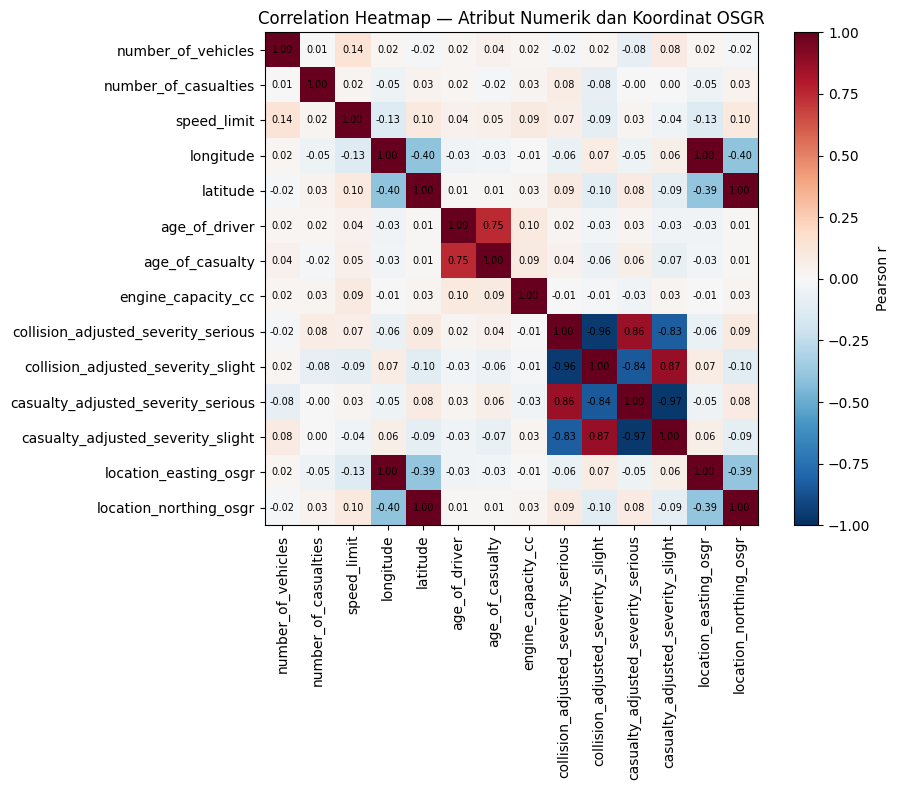

In [81]:
fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(corr_matrix.values, cmap='RdBu_r', vmin=-1, vmax=1)

ax.set_xticks(range(len(KOLOM_UNTUK_CORR)))
ax.set_yticks(range(len(KOLOM_UNTUK_CORR)))

ax.set_xticklabels(KOLOM_UNTUK_CORR, rotation=90)
ax.set_yticklabels(KOLOM_UNTUK_CORR)

for i in range(len(KOLOM_UNTUK_CORR)):
    for j in range(len(KOLOM_UNTUK_CORR)):
        ax.text(
            j, i,
            f"{corr_matrix.values[i, j]:.2f}",
            ha='center',
            va='center',
            fontsize=7
        )

plt.colorbar(im, label='Pearson r')

ax.set_title("Correlation Heatmap — Atribut Numerik dan Koordinat OSGR")

plt.tight_layout()
plt.show()

---

## 4.6 High-Correlation Pair Screening

Threshold yang digunakan adalah `|r| ≥ 0.80`. Threshold ini digunakan sebagai aturan screening untuk menemukan pasangan atribut yang memiliki korelasi tinggi dan menjadi kandidat redundansi.

Pasangan yang memenuhi threshold tidak langsung dihapus. Setiap pasangan akan diperiksa lebih lanjut pada Bagian 4.7 berdasarkan definisi atribut dan konteks datanya sebelum menentukan keputusan attribute selection.

In [82]:
def ambil_pasangan_unik(corr_df, threshold=0.0):
    """Mengambil pasangan atribut dari correlation matrix tanpa duplikasi (A-B dan B-A dihitung sebagai satu pasangan saja)."""
    pairs = []
    cols = corr_df.columns
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            r = corr_df.iloc[i, j]
            pairs.append({'Attribute A': cols[i], 'Attribute B': cols[j], 'Correlation': round(r, 4), 'Absolute Correlation': round(abs(r), 4)})
    hasil = pd.DataFrame(pairs).sort_values('Absolute Correlation', ascending=False).reset_index(drop=True)
    return hasil[hasil['Absolute Correlation'] >= threshold].reset_index(drop=True)

semua_pasangan = ambil_pasangan_unik(corr_matrix, threshold=0.0)
print(f"Total pasangan unik yang diperiksa: {len(semua_pasangan)}")

pasangan_tinggi = ambil_pasangan_unik(corr_matrix, threshold=0.80)
print(f"\nPasangan dengan |r| >= 0.80 (kandidat redundansi): {len(pasangan_tinggi)}")
pasangan_tinggi


Total pasangan unik yang diperiksa: 91

Pasangan dengan |r| >= 0.80 (kandidat redundansi): 8


,Attribute A,Attribute B,Correlation,Absolute Correlation
0,latitude,location_northing_osgr,1.0000,1.0000
1,longitude,location_easting_osgr,0.9995,0.9995
2,casualty_adjusted_severity_serious,casualty_adjusted_severity_slight,-0.9654,0.9654
3,collision_adjusted_severity_serious,collision_adjusted_severity_slight,-0.9584,0.9584
4,collision_adjusted_severity_slight,casualty_adjusted_severity_slight,0.8682,0.8682
5,collision_adjusted_severity_serious,casualty_adjusted_severity_serious,0.8607,0.8607
6,collision_adjusted_severity_slight,casualty_adjusted_severity_serious,-0.8382,0.8382
7,collision_adjusted_severity_serious,casualty_adjusted_severity_slight,-0.8266,0.8266


---

## 4.7 Redundancy Assessment

Setiap pasangan yang memenuhi threshold pada Bagian 4.6 diperiksa lebih lanjut berdasarkan:
1. definisi atribut pada Data Guide;
2. makna atau konsep yang diukur;
3. hubungan antar-atribut;
4. grain atau level data; dan
5. hasil korelasi.

Korelasi tinggi digunakan sebagai evidence awal untuk pemeriksaan redundansi, tetapi tidak digunakan sebagai satu-satunya dasar untuk menghapus atribut.

### Pasangan 1–2 — Koordinat Lokasi

| # | Pertanyaan pemeriksaan | Hasil pemeriksaan |
|---|---|---|
| 1 | Definisi di Data Guide | `longitude`, `latitude`, `location_easting_osgr`, dan `location_northing_osgr` merupakan atribut koordinat lokasi collision. Data Guide juga mencatat `Null if not known` untuk nilai yang tidak diketahui. |
| 2 | Makna atribut | `longitude` dan `latitude` menyatakan posisi geografis dalam koordinat geografis, sedangkan `location_easting_osgr` dan `location_northing_osgr` menyatakan posisi menggunakan grid OSGR. |
| 3 | Apakah merepresentasikan lokasi yang sama? | Ya. Keempat atribut digunakan untuk menyatakan lokasi collision yang sama, tetapi menggunakan sistem koordinat yang berbeda. |
| 4 | Apakah mengukur konsep yang sama? | Ya. Keempatnya merepresentasikan posisi geografis collision. |
| 5 | Apakah terdapat evidence kuantitatif? | Ya. Korelasi `longitude`–`location_easting_osgr` = `0.9995` dan `latitude`–`location_northing_osgr` = `0.99997` berdasarkan hasil correlation analysis pada Bagian 4.6. |
| 6 | Missing value pattern | Keempat kolom memiliki `4 NaN` pada baris yang sama berdasarkan pemeriksaan pada STAGE 2. |
| 7 | Kesimpulan redundansi | Kombinasi definisi atribut dan korelasi yang sangat tinggi menunjukkan bahwa koordinat OSGR memberikan informasi lokasi yang tumpang tindih dengan `longitude` dan `latitude`. |
| 8 | Decision | `location_easting_osgr` dan `location_northing_osgr` dikeluarkan dari `analytical feature set`. `longitude` dan `latitude` dipertahankan. |
| 9 | Perubahan pada `integrated_data` | Tidak ada. Kedua kolom OSGR tetap tersedia di `integrated_data` dan hanya dikeluarkan dari `analytical feature set`. |

### Pasangan 3–6 — Adjusted Severity

| # | Pertanyaan pemeriksaan | Hasil pemeriksaan |
|---|---|---|
| 1 | Definisi di Data Guide | Data Guide yang digunakan pada STAGE 2 tidak memberikan definisi atau formula eksplisit yang menjelaskan hubungan matematis antara keempat atribut adjusted severity tersebut. |
| 2 | Makna atribut | Nama atribut menunjukkan adanya pengukuran adjusted severity untuk kategori `serious` dan `slight`, tetapi hubungan formula antar-keempat atribut tidak dapat ditentukan hanya dari nama kolom. |
| 3 | Apakah satu atribut merupakan turunan langsung dari atribut lain? | Belum dapat dipastikan. Tidak terdapat formula atau definisi resmi yang cukup untuk menyatakan bahwa salah satu atribut merupakan turunan langsung dari atribut lainnya. |
| 4 | Apakah mengukur konsep yang sama? | Memiliki konteks yang berkaitan dengan severity, tetapi atribut `collision_adjusted_*` dan `casualty_adjusted_*` berada pada level data yang berbeda. Oleh karena itu, keduanya tidak dianggap sebagai atribut yang identik. |
| 5 | Perbedaan grain/konteks | `collision_adjusted_*` berada pada level collision, sedangkan `casualty_adjusted_*` berada pada level casualty. |
| 6 | Evidence kuantitatif | Korelasi antar-keempat atribut berada pada kisaran `-0.96` sampai `-0.83` berdasarkan hasil correlation analysis pada Bagian 4.6. |
| 7 | Apakah korelasi tinggi cukup untuk menyatakan redundan? | Tidak. Korelasi tinggi menunjukkan hubungan yang kuat, tetapi tidak dengan sendirinya membuktikan bahwa atribut memiliki informasi yang sama atau salah satunya dapat menggantikan yang lain. |
| 8 | Kesimpulan redundansi | Berdasarkan definisi yang tersedia dan perbedaan grain, belum terdapat evidence yang cukup untuk menyatakan bahwa salah satu atribut merupakan duplikat atau pengganti langsung atribut lainnya. |
| 9 | Decision | Keempat atribut tetap dipertahankan dalam `analytical feature set` pada STAGE 4 dan dapat dipertimbangkan kembali pada tahap STAGE 5 sesuai hasil analisis PCA. |

### Ringkasan Keputusan

| Kelompok atribut | Evidence utama | Keputusan |
|---|---|---|
| `location_easting_osgr` dan `location_northing_osgr` | Definisi sama-sama merepresentasikan lokasi collision + korelasi sangat tinggi dengan pasangan `longitude`/`latitude` | Exclude dari `analytical feature set` |
| `longitude` dan `latitude` | Merepresentasikan lokasi collision dan dipilih sebagai representasi koordinat yang digunakan dalam feature set | Keep |
| `collision_adjusted_*` dan `casualty_adjusted_*` | Korelasi tinggi, tetapi tidak ada definisi/formula yang cukup untuk menyatakan redundansi langsung dan grain berbeda | Keep |


---

## Analisis Covariance

Covariance dihitung sebagai analisis tambahan untuk melihat hubungan antar-atribut dalam skala aslinya.

Untuk menentukan redundansi, correlation tetap digunakan sebagai acuan utama karena nilainya telah dinormalisasi terhadap skala masing-masing atribut. Hasil covariance digunakan sebagai informasi pendukung dan tidak menjadi dasar tunggal untuk menghapus atribut.

In [83]:
cov_matrix = integrated_data[KOLOM_UNTUK_CORR].cov()
print("Covariance matrix (skala asli, belum distandardisasi):")
cov_matrix.round(2)


Covariance matrix (skala asli, belum distandardisasi):


,number_of_vehicles,number_of_casualties,speed_limit,longitude,latitude,age_of_driver,age_of_casualty,engine_capacity_cc,collision_adjusted_severity_serious,collision_adjusted_severity_slight,casualty_adjusted_severity_serious,casualty_adjusted_severity_slight,location_easting_osgr,location_northing_osgr
number_of_vehicles,0.71,0.02,1.75,0.02,-0.02,0.24,0.62,23.53,-0.01,0.01,-0.02,0.03,1.277840e+03,-2.077440e+03
number_of_casualties,0.02,15.33,1.48,-0.26,0.18,1.50,-2.07,178.90,0.13,-0.14,-0.01,0.01,-1.762514e+04,1.964020e+04
speed_limit,1.75,1.48,229.03,-2.57,1.93,11.59,15.30,2047.26,0.43,-0.61,0.17,-0.28,-1.778697e+05,2.150946e+05
longitude,0.02,-0.26,-2.57,1.84,-0.71,-0.83,-0.74,-11.05,-0.04,0.04,-0.03,0.03,1.257356e+05,-7.830322e+04
latitude,-0.02,0.18,1.93,-0.71,1.70,0.33,0.22,57.77,0.05,-0.06,0.04,-0.05,-4.768253e+04,1.889618e+05
age_of_driver,0.24,1.50,11.59,-0.83,0.33,300.26,261.39,2719.80,0.18,-0.24,0.19,-0.26,-5.643778e+04,3.698494e+04
age_of_casualty,0.62,-2.07,15.30,-0.74,0.22,261.39,390.00,2259.68,0.37,-0.49,0.47,-0.60,-5.040867e+04,2.429468e+04
engine_capacity_cc,23.53,178.90,2047.26,-11.05,57.77,2719.80,2259.68,2381547.28,-4.57,-6.23,-17.28,13.75,-7.726269e+05,6.407153e+06
collision_adjusted_severity_serious,-0.01,0.13,0.43,-0.04,0.05,0.18,0.37,-4.57,0.18,-0.18,0.15,-0.15,-2.491340e+03,5.683930e+03
collision_adjusted_severity_slight,0.01,-0.14,-0.61,0.04,-0.06,-0.24,-0.49,-6.23,-0.18,0.19,-0.15,0.16,2.912160e+03,-6.435520e+03


### Mengapa Covariance Tidak Digunakan sebagai Dasar Keputusan Redundansi?

Nilai covariance dipengaruhi oleh skala dan satuan variabel yang digunakan. Hal ini terlihat pada hasil di atas:

- covariance antara `longitude` dan `location_easting_osgr` dapat memiliki nilai yang besar karena `location_easting_osgr` menggunakan skala ratusan ribu meter, sedangkan `longitude` menggunakan skala derajat;
- covariance antara atribut `adjusted_severity` yang nilainya berada pada skala yang lebih kecil menghasilkan nilai yang lebih kecil.

Dengan demikian, magnitude covariance tidak dapat dibandingkan secara langsung antar-pasangan atribut yang memiliki skala atau satuan berbeda.

Correlation digunakan sebagai acuan utama untuk screening redundansi karena nilainya berada pada rentang `-1` sampai `1`, sehingga kekuatan hubungan antar-pasangan atribut dapat dibandingkan pada skala yang sama.

Covariance tetap dihitung dan disajikan sebagai analisis tambahan sesuai kebutuhan, tetapi tidak digunakan sebagai dasar tunggal dalam keputusan redundansi pada Bagian 4.7 dan 4.8.

---

## 4.8 Attribute Selection Decision

Tabel keputusan pada bagian ini dibuat berdasarkan daftar klasifikasi atribut pada Bagian 4.4, sehingga keputusan attribute selection dapat ditelusuri kembali ke hasil klasifikasi sebelumnya.

Keputusan juga mempertimbangkan hasil pemeriksaan redundansi pada Bagian 4.7. Atribut yang dikeluarkan hanya dikeluarkan dari `analytical feature set`, bukan dihapus dari `integrated_data`.

In [84]:
def buat_baris_keputusan(kolom_list, role, evidence, reason, decision):
    return [{'Attribute': k, 'Role': role, 'Evidence': evidence, 'Reason': reason, 'Decision': decision} for k in kolom_list]

baris = []
baris += buat_baris_keputusan(KEY_COLS, "Key/Identifier",
    "Sudah divalidasi unik pada grain masing-masing (STAGE 1 & 3)",
    "Diperlukan untuk menelusuri baris kembali ke collision/vehicle/casualty asal",
    "Keep as identifier/key")

baris += buat_baris_keputusan(ANALYTICAL_NUMERIC_KEPT, "Analytical numeric",
    "Numerik kontinu/count, tidak redundan berdasarkan pemeriksaan 4.7",
    "Relevan untuk correlation/PCA di STAGE 5",
    "Keep as analytical feature")

baris += buat_baris_keputusan(REDUNDANT_COORDINATE_COLS, "Analytical numeric (koordinat)",
    "Korelasi >= 0.999 dengan longitude/latitude (bagian 4.6); mengukur lokasi yang sama dalam sistem grid berbeda",
    "Redundan definisional dengan longitude/latitude yang dipertahankan",
    "Exclude from analytical feature set")

baris += buat_baris_keputusan(CONSTANT_COLS, "Constant / near-zero variation",
    "n_unique = 1 pada seluruh baris yang diperiksa (bagian 4.3)",
    "Tidak ada variasi nilai -> tidak ada informasi yang bisa dianalisis (bukan karena '-1' atau 'terlihat tidak penting')",
    "Exclude from analytical feature set")

baris += buat_baris_keputusan(REDUNDANT_DUPLICATE_COLS, "Redundant duplicate (hasil merge)",
    "Nilai identik dengan collision_ref_no_collision, dibuktikan lewat perbandingan langsung (bagian 4.4)",
    "Duplikat murni akibat proses merge STAGE 3, tidak menambah informasi baru",
    "Exclude from analytical feature set")

baris += buat_baris_keputusan(ADMINISTRATIVE_COLS, "Administrative",
    "Kode wilayah/instansi/referensi/teks (definisi Data Guide atau struktur data), bukan variabel analitis kontinu",
    "Bukan identifier utama, bukan pula fitur numerik yang bermakna kuantitas",
    "Exclude from analytical feature set")

baris += buat_baris_keputusan(CATEGORICAL_CODED_COLS, "Categorical/coded",
    "Memiliki daftar kode resmi di Data Guide (DfT), nilai integer hanya label kategori",
    "Bukan variabel kontinu -- tidak tepat dianalisis dengan Pearson correlation tanpa encoding lebih lanjut",
    "Exclude from analytical feature set")

tabel_keputusan = pd.DataFrame(baris)
print(f"Total baris pada decision table: {len(tabel_keputusan)} (harus sama dengan jumlah kolom integrated_data: {integrated_data.shape[1]})")
tabel_keputusan['Decision'].value_counts()


Total baris pada decision table: 96 (harus sama dengan jumlah kolom integrated_data: 96)


Decision
Exclude from analytical feature set    81
Keep as analytical feature             12
Keep as identifier/key                  3
Name: count, dtype: int64

In [85]:
# Ringkasan keputusan untuk klaster adjusted severity berdasarkan hasil Bagian 4.7.
# Dicatat terpisah karena keempat atribut memiliki korelasi tinggi,
# tetapi belum terdapat evidence yang cukup untuk menyatakan bahwa atribut-atribut tersebut redundan.
catatan_klaster = pd.DataFrame([
    {
        "Attribute": "collision_adjusted_severity_serious / _slight, "
                     "casualty_adjusted_severity_serious / _slight",
        "Role": "Analytical numeric (klaster berkorelasi tinggi)",
        "Evidence": "Korelasi antar-keempat atribut berada pada kisaran -0.96 sampai -0.83 (Bagian 4.6)",
        "Reason": "Data Guide tidak memberikan formula yang cukup untuk menyatakan bahwa salah satu atribut merupakan turunan langsung dari atribut lainnya, dan keempat atribut memiliki konteks/grain yang berbeda",
        "Decision": "Keep as analytical feature; dipertimbangkan kembali pada STAGE 5"
    },
])

catatan_klaster

,Attribute,Role,Evidence,Reason,Decision
0,"collision_adjusted_severity_serious / _slight,...",Analytical numeric (klaster berkorelasi tinggi),Korelasi antar-keempat atribut berada pada kis...,Data Guide tidak memberikan formula yang cukup...,Keep as analytical feature; dipertimbangkan ke...


### Ringkasan Keputusan

Jumlah berikut merupakan keputusan attribute selection pada STAGE 4. Perbandingan jumlah atribut sebelum dan sesudah selection akan dihitung kembali pada Bagian 4.10.

- **Keep as identifier/key:** 3 atribut
- **Keep as analytical feature:** 12 atribut, termasuk 4 atribut pada klaster `adjusted_severity` yang tetap dipertahankan.
- **Exclude from analytical feature set:** atribut lainnya, termasuk atribut constant, redundant, administrative, categorical/coded, serta koordinat OSGR.

Tidak ada atribut yang dihapus dari `integrated_data`. Seluruh 96 kolom tetap tersedia pada dataset utama.

Exclusion hanya diterapkan pada pembentukan `X_selected`, sehingga jumlah atribut yang digunakan sebagai feature untuk STAGE 5 menjadi lebih sedikit daripada jumlah atribut pada `integrated_data`.

---

## 4.9 Selected Feature Set

`X_selected` dibuat sebagai dataframe baru tanpa mengubah `integrated_data`.

`X_selected` berisi:
- 3 atribut key/identifier untuk keperluan penelusuran data; dan
- 12 analytical feature yang dipertahankan berdasarkan hasil evaluasi pada Bagian 4.7–4.8.

Atribut yang dikeluarkan dari analytical feature set tidak dimasukkan ke dalam `X_selected`, tetapi tetap tersedia di `integrated_data`.

In [86]:
KOLOM_X_SELECTED = KEY_COLS + ANALYTICAL_NUMERIC_KEPT
X_selected = integrated_data[KOLOM_X_SELECTED].copy()

print("X_selected shape:", X_selected.shape)
print("Kolom pada X_selected:", list(X_selected.columns))
print("\nintegrated_data tidak diubah, shape-nya tetap:", integrated_data.shape)


X_selected shape: (200247, 15)
Kolom pada X_selected: ['collision_index', 'vehicle_reference', 'casualty_reference', 'number_of_vehicles', 'number_of_casualties', 'speed_limit', 'longitude', 'latitude', 'age_of_driver', 'age_of_casualty', 'engine_capacity_cc', 'collision_adjusted_severity_serious', 'collision_adjusted_severity_slight', 'casualty_adjusted_severity_serious', 'casualty_adjusted_severity_slight']

integrated_data tidak diubah, shape-nya tetap: (200247, 96)


---
## 4.10 Before vs After

In [87]:
tabel_before_after_stage4 = pd.DataFrame([
    {"Tahap": "integrated_data (STAGE 3, seluruh atribut)", "Rows": integrated_data.shape[0], "Columns": integrated_data.shape[1]},
    {"Tahap": "X_selected (analytical feature set STAGE 4)", "Rows": X_selected.shape[0], "Columns": X_selected.shape[1]},
])
tabel_before_after_stage4


,Tahap,Rows,Columns
0,"integrated_data (STAGE 3, seluruh atribut)",200247,96
1,X_selected (analytical feature set STAGE 4),200247,15


Jumlah baris tetap jumlah baris aktual sebelum dan sesudah feature selection. Feature selection hanya mengurangi jumlah atribut, dari 96 kolom pada `integrated_data` menjadi 15 kolom pada `X_selected`, yang terdiri dari 3 key/identifier dan 12 analytical feature.

Tidak ada baris yang dihapus pada proses ini.

---
## 4.11 Validation

### Data Integrity

In [88]:
print("Row count sebelum (integrated_data):", integrated_data.shape[0])
print("Row count sesudah (X_selected)      :", X_selected.shape[0])
print("Sama?", integrated_data.shape[0] == X_selected.shape[0])

dup_key_X = X_selected.duplicated(subset=['collision_index', 'vehicle_reference', 'casualty_reference']).sum()
print("\nDuplicate key pada X_selected:", dup_key_X)

print("\nintegrated_data masih punya 96 kolom (tidak berubah)?", integrated_data.shape[1] == 96)
print("vehicle_casualty (hasil STAGE 3) masih utuh (tidak overwrite)?", 'vehicle_casualty' in dir() and vehicle_casualty.shape[0] == integrated_data.shape[0])


Row count sebelum (integrated_data): 200247
Row count sesudah (X_selected)      : 200247
Sama? True

Duplicate key pada X_selected: 0

integrated_data masih punya 96 kolom (tidak berubah)? True
vehicle_casualty (hasil STAGE 3) masih utuh (tidak overwrite)? True


### Attribute Selection

- Setiap atribut yang dikeluarkan dari `X_selected` memiliki evidence dan alasan yang tercatat pada tabel keputusan di Bagian 4.8. Tidak ada atribut yang dikeluarkan tanpa dasar pemeriksaan.

- Korelasi tinggi pada `location_easting_osgr`/`location_northing_osgr` digunakan sebagai screening untuk menemukan kandidat redundansi. Keputusan exclude dibuat setelah hasil korelasi diperiksa bersama definisi dan konteks atribut pada Bagian 4.7, bukan berdasarkan threshold korelasi saja.

- Klaster `adjusted_severity` juga memiliki korelasi tinggi, tetapi tetap dipertahankan karena belum terdapat evidence yang cukup untuk menyatakan bahwa atribut-atribut tersebut redundan. Hal ini menunjukkan bahwa threshold korelasi tidak digunakan sebagai aturan otomatis untuk menghapus atribut.

- Key/identifier (`collision_index`, `vehicle_reference`, `casualty_reference`) tetap tersedia di `X_selected` untuk keperluan penelusuran data dan tidak diperlakukan sebagai analytical feature dalam correlation analysis.

- `CATEGORICAL_CODED_COLS` tidak dimasukkan ke dalam Pearson correlation pada Stage 4 karena kelompok tersebut diklasifikasikan sebagai categorical/coded, bukan sebagai analytical numeric features.

### Reproducibility

- Metode correlation (`Pearson`) dan threshold screening (`|r| ≥ 0.80`) ditulis secara eksplisit pada Bagian 4.5–4.6.

- Daftar atribut yang digunakan dalam correlation analysis (`KOLOM_UNTUK_CORR`) dan daftar atribut yang dipilih (`KOLOM_X_SELECTED`) disimpan sebagai variabel Python yang dapat diperiksa kembali.

- Keputusan attribute selection pada Bagian 4.8 dibentuk berdasarkan daftar Python seperti `KEY_COLS`, `ANALYTICAL_NUMERIC_KEPT`, dan daftar kelompok atribut lainnya, sehingga tidak bergantung pada pengetikan ulang nama kolom secara manual.

---

# 4.12 STAGE 4 VALIDATION GATE

### Self-check

- Pearson correlation hanya dilakukan pada atribut yang telah ditetapkan dalam `KOLOM_UNTUK_CORR`, yaitu analytical numeric features dan kolom koordinat OSGR yang ikut dimasukkan untuk pemeriksaan redundansi.

- Categorical/coded attributes tidak dimasukkan ke dalam Pearson correlation karena tidak termasuk dalam `ANALYTICAL_NUMERIC_KEPT`.

- Identifier/key (`collision_index`, `vehicle_reference`, `casualty_reference`) dipisahkan dari analytical features.

- Threshold correlation (`|r| ≥ 0.80`) ditetapkan secara eksplisit pada Bagian 4.6 sebagai screening rule.

- High correlation digunakan sebagai evidence untuk screening kandidat redundansi, bukan sebagai aturan otomatis untuk menghapus atribut.

- Klaster `adjusted_severity` tetap dipertahankan meskipun memiliki korelasi tinggi karena belum terdapat evidence yang cukup untuk menyatakan bahwa atribut-atribut tersebut redundan.

- Setiap atribut yang dikeluarkan dari `X_selected` memiliki alasan dan evidence yang dicatat pada decision table di Bagian 4.8.

- Definisi atribut diperiksa menggunakan Data Guide pada kasus yang memiliki informasi pendukung. Untuk klaster `adjusted_severity`, keterbatasan dokumentasi Data Guide dicatat secara eksplisit.

- Tidak dilakukan cleaning, integration, atau PCA baru pada STAGE 4. Setup hanya menyiapkan data berdasarkan keputusan STAGE 2–3 satu kali sebelum analisis STAGE 4.

- Jumlah baris `X_selected` tetap jumlah baris aktual berdasarkan pemeriksaan pada Bagian 4.11.

- Tidak terdapat row multiplication pada STAGE 4 karena tidak dilakukan merge baru.

- `integrated_data` tidak diubah atau di-overwrite. Dataset utama tetap memiliki 96 kolom.

- Hasil dan keputusan pada STAGE 4 dapat direproduksi dari kode yang terdapat pada notebook.

---

## STAGE 4 STATUS: GO TO STAGE 5

### Kesimpulan

Seluruh 96 atribut pada `integrated_data` telah diklasifikasikan dan dievaluasi berdasarkan hasil profiling, Data Guide, correlation analysis, dan pemeriksaan redundansi.

Atribut yang dikeluarkan dari `X_selected` memiliki alasan yang dicatat pada decision table. Koordinat OSGR dikeluarkan dari analytical feature set setelah diperiksa berdasarkan definisi atribut dan hasil korelasi dengan `longitude` dan `latitude`. Atribut yang memiliki korelasi tinggi tidak otomatis dikeluarkan; hal ini terlihat pada klaster `adjusted_severity` yang tetap dipertahankan karena belum terdapat evidence yang cukup untuk menyatakan redundansi.

`integrated_data` tetap dipertahankan dalam bentuk aslinya dengan 96 kolom. Feature selection hanya menghasilkan dataframe baru, yaitu `X_selected`, tanpa menghapus baris atau mengubah dataset utama.

`X_selected` memiliki seluruh baris dan 15 kolom, yang terdiri dari 3 key/identifier dan 12 analytical feature. Dataset ini dapat digunakan sebagai input untuk STAGE 5 (PCA & Dimensionality Reduction).

---

## Ringkasan STAGE 4 (untuk laporan/PPT)

### STAGE 4 — Redundancy Analysis & Attribute Selection

### Tujuan

Memeriksa atribut yang memiliki informasi tumpang tindih dan menentukan `analytical feature set` yang akan digunakan pada Stage 5, tanpa menghapus atribut dari dataset utama.

### Analisis

- 12 analytical numeric features dianalisis menggunakan Pearson correlation. Dua atribut koordinat OSGR juga dimasukkan sebagai pembanding untuk memeriksa redundansinya dengan `longitude` dan `latitude`.
- Threshold screening yang digunakan adalah `|r| ≥ 0.80`.
- Ditemukan 6 pasangan atribut dengan korelasi tinggi:
  - 2 pasangan koordinat antara `longitude`/`latitude` dan koordinat OSGR.
  - 4 pasangan pada klaster `adjusted_severity`.
- Korelasi tinggi digunakan sebagai screening untuk menemukan kandidat redundansi, bukan sebagai aturan otomatis untuk menghapus atribut.

### Keputusan

- 12 analytical features dipertahankan:
  `number_of_vehicles`, `number_of_casualties`, `speed_limit`, `longitude`, `latitude`, `age_of_driver`, `age_of_casualty`, `engine_capacity_cc`, `collision_adjusted_severity_serious`, `collision_adjusted_severity_slight`, `casualty_adjusted_severity_serious`, dan `casualty_adjusted_severity_slight`.

- `location_easting_osgr` dan `location_northing_osgr` dikeluarkan dari analytical feature set karena merepresentasikan informasi lokasi yang tumpang tindih dengan `longitude` dan `latitude`, serta memiliki korelasi yang sangat tinggi dengan pasangan tersebut.

- 5 atribut konstan dikeluarkan dari analytical feature set karena tidak memiliki variasi pada data.

- 2 atribut duplikat hasil merge dikeluarkan karena tidak memberikan informasi baru dibandingkan atribut yang sudah tersedia.

- 13 atribut administratif dan 59 atribut categorical/coded tidak dimasukkan ke dalam analytical feature set karena tidak termasuk dalam fitur numerik yang digunakan untuk correlation analysis dan Stage 5.

- Keputusan attribute selection tidak menghapus kolom dari `integrated_data`. Atribut yang dikeluarkan hanya tidak dimasukkan ke dalam `X_selected`.

### Validasi

- Jumlah baris tetap jumlah baris aktual pada `integrated_data` dan `X_selected`.
- `X_selected` memiliki 15 kolom yang terdiri dari 3 key/identifier dan 12 analytical features.
- Key (`collision_index`, `vehicle_reference`, `casualty_reference`) tetap tersedia di `X_selected` untuk keperluan penelusuran data.
- Tidak dilakukan merge baru pada Stage 4 sehingga tidak terdapat row multiplication akibat integration.
- `integrated_data` tetap memiliki 96 kolom dan tidak di-overwrite.
- Seluruh keputusan attribute selection dapat ditelusuri melalui daftar atribut dan kode yang digunakan pada Stage 4.

# STAGE 5 — PCA & Dimensionality Reduction

STAGE 5 menggunakan `X_selected` hasil STAGE 4 di atas. Tidak ada pengulangan cleaning, integration, atau attribute selection.


In [89]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

---

## 5.2 Input Audit

### 5.3 PCA Feature Matrix

`X_pca_input` dibuat hanya dari 12 analytical feature yang telah dipilih pada Stage 4.

Kolom key/identifier (`collision_index`, `vehicle_reference`, `casualty_reference`) tidak dimasukkan ke dalam PCA karena digunakan untuk identifikasi dan penelusuran data, bukan sebagai analytical feature.

Kolom koordinat OSGR (`location_easting_osgr` dan `location_northing_osgr`) juga tidak dimasukkan karena pada Stage 4 telah dikeluarkan dari analytical feature set berdasarkan hasil pemeriksaan redundansi dengan `longitude` dan `latitude`.

Dengan demikian, `X_pca_input` berisi 12 analytical feature yang menjadi input PCA.

In [90]:
X_pca_input = X_selected[ANALYTICAL_NUMERIC_KEPT].copy()

print("X_pca_input shape:", X_pca_input.shape)
print("\nData type setiap fitur:")
print(X_pca_input.dtypes)


X_pca_input shape: (200247, 12)

Data type setiap fitur:
number_of_vehicles                       int64
number_of_casualties                     int64
speed_limit                              int64
longitude                              float64
latitude                               float64
age_of_driver                          float64
age_of_casualty                        float64
engine_capacity_cc                     float64
collision_adjusted_severity_serious    float64
collision_adjusted_severity_slight     float64
casualty_adjusted_severity_serious     float64
casualty_adjusted_severity_slight      float64
dtype: object


In [91]:
print("Jumlah missing value setiap fitur:")
print(X_pca_input.isna().sum())

print("\nJumlah infinite value setiap fitur:")
print(np.isinf(X_pca_input.select_dtypes(include=[np.number])).sum())

print("\nVariance setiap fitur (skala asli, belum distandardisasi):")
print(X_pca_input.var().round(3))

print("\nApakah semua fitur numerik?", all(pd.api.types.is_numeric_dtype(X_pca_input[c]) for c in X_pca_input.columns))


Jumlah missing value setiap fitur:
number_of_vehicles                         0
number_of_casualties                       0
speed_limit                                0
longitude                                  4
latitude                                   4
age_of_driver                          28651
age_of_casualty                        75105
engine_capacity_cc                     46569
collision_adjusted_severity_serious        0
collision_adjusted_severity_slight         0
casualty_adjusted_severity_serious     72364
casualty_adjusted_severity_slight      72364
dtype: int64

Jumlah infinite value setiap fitur:
number_of_vehicles                     0
number_of_casualties                   0
speed_limit                            0
longitude                              0
latitude                               0
age_of_driver                          0
age_of_casualty                        0
engine_capacity_cc                     0
collision_adjusted_severity_serious    0
collis

### Evaluasi Hasil Audit (Evidence → Analysis)

**Temuan:**

Dari 12 analytical feature yang akan digunakan sebagai input PCA, ditemukan missing value pada 7 fitur:

- `longitude` dan `latitude`: masing-masing 4 NaN, yang sudah ditemukan sejak Stage 2.
- `age_of_driver`: 28.651 NaN.
- `engine_capacity_cc`: 46.569 NaN.
- `age_of_casualty`: 75.105 NaN.
- `casualty_adjusted_severity_serious`: jumlah baris vehicle tanpa casualty yang dihitung aktual NaN.
- `casualty_adjusted_severity_slight`: jumlah baris vehicle tanpa casualty yang dihitung aktual NaN.

Tidak ditemukan infinite value. Seluruh 12 fitur memiliki tipe data numerik dan tidak terdapat fitur dengan variance nol berdasarkan pemeriksaan pada Stage 4.

**Sumber Missing Value (mengikuti hasil Stage 2 dan Stage 3):**

- `longitude` dan `latitude`: NaN sudah terdapat sejak Stage 2. Data Guide menyatakan bahwa nilai tersebut dapat bernilai `Null if not known`.
- `age_of_driver` dan `engine_capacity_cc`: NaN berasal dari konversi `-1 → NaN` pada Stage 2 setelah kode `-1` diverifikasi sebagai `Data missing or out of range`.
- `age_of_casualty`, `casualty_adjusted_severity_serious`, dan `casualty_adjusted_severity_slight`: NaN muncul pada hasil integration Stage 3 untuk baris vehicle yang tidak memiliki casualty, sehingga kolom casualty pada baris tersebut bernilai NaN. Kondisi ini merupakan konsekuensi dari grain `integrated_data` dan penggunaan left merge yang telah didokumentasikan pada Stage 3.

**Masalah:**

PCA membutuhkan matriks input numerik yang lengkap. Baris yang masih mengandung `NaN` tidak dapat langsung digunakan sebagai input PCA.

Pada tahap ini tidak dilakukan:

- penghapusan baris tanpa dokumentasi karena hanya untuk membuat PCA dapat berjalan;
- imputasi nilai tanpa dasar atau justifikasi yang memadai;
- perubahan kembali terhadap keputusan cleaning `-1` pada Stage 2;
- perubahan terhadap keputusan integration pada Stage 3.

Khusus untuk atribut `*_adjusted_severity_*`, tidak tersedia definisi atau formula yang cukup pada Data Guide untuk menjadi dasar imputasi nilai yang hilang. Hal ini telah dicatat pada Stage 4.

**Keputusan (Evidence-Based):**

Karena PCA membutuhkan matriks tanpa NaN dan tidak terdapat dasar yang cukup untuk menentukan nilai pengganti secara bertanggung jawab, PCA dilakukan menggunakan **complete-case analysis**, yaitu hanya baris yang memiliki nilai lengkap pada seluruh 12 analytical feature.

Pembatasan ini bukan perubahan terhadap `integrated_data`. `integrated_data` tetap dipertahankan secara utuh. Complete-case hanya digunakan untuk membentuk matriks input PCA.

Jumlah baris yang memenuhi kriteria complete-case akan dihitung secara eksplisit sebelum PCA dan dilaporkan bersama persentase cakupannya. Dengan demikian, dampak missing value terhadap cakupan analisis dapat diketahui dan keputusan penggunaan subset data dapat ditelusuri.

In [92]:
mask_lengkap = X_pca_input.notna().all(axis=1)
X_pca_ready = X_pca_input.loc[mask_lengkap].copy()

n_total = len(X_pca_input)
n_lengkap = len(X_pca_ready)
n_hilang = n_total - n_lengkap

print(f"Total baris X_pca_input          : {n_total}")
print(f"Baris lengkap (X_pca_ready)      : {n_lengkap} ({n_lengkap/n_total*100:.2f}%)")
print(f"Baris tidak lengkap (dikeluarkan dari PCA saja, tidak dihapus dari X_selected/integrated_data): {n_hilang} ({n_hilang/n_total*100:.2f}%)")

# breakdown penyebab utama
mask_tanpa_casualty = X_selected['casualty_reference'].isna()
print(f"\nDari {n_hilang} baris yang tidak lengkap:")
print(f"  - {mask_tanpa_casualty.sum()} baris ({mask_tanpa_casualty.sum()/n_hilang*100:.1f}%) adalah baris 'vehicle tanpa casualty' (grain campuran STAGE 3, bukan missing yang perlu diperbaiki)")
print(f"  - {n_hilang - mask_tanpa_casualty.sum()} baris sisanya tidak lengkap karena kombinasi -1/NaN pada age_of_driver, age_of_casualty, atau engine_capacity_cc meski casualty-nya ada")


Total baris X_pca_input          : 200247
Baris lengkap (X_pca_ready)      : 92164 (46.03%)
Baris tidak lengkap (dikeluarkan dari PCA saja, tidak dihapus dari X_selected/integrated_data): 108083 (53.97%)

Dari 108083 baris yang tidak lengkap:
  - 72364 baris (67.0%) adalah baris 'vehicle tanpa casualty' (grain campuran STAGE 3, bukan missing yang perlu diperbaiki)
  - 35719 baris sisanya tidak lengkap karena kombinasi -1/NaN pada age_of_driver, age_of_casualty, atau engine_capacity_cc meski casualty-nya ada


### Catatan Cakupan PCA

PCA pada Stage 5 dilakukan menggunakan jumlah baris complete-case dari keseluruhan baris `integrated_data`, atau sebesar persentase coverage aktual dari keseluruhan baris.

baris complete-case tersebut merupakan baris yang memiliki data lengkap pada seluruh 12 analytical feature yang digunakan sebagai input PCA (complete-case).

Dengan demikian, hasil PCA pada Stage 5 merepresentasikan subset data dengan kelengkapan data pada ke-12 analytical feature, bukan seluruh seluruh baris `integrated_data`.

Pembatasan ini hanya berlaku pada perhitungan PCA. `integrated_data` dan `X_selected` tidak diubah, sehingga tetap memiliki:
- `integrated_data`: seluruh baris × 96 kolom
- `X_selected`: seluruh baris × 15 kolom

Baris yang tidak memenuhi kriteria complete-case tidak dihapus dari dataset dan tetap tersedia pada `integrated_data` maupun `X_selected`.

---

### Mengapa Identifier Tidak Masuk PCA

`collision_index`, `vehicle_reference`, dan `casualty_reference` tidak digunakan sebagai input PCA karena ketiganya berfungsi sebagai identifier/key untuk mengidentifikasi dan menelusuri baris kembali ke observasi aslinya (traceability), bukan sebagai variabel analitis yang merepresentasikan karakteristik dari collision, vehicle, atau casualty.

Jika identifier dimasukkan ke PCA, variasi numeriknya akan diperlakukan sebagai informasi analitis, padahal angka tersebut hanya berfungsi sebagai kode atau identitas observasi dan tidak memiliki makna kuantitatif yang sesuai untuk dianalisis menggunakan PCA.

Identifier tetap dipertahankan secara terpisah agar hasil PCA dapat ditelusuri kembali ke baris atau observasi aslinya (lihat Bagian 5.14).

---

## 5.4 Feature Scale Assessment

Sebelum PCA dilakukan, skala masing-masing analytical feature diperiksa terlebih dahulu menggunakan `X_pca_ready`, yaitu subset complete-case yang memiliki nilai lengkap pada seluruh 12 analytical feature.

Pemeriksaan ini dilakukan untuk melihat perbedaan rentang dan satuan antar-feature sebelum menentukan preprocessing yang diperlukan untuk PCA.

In [93]:
skala_fitur = X_pca_ready.agg(['mean', 'std', 'min', 'max']).T
skala_fitur


,mean,std,min,max
number_of_vehicles,1.926023,0.785749,1.00000,17.00000
number_of_casualties,1.973938,5.670716,1.00000,142.00000
speed_limit,39.596263,15.679883,20.00000,70.00000
longitude,-1.326050,1.414292,-7.41772,1.75559
latitude,52.441992,1.355713,49.91303,60.34525
age_of_driver,41.967059,17.740095,4.00000,98.00000
age_of_casualty,39.277570,20.026425,0.00000,100.00000
engine_capacity_cc,1586.875971,1217.379980,1.00000,16400.00000
collision_adjusted_severity_serious,0.273944,0.439410,0.00000,1.00000
collision_adjusted_severity_slight,0.703759,0.450183,0.00000,1.00000


**Kesimpulan:**

Skala dan satuan antar-feature berbeda cukup jauh. Misalnya, `engine_capacity_cc` dapat mencapai puluhan ribu, sedangkan `collision_adjusted_severity_serious`/`slight` berada pada rentang 0–1 dan `longitude`/`latitude` berada pada skala puluhan derajat.

Karena PCA menentukan principal component berdasarkan variance, feature dengan skala yang lebih besar dapat memberikan pengaruh yang lebih besar terhadap hasil PCA jika data tidak distandardisasi terlebih dahulu.

Oleh karena itu, standardization dilakukan sebelum PCA agar setiap feature berada pada skala yang sebanding.

---

## 5.5 Standardization

`sklearn.decomposition.PCA` melakukan centering secara otomatis dengan mengurangi mean setiap feature, tetapi tidak melakukan scaling. Karena pada Bagian 5.4 terlihat bahwa setiap feature memiliki skala dan satuan yang berbeda, `StandardScaler` digunakan sebelum PCA.

Standardization mengubah setiap feature sehingga memiliki mean mendekati 0 dan standar deviasi 1. Dengan demikian, PCA tidak didominasi oleh feature tertentu hanya karena memiliki skala atau satuan yang lebih besar.

`whiten=True` tidak digunakan pada tahap ini. PCA digunakan untuk dimensionality reduction dan analisis explained variance, sehingga output PCA dipertahankan dalam bentuk principal component tanpa whitening.

In [94]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_pca_ready)
print("X_scaled shape:", X_scaled.shape)


X_scaled shape: (92164, 12)


---
## 5.6 Standardization Validation

In [95]:
mean_setelah = X_scaled.mean(axis=0)
std_setelah = X_scaled.std(axis=0)

validasi_scaling = pd.DataFrame({
    'Fitur': ANALYTICAL_NUMERIC_KEPT,
    'Mean sesudah scaling': np.round(mean_setelah, 6),
    'Std sesudah scaling': np.round(std_setelah, 6),
})
print(validasi_scaling)

print(f"\nShape sebelum scaling: {X_pca_ready.shape} | sesudah scaling: {X_scaled.shape}")
print("Rows sama?", X_pca_ready.shape[0] == X_scaled.shape[0])
print("Jumlah fitur tetap 12?", X_scaled.shape[1] == 12)
print("Semua mean mendekati 0?", np.allclose(mean_setelah, 0, atol=1e-6))
print("Semua std mendekati 1?", np.allclose(std_setelah, 1, atol=1e-6))


                                  Fitur  Mean sesudah scaling  Std sesudah scaling
0                    number_of_vehicles                   0.0                  1.0
1                  number_of_casualties                  -0.0                  1.0
2                           speed_limit                   0.0                  1.0
3                             longitude                  -0.0                  1.0
4                              latitude                  -0.0                  1.0
5                         age_of_driver                  -0.0                  1.0
6                       age_of_casualty                   0.0                  1.0
7                    engine_capacity_cc                  -0.0                  1.0
8   collision_adjusted_severity_serious                   0.0                  1.0
9    collision_adjusted_severity_slight                   0.0                  1.0
10   casualty_adjusted_severity_serious                  -0.0                  1.0
11  

---

## 5.7 Full PCA

PCA dijalankan terlebih dahulu dengan seluruh 12 analytical feature sehingga menghasilkan 12 principal component.

Tahap ini dilakukan untuk melihat explained variance dan cumulative explained variance dari setiap principal component sebelum menentukan jumlah komponen yang digunakan pada tahap berikutnya.

Jumlah komponen final tidak ditentukan langsung pada tahap ini, tetapi dipilih berdasarkan hasil evaluasi explained variance.

In [96]:
pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)

print("Jumlah komponen dari PCA penuh:", pca_full.n_components_)
print("Shape hasil PCA penuh:", X_pca_full.shape)


Jumlah komponen dari PCA penuh: 12
Shape hasil PCA penuh: (92164, 12)


---
## 5.8 Explained Variance Analysis

In [97]:
eigenvalue = pca_full.explained_variance_
evr = pca_full.explained_variance_ratio_
cum_evr = np.cumsum(evr)

tabel_variance = pd.DataFrame({
    'PC': [f'PC{i+1}' for i in range(len(evr))],
    'Eigenvalue': np.round(eigenvalue, 4),
    'Explained Variance Ratio': np.round(evr, 4),
    'Cumulative Explained Variance': np.round(cum_evr, 4),
})
tabel_variance


,PC,Eigenvalue,Explained Variance Ratio,Cumulative Explained Variance
0,PC1,3.6408,0.3034,0.3034
1,PC2,1.7640,0.1470,0.4504
2,PC3,1.3963,0.1164,0.5668
3,PC4,1.1166,0.0930,0.6598
4,PC5,1.0409,0.0867,0.7465
5,PC6,0.9561,0.0797,0.8262
6,PC7,0.8119,0.0677,0.8939
7,PC8,0.6147,0.0512,0.9451
8,PC9,0.2968,0.0247,0.9698
9,PC10,0.2679,0.0223,0.9922


---
## 5.9 Scree Plot & 5.10 Cumulative Explained Variance Plot

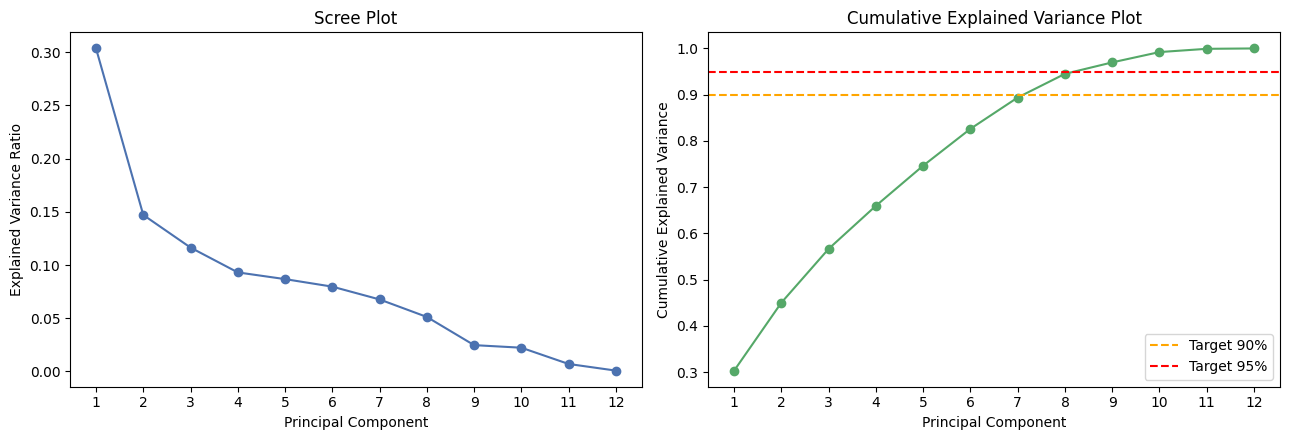

In [98]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# A. Scree plot
axes[0].plot(range(1, len(evr) + 1), evr, marker='o', color='#4C72B0')
axes[0].set_xlabel("Principal Component")
axes[0].set_ylabel("Explained Variance Ratio")
axes[0].set_title("Scree Plot")
axes[0].set_xticks(range(1, len(evr) + 1))

# B. Cumulative explained variance plot
axes[1].plot(range(1, len(cum_evr) + 1), cum_evr, marker='o', color='#55A868')
axes[1].axhline(0.90, color='orange', linestyle='--', label='Target 90%')
axes[1].axhline(0.95, color='red', linestyle='--', label='Target 95%')
axes[1].set_xlabel("Principal Component")
axes[1].set_ylabel("Cumulative Explained Variance")
axes[1].set_title("Cumulative Explained Variance Plot")
axes[1].set_xticks(range(1, len(cum_evr) + 1))
axes[1].legend()

plt.tight_layout()
plt.show()


**Interpretasi Scree Plot:**

Penurunan explained variance dari PC1 ke PC2 terlihat cukup tajam. Setelah PC2, penurunannya menjadi lebih landai dan tidak terlihat titik *elbow* yang tajam.

Pola ini menunjukkan bahwa variance tidak terkonsentrasi hanya pada beberapa principal component pertama, tetapi masih tersebar pada beberapa komponen berikutnya. Oleh karena itu, jumlah komponen final perlu ditentukan dengan mempertimbangkan cumulative explained variance, bukan hanya berdasarkan scree plot.

## 5.11 Component Selection

Kaiser criterion (`eigenvalue > 1`) digunakan sebagai informasi tambahan untuk melihat principal component yang menjelaskan variance lebih besar daripada variance satu fitur awal setelah standardization.

Namun, kriteria utama dalam menentukan jumlah komponen adalah cumulative explained variance, karena tujuan PCA pada tahap ini adalah mengurangi jumlah dimensi sambil mempertahankan proporsi variance yang ditargetkan.

Jumlah principal component final ditentukan berdasarkan hasil cumulative explained variance.

In [99]:
targets = [0.90, 0.95]
print("Jumlah komponen minimum untuk mencapai target cumulative explained variance:")
for target in targets:
    n_components = int(np.argmax(cum_evr >= target) + 1)
    print(f"  Target {target*100:.0f}% -> butuh {n_components} komponen (cumulative aktual: {cum_evr[n_components-1]*100:.2f}%)")

# Info tambahan: Kaiser criterion (HANYA sebagai informasi, bukan dasar keputusan)
n_kaiser = int((eigenvalue > 1).sum())
print(f"\n(Informasi tambahan, bukan dasar keputusan) Kaiser criterion (eigenvalue > 1): {n_kaiser} komponen")


Jumlah komponen minimum untuk mencapai target cumulative explained variance:
  Target 90% -> butuh 8 komponen (cumulative aktual: 94.51%)
  Target 95% -> butuh 9 komponen (cumulative aktual: 96.98%)

(Informasi tambahan, bukan dasar keputusan) Kaiser criterion (eigenvalue > 1): 5 komponen


**Keputusan Jumlah Komponen Final**

Jumlah komponen final dipilih sebagai jumlah minimum yang mencapai target cumulative explained variance 90%. Target 95% digunakan sebagai pembanding.

Aturan ini membuat keputusan jumlah PC berasal langsung dari `cum_evr` hasil PCA, bukan dari angka yang ditulis manual. Hasil aktual ditampilkan pada cell berikutnya.


---
## 5.12 Final PCA

In [100]:
# Pilih jumlah komponen minimum yang mencapai target cumulative explained variance 90%.
TARGET_CUM_VARIANCE = 0.90
N_COMPONENTS_FINAL = int(np.argmax(cum_evr >= TARGET_CUM_VARIANCE) + 1)

print(f"Target cumulative explained variance: {TARGET_CUM_VARIANCE*100:.0f}%")
print(f"Jumlah komponen minimum yang dipilih: {N_COMPONENTS_FINAL}")
print(f"Cumulative explained variance aktual: {cum_evr[N_COMPONENTS_FINAL-1]*100:.2f}%")


Target cumulative explained variance: 90%
Jumlah komponen minimum yang dipilih: 8
Cumulative explained variance aktual: 94.51%


---

## 5.13 PCA Loadings

Loading menunjukkan seberapa besar kontribusi setiap feature asli dalam membentuk masing-masing principal component (PC). Semakin besar nilai absolut loading, semakin besar kontribusi feature tersebut terhadap PC terkait.

Tanda positif (`+`) dan negatif (`-`) menunjukkan arah kontribusi dalam pembentukan PC, bukan menunjukkan bahwa suatu feature bernilai baik atau buruk.

Loading digunakan untuk membantu memahami feature mana yang paling berkontribusi dalam membentuk setiap PC. Loading tidak menunjukkan hubungan sebab-akibat antar-feature.

In [101]:
# Fit PCA final dengan jumlah komponen yang dipilih dari cumulative explained variance.
pca_final = PCA(n_components=N_COMPONENTS_FINAL)
X_pca = pca_final.fit_transform(X_scaled)

pca_columns = [f'PC{i+1}' for i in range(N_COMPONENTS_FINAL)]
pca_result = pd.DataFrame(X_pca, columns=pca_columns, index=X_pca_ready.index)

print("pca_result shape:", pca_result.shape)
print(
    "Cumulative explained variance dengan",
    N_COMPONENTS_FINAL,
    "komponen:",
    round(pca_final.explained_variance_ratio_.sum() * 100, 2),
    "%"
)


pca_result shape: (92164, 8)
Cumulative explained variance dengan 8 komponen: 94.51 %


In [102]:
loadings = pd.DataFrame(pca_final.components_.T, index=ANALYTICAL_NUMERIC_KEPT, columns=pca_columns)
loadings.round(3)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
number_of_vehicles,0.052,0.061,0.011,0.741,0.114,-0.265,-0.593,-0.070
number_of_casualties,-0.039,0.022,-0.155,-0.107,0.770,-0.532,0.254,0.057
speed_limit,-0.053,0.055,-0.256,0.616,0.102,0.411,0.597,0.096
longitude,0.060,-0.114,0.657,0.072,0.183,0.122,-0.006,0.706
latitude,-0.082,0.100,-0.644,-0.103,-0.173,-0.063,-0.225,0.688
age_of_driver,-0.040,0.682,0.124,-0.042,-0.045,-0.092,0.077,0.023
age_of_casualty,-0.053,0.673,0.153,0.021,-0.112,-0.082,0.073,0.020
engine_capacity_cc,-0.001,0.215,-0.110,-0.195,0.534,0.665,-0.402,-0.100
collision_adjusted_severity_serious,-0.492,-0.046,0.033,0.034,0.066,-0.025,-0.036,-0.010
collision_adjusted_severity_slight,0.497,0.033,-0.018,-0.045,-0.078,0.004,0.027,0.006


In [103]:
def top_fitur_per_pc(loadings_df, n=3):
    hasil = {}
    for pc in loadings_df.columns:
        top = loadings_df[pc].abs().sort_values(ascending=False).head(n)
        hasil[pc] = [(fitur, round(loadings_df.loc[fitur, pc], 3)) for fitur in top.index]
    return hasil

top3 = top_fitur_per_pc(loadings, n=3)
for pc, daftar in top3.items():
    print(f"{pc}: {daftar}")


PC1: [('collision_adjusted_severity_slight', np.float64(0.497)), ('casualty_adjusted_severity_slight', np.float64(0.495)), ('casualty_adjusted_severity_serious', np.float64(-0.495))]
PC2: [('age_of_driver', np.float64(0.682)), ('age_of_casualty', np.float64(0.673)), ('engine_capacity_cc', np.float64(0.215))]
PC3: [('longitude', np.float64(0.657)), ('latitude', np.float64(-0.644)), ('speed_limit', np.float64(-0.256))]
PC4: [('number_of_vehicles', np.float64(0.741)), ('speed_limit', np.float64(0.616)), ('engine_capacity_cc', np.float64(-0.195))]
PC5: [('number_of_casualties', np.float64(0.77)), ('engine_capacity_cc', np.float64(0.534)), ('longitude', np.float64(0.183))]
PC6: [('engine_capacity_cc', np.float64(0.665)), ('number_of_casualties', np.float64(-0.532)), ('speed_limit', np.float64(0.411))]
PC7: [('speed_limit', np.float64(0.597)), ('number_of_vehicles', np.float64(-0.593)), ('engine_capacity_cc', np.float64(-0.402))]
PC8: [('longitude', np.float64(0.706)), ('latitude', np.float6

**Interpretasi (deskriptif, bukan kausal):**

- **PC1** memiliki kontribusi besar dari beberapa fitur `adjusted_severity`, terutama `collision_adjusted_severity_slight` (+0.497), `casualty_adjusted_severity_serious` (-0.495), dan `casualty_adjusted_severity_slight` (+0.495). Hasil ini konsisten dengan temuan Stage 4 bahwa fitur-fitur severity memiliki korelasi yang tinggi. PCA menangkap sebagian variasi tersebut dalam satu principal component.

- **PC2** memiliki loading terbesar pada `age_of_driver` (+0.682) dan `age_of_casualty` (+0.673). Keduanya memiliki arah loading yang sama, sehingga PC2 merupakan kombinasi linear dari informasi terkait usia pengemudi dan usia korban.

- **PC3** memiliki loading terbesar pada `longitude` (+0.657) dan `latitude` (-0.644). Dengan demikian, PC3 dibentuk oleh kombinasi linear dari kedua fitur koordinat geografis tersebut.

- **PC4–PC8** memiliki kontribusi dari beberapa fitur lain, termasuk `number_of_vehicles`, `speed_limit`, `number_of_casualties`, dan `engine_capacity_cc`. Hasil ini sejalan dengan Stage 4 yang menunjukkan bahwa sebagian besar fitur tersebut tidak memiliki korelasi tinggi satu sama lain. Oleh karena itu, informasi dari fitur-fitur tersebut masih tersebar pada beberapa principal component berikutnya.

Secara keseluruhan, loading membantu menjelaskan fitur mana yang paling berkontribusi dalam membentuk masing-masing principal component. Interpretasi ini bersifat deskriptif dan tidak menunjukkan hubungan sebab-akibat.

---

### Visualisasi Loading (PC1 dan PC2)

Loading divisualisasikan untuk PC1 dan PC2 sebagai dua principal component dengan explained variance terbesar.

Visualisasi dibatasi pada PC1 dan PC2 agar kontribusi masing-masing feature terhadap dua komponen utama dapat terlihat dengan lebih jelas tanpa menghasilkan terlalu banyak grafik.

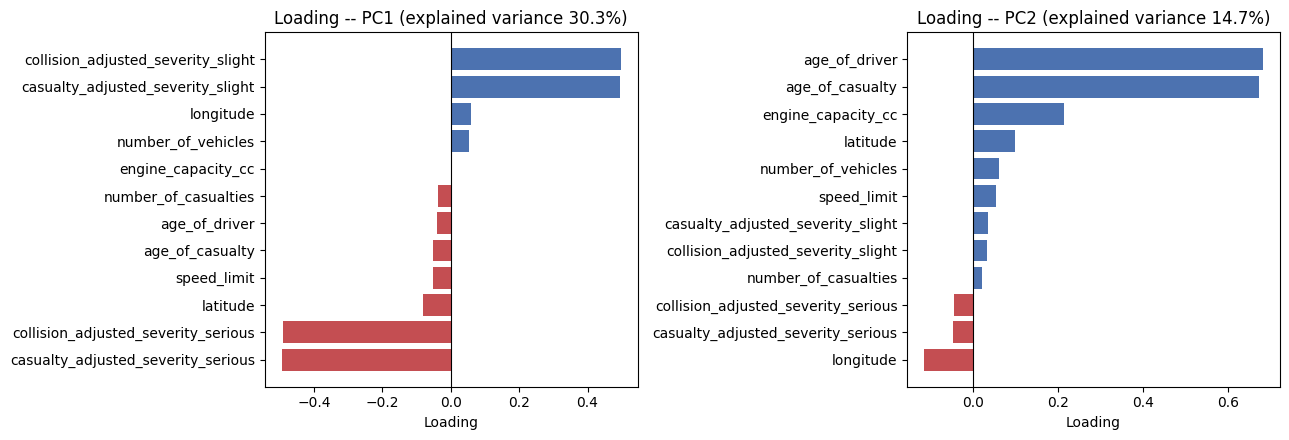

In [104]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, pc in zip(axes, ['PC1', 'PC2']):
    nilai = loadings[pc].sort_values()
    warna = ['#C44E52' if v < 0 else '#4C72B0' for v in nilai]
    ax.barh(nilai.index, nilai.values, color=warna)
    ax.set_title(f"Loading -- {pc} (explained variance {evr[int(pc[2:])-1]*100:.1f}%)")
    ax.set_xlabel("Loading")
    ax.axvline(0, color='black', linewidth=0.8)

plt.tight_layout()
plt.show()


---

## 5.14 PCA Output (Traceability)

Key/identifier digabungkan kembali dengan hasil PCA hanya untuk keperluan penelusuran data. Key/identifier tidak digunakan sebagai input PCA. Principal component hanya dibentuk dari 12 analytical feature yang telah dipilih pada Stage 4.

Dengan demikian, setiap hasil PCA tetap dapat ditelusuri kembali ke data asal melalui key tanpa menjadikan key sebagai bagian dari perhitungan PCA.

In [105]:
key_untuk_baris_lengkap = X_selected.loc[mask_lengkap, KEY_COLS].reset_index(drop=True)
pca_output = pd.concat([key_untuk_baris_lengkap, pca_result.reset_index(drop=True)], axis=1)

print("pca_output shape:", pca_output.shape)
print("Jumlah baris pca_output sama dengan X_pca_ready?", pca_output.shape[0] == X_pca_ready.shape[0])
pca_output.head(3)


pca_output shape: (92164, 11)
Jumlah baris pca_output sama dengan X_pca_ready? True


,collision_index,vehicle_reference,casualty_reference,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
0,202517H102225,1,1.0,-1.316070,2.972608,-0.462235,0.957120,-0.054264,-1.044984,-0.838680,1.206052
1,202517H102225,2,3.0,-3.716413,2.572069,-0.152684,0.868902,-0.310155,-0.845970,-1.059700,1.093925
2,202517H102225,2,2.0,-1.291465,2.636800,-0.547916,0.941794,0.046528,-0.923851,-0.923732,1.183162


---
## 5.15 Before vs After Dimensionality Reduction

In [106]:
tabel_before_after_pca = pd.DataFrame([

    {
        "Kondisi": "Before PCA",
        "Jumlah fitur/dimensi": len(ANALYTICAL_NUMERIC_KEPT),
        "Variance yang dipertahankan": "100% (seluruh variance dari 12 fitur input)"
    },

    {
        "Kondisi": "After PCA",
        "Jumlah fitur/dimensi": N_COMPONENTS_FINAL,
        "Variance yang dipertahankan": f"{pca_final.explained_variance_ratio_.sum()*100:.2f}% (cumulative explained variance)"
    },

])

tabel_before_after_pca

,Kondisi,Jumlah fitur/dimensi,Variance yang dipertahankan
0,Before PCA,12,100% (seluruh variance dari 12 fitur input)
1,After PCA,8,94.51% (cumulative explained variance)


In [107]:
dimensi_awal = len(ANALYTICAL_NUMERIC_KEPT)

dimensi_akhir = N_COMPONENTS_FINAL

dimensi_direduksi = dimensi_awal - dimensi_akhir

persen_reduksi = dimensi_direduksi / dimensi_awal * 100

print(f"Jumlah dimensi awal      : {dimensi_awal}")
print(f"Jumlah dimensi akhir     : {dimensi_akhir}")
print(f"Dimensi yang direduksi   : {dimensi_direduksi}")
print(f"Persentase reduksi       : {persen_reduksi:.2f}%")

print(
    f"\nVariance yang dijelaskan oleh {N_COMPONENTS_FINAL} komponen: "
    f"{pca_final.explained_variance_ratio_.sum()*100:.2f}%"
)

print(
    "Catatan: persentase variance yang dijelaskan bukan berarti "
    "persentase informasi yang tersisa secara umum, tetapi merupakan "
    "proporsi variance statistik dari data input yang dapat dijelaskan "
    "oleh principal component yang dipilih."
)

Jumlah dimensi awal      : 12
Jumlah dimensi akhir     : 8
Dimensi yang direduksi   : 4
Persentase reduksi       : 33.33%

Variance yang dijelaskan oleh 8 komponen: 94.51%
Catatan: persentase variance yang dijelaskan bukan berarti persentase informasi yang tersisa secara umum, tetapi merupakan proporsi variance statistik dari data input yang dapat dijelaskan oleh principal component yang dipilih.


---
## 5.16 Validation

### A. Input Integrity

In [108]:
print("12 analytical feature dipakai?", len(ANALYTICAL_NUMERIC_KEPT) == 12)
print("Identifier tidak ada dalam X_pca_input?", not any(k in X_pca_input.columns for k in KEY_COLS))
print("Seluruh fitur numerik?", all(pd.api.types.is_numeric_dtype(X_pca_input[c]) for c in X_pca_input.columns))
print("Infinite value pada X_pca_ready?", int(np.isinf(X_pca_ready.values).sum()))
print("Missing value pada X_pca_ready (harus 0, karena sudah difilter complete-case)?", int(X_pca_ready.isna().sum().sum()))
print("Jumlah baris X_pca_ready:", X_pca_ready.shape[0], "(", round(X_pca_ready.shape[0]/len(X_pca_input)*100,2), "% dari X_pca_input, didokumentasikan di bagian 5.2)")


12 analytical feature dipakai? True
Identifier tidak ada dalam X_pca_input? True
Seluruh fitur numerik? True
Infinite value pada X_pca_ready? 0
Missing value pada X_pca_ready (harus 0, karena sudah difilter complete-case)? 0
Jumlah baris X_pca_ready: 92164 ( 46.03 % dari X_pca_input, didokumentasikan di bagian 5.2)


### B. Scaling

In [109]:
print("Mean hasil standardization mendekati 0?", np.allclose(X_scaled.mean(axis=0), 0, atol=1e-6))
print("Std hasil standardization mendekati 1?", np.allclose(X_scaled.std(axis=0), 1, atol=1e-6))
print("Shape X_scaled:", X_scaled.shape, "(baris sesuai jumlah data lengkap, bukan 200.247 karena PCA hanya memakai subset lengkap, sudah dijelaskan di 5.2)")


Mean hasil standardization mendekati 0? True
Std hasil standardization mendekati 1? True
Shape X_scaled: (92164, 12) (baris sesuai jumlah data lengkap, bukan 200.247 karena PCA hanya memakai subset lengkap, sudah dijelaskan di 5.2)


### C. PCA

In [110]:
print("Jumlah komponen final <= jumlah fitur?", N_COMPONENTS_FINAL <= len(ANALYTICAL_NUMERIC_KEPT))
print("Semua explained variance ratio >= 0?", (pca_full.explained_variance_ratio_ >= 0).all())
print("Cumulative explained variance non-decreasing?", (np.diff(cum_evr) >= -1e-12).all())
print("Cumulative explained variance <= 1 (toleransi numerik)?", cum_evr[-1] <= 1 + 1e-9)
print("Jumlah seluruh explained variance ratio mendekati 1?", np.isclose(evr.sum(), 1.0, atol=1e-9))


Jumlah komponen final <= jumlah fitur? True
Semua explained variance ratio >= 0? True
Cumulative explained variance non-decreasing? True
Cumulative explained variance <= 1 (toleransi numerik)? True
Jumlah seluruh explained variance ratio mendekati 1? True


### D. Output

In [111]:
print("Jumlah baris pca_output sama dengan input (X_pca_ready)?", pca_output.shape[0] == X_pca_ready.shape[0])
print("Jumlah PC pada pca_output sesuai N_COMPONENTS_FINAL?", sum(c.startswith('PC') for c in pca_output.columns) == N_COMPONENTS_FINAL)
dup_key_pca_output = pca_output.duplicated(subset=KEY_COLS).sum()
print("Duplicate key baru pada pca_output?", dup_key_pca_output)
print("integrated_data tidak berubah (masih 200.247 x 96)?", integrated_data.shape[1] == 96)
print("X_selected tidak berubah (masih 200.247 x 15)?", X_selected.shape[1] == 15)


Jumlah baris pca_output sama dengan input (X_pca_ready)? True
Jumlah PC pada pca_output sesuai N_COMPONENTS_FINAL? True
Duplicate key baru pada pca_output? 0
integrated_data tidak berubah (masih 200.247 x 96)? True
X_selected tidak berubah (masih 200.247 x 15)? True


---

# 5.17 STAGE 5 VALIDATION GATE

### Input dan Feature

- Input STAGE 4 sudah tervalidasi dan `X_selected` digunakan sebagai sumber `X_pca_input`.
- PCA menggunakan 12 analytical feature yang telah dipilih pada STAGE 4.
- 3 key/identifier (`collision_index`, `vehicle_reference`, `casualty_reference`) tidak digunakan sebagai input PCA.
- Tidak ada atribut categorical/coded yang dimasukkan ke dalam PCA.

### Data Preparation

- Missing value dan infinite value sudah diperiksa.
- Karena PCA membutuhkan data lengkap, analisis menggunakan complete-case pada baris yang memiliki nilai lengkap untuk seluruh 12 analytical feature.
- Tidak dilakukan cleaning baru yang mengubah keputusan pada STAGE 2.
- Perbedaan skala antar-feature sudah diperiksa.
- Standardization dilakukan menggunakan `StandardScaler`.
- Hasil standardization sudah divalidasi dengan mean mendekati 0 dan standar deviasi mendekati 1.

### PCA dan Pemilihan Komponen

- PCA dijalankan terlebih dahulu dengan seluruh 12 komponen untuk mengevaluasi explained variance.
- Explained variance ratio dan cumulative explained variance dihitung dari hasil PCA aktual.
- Scree plot dan cumulative variance plot digunakan untuk membantu evaluasi jumlah komponen.
- Jumlah komponen final ditetapkan secara dinamis berdasarkan target cumulative explained variance sebesar 90%.
- Loading PC dianalisis untuk melihat kontribusi masing-masing feature terhadap principal component.
- Interpretasi loading bersifat deskriptif dan tidak digunakan untuk menyimpulkan hubungan sebab-akibat.

### Output dan Traceability

- Persentase variance yang dijelaskan dan reduksi jumlah dimensi dihitung berdasarkan hasil PCA aktual.
- Jumlah baris `pca_output` sama dengan jumlah baris `X_pca_ready`.
- Key/identifier tetap tersedia pada `pca_output` untuk keperluan penelusuran data, tetapi tidak digunakan dalam perhitungan PCA.
- Tidak ditemukan duplicate key baru pada `pca_output`.
- `integrated_data` dan `X_selected` tidak diubah selama STAGE 5.
- Tidak dilakukan merge baru pada STAGE 5.
- Seluruh angka dan hasil PCA berasal dari perhitungan pada notebook.

### Keterbatasan Cakupan PCA

PCA dilakukan pada **jumlah baris complete-case dari keseluruhan baris**, atau sekitar **persentase coverage aktual** dari `X_selected`.

Subset tersebut terdiri dari baris yang memiliki nilai lengkap pada seluruh 12 analytical feature. Baris lainnya tidak digunakan dalam PCA karena masih memiliki `NaN`.

Kondisi ini terutama berkaitan dengan adanya baris vehicle yang tidak memiliki casualty terhubung, sehingga beberapa atribut casualty bernilai `NaN`. Kondisi tersebut merupakan konsekuensi dari grain dan proses integration pada STAGE 3, bukan kesalahan data.

Dengan demikian, `pca_output` tidak mewakili seluruh `integrated_data`, tetapi hanya subset data yang memenuhi kriteria complete-case.

Keterbatasan cakupan ini harus tetap diperhatikan dan dijelaskan pada STAGE 6.

---

## STAGE 5 STATUS: **GO TO STAGE 6**

### Kesimpulan

STAGE 5 telah selesai sesuai dengan prosedur PCA yang ditetapkan. PCA dilakukan menggunakan 12 analytical feature setelah standardization, tanpa memasukkan key/identifier.

Sebanyak **8 principal component** dipilih berdasarkan target cumulative explained variance sebesar **90%**. Explained variance, loading, dan reduksi dimensi dihitung dari hasil PCA aktual pada notebook.

Dimensionality reduction menghasilkan `pca_output` dengan **baris complete-case × 11 kolom**, yang terdiri dari 3 key/identifier dan 8 principal component.

Hasil PCA dapat digunakan untuk STAGE 6 (Visualization & Evaluation), dengan catatan bahwa PCA hanya menggunakan **persentase coverage aktual** dari keseluruhan baris `integrated_data`.

---

## Ringkasan STAGE 5

### STAGE 5 — PCA & Dimensionality Reduction

### Tujuan

Menerapkan PCA untuk mengurangi jumlah dimensi dari 12 analytical feature hasil STAGE 4 dengan tetap mempertahankan sebagian besar variance data.

### Input

- PCA menggunakan 12 analytical feature dari STAGE 4.
- Identifier tidak digunakan sebagai input PCA.
- Standardization menggunakan `StandardScaler` dilakukan sebelum PCA karena setiap feature memiliki skala dan satuan yang berbeda.
- PCA dilakukan pada baris `X_pca_ready`, yaitu subset complete-case dari `X_selected`; jumlah dan persentasenya dihitung langsung dari data. yang memiliki data lengkap pada seluruh 12 analytical feature.
- Complete-case digunakan secara eksplisit dan tidak mengubah atau menghapus baris dari `X_selected`.

### Analisis

- Metode yang digunakan: PCA dari `scikit-learn`.
- Whitening tidak digunakan.
- PCA pertama kali dijalankan dengan 12 komponen untuk melihat explained variance.
- Target cumulative explained variance yang dibandingkan adalah 90% dan 95%.
- Target 90% dan 95% dibandingkan dari cumulative explained variance aktual.

### Hasil

- Jumlah komponen final dipilih berdasarkan target cumulative explained variance yang ditetapkan pada bagian Component Selection.
- Cumulative explained variance final ditampilkan dari `pca_final.explained_variance_ratio_.sum()`.
- Jumlah dimensi akhir dan persentase reduksi dihitung langsung dari jumlah analytical feature dan `N_COMPONENTS_FINAL`.
- 

### Interpretasi

- PC1 memiliki kontribusi besar dari beberapa fitur `adjusted_severity`, sehingga hasilnya sejalan dengan temuan STAGE 4 mengenai korelasi tinggi pada kelompok severity.
- PC2 terutama memiliki kontribusi dari `age_of_driver` dan `age_of_casualty`.
- PC3 terutama memiliki kontribusi dari `longitude` dan `latitude`, yang berkaitan dengan variasi lokasi geografis.
- PC berikutnya masih dibentuk oleh kombinasi beberapa fitur seperti `number_of_vehicles`, `speed_limit`, `number_of_casualties`, dan `engine_capacity_cc`.
- Hasil ini menunjukkan bahwa variance data masih tersebar pada beberapa komponen, sehingga komponen sebanyak `N_COMPONENTS_FINAL` dari 12 masih diperlukan untuk mencapai target cumulative explained variance 90%.

### Validasi

- Jumlah baris `pca_output` sama dengan jumlah baris `X_pca_ready`.
- Identifier tidak digunakan dalam perhitungan PCA, tetapi tetap tersedia pada `pca_output` untuk penelusuran data.
- `integrated_data` dan `X_selected` tidak diubah selama STAGE 5.
- Seluruh nilai explained variance, loading, dan jumlah komponen berasal dari hasil perhitungan PCA pada notebook.

### Validation Gate

**GO TO STAGE 6**

STAGE 5 selesai dan hasil PCA dapat digunakan untuk tahap berikutnya. Perlu diperhatikan bahwa PCA hanya dihitung pada **baris complete-case (persentase coverage aktual)** yang memiliki data lengkap pada seluruh 12 analytical feature. Keterbatasan cakupan ini perlu tetap diperhatikan pada STAGE 6.

# STAGE 6 — Visualisasi & Evaluasi

## UK Road Safety Open Data 2025 — Penutup Pipeline Preprocessing

### 6.1 Objective

STAGE 6 **bukan** tahap preprocessing baru. Tahap ini menyajikan hasil STAGE 1–5 secara visual, membandingkan kondisi data sebelum dan sesudah setiap tahap, serta mengevaluasi apakah setiap tahap telah memenuhi tujuannya berdasarkan bukti aktual, bukan angka atau asumsi baru.

Prinsip: **Evidence → Visualization → Comparison → Evaluation → Insight → Final Validation**.


---

## 6.2 Pipeline Summary

| Stage | Input | Output | Kondisi (bukti aktual) | Tujuan |
|---|---|---|---|---|
| 1. Profiling | Collision/Vehicle/Casualty raw | `*_raw` (tidak diubah) | jumlah baris aktual pada tiga tabel raw baris; struktur, grain, key, missing value, dan kode `-1` diperiksa | Memahami kondisi awal dan struktur data |
| 2. Cleaning | `*_raw` | `*_clean` | Kode `-1` diubah menjadi `NaN` pada kolom yang berdasarkan Data Guide menunjukkan missing value; kode `-1` dengan arti lain tetap dipertahankan | Menangani masalah kualitas data berdasarkan evidence |
| 3. Integration | `*_clean` | `integrated_data` (shape aktual `integrated_data`) | Data digabung secara hierarkis dengan grain campuran: casualty yang terhubung dengan vehicle atau vehicle tanpa casualty; referential integrity 100% | Menggabungkan ketiga dataset dengan tetap menjaga struktur dan hubungan data |
| 4. Attribute Selection | `integrated_data` | `X_selected` (shape aktual `X_selected`) | Terdiri dari 3 key/identifier dan 12 analytical feature; atribut lainnya tidak dimasukkan ke feature set, tetapi tetap tersedia di dataset utama | Memilih atribut yang digunakan untuk analisis dan mempersiapkan input PCA |
| 5. PCA | `X_selected` (12 analytical feature) | `pca_output` (jumlah baris complete-case × 11) | PCA menggunakan jumlah baris complete-case baris (persentase coverage aktual) yang memiliki data lengkap pada seluruh 12 analytical feature; `N_COMPONENTS_FINAL` PC menjelaskan cumulative explained variance aktual. | Mengurangi jumlah dimensi dengan mengubah analytical feature menjadi principal component |
| 6. Visualization & Evaluation | Output STAGE 1–5 | Hasil visualisasi dan evaluasi pada notebook | Hasil dari tahap sebelumnya digunakan untuk visualisasi dan evaluasi | Menyajikan dan mengevaluasi hasil dari seluruh pipeline |

Ringkasan ini disusun berdasarkan hasil aktual dari variabel yang dihasilkan pada setiap tahap, seperti `integrated_data.shape`, `X_selected.shape`, dan `X_pca_ready.shape`, sehingga angka yang ditampilkan dapat ditelusuri kembali ke proses pada notebook.

---

## 6.3 Before vs After Data Quality

### A. Missing Value (NaN Eksplisit) — Total per Dataset

Perbandingan menggunakan total `NaN` pada setiap dataset sebelum dan sesudah cleaning.

Total per dataset dipilih karena STAGE 2 mengubah nilai `-1` menjadi `NaN` pada banyak kolom sekaligus. Jika ditampilkan per kolom, jumlah kolom yang banyak (44, 32, dan 23 kolom) akan membuat grafik sulit dibaca.

Detail perubahan missing value pada masing-masing kolom sudah diperiksa dan dicatat pada STAGE 2.

In [112]:
nan_sebelum = [int(collision_raw.isna().sum().sum()), int(vehicle_raw.isna().sum().sum()), int(casualty_raw.isna().sum().sum())]
nan_sesudah = [int(collision_clean.isna().sum().sum()), int(vehicle_clean.isna().sum().sum()), int(casualty_clean.isna().sum().sum())]
label_dataset = ['Collision', 'Vehicle', 'Casualty']

tabel_missing = pd.DataFrame({'Dataset': label_dataset, 'NaN sebelum cleaning': nan_sebelum, 'NaN sesudah cleaning': nan_sesudah})
tabel_missing


,Dataset,NaN sebelum cleaning,NaN sesudah cleaning
0,Collision,8,549076
1,Vehicle,0,684796
2,Casualty,0,73074


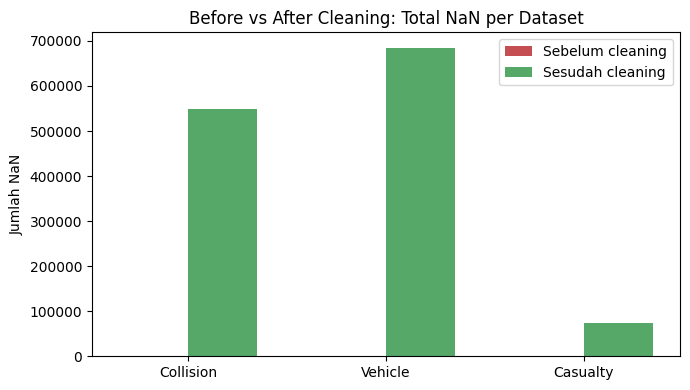

In [113]:
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(3)
lebar = 0.35
ax.bar(x - lebar/2, nan_sebelum, lebar, label='Sebelum cleaning', color='#C44E52')
ax.bar(x + lebar/2, nan_sesudah, lebar, label='Sesudah cleaning', color='#55A868')
ax.set_xticks(x); ax.set_xticklabels(label_dataset)
ax.set_ylabel('Jumlah NaN')
ax.set_title('Before vs After Cleaning: Total NaN per Dataset')
ax.legend()
plt.tight_layout(); plt.show()


**Interpretasi:**

Jumlah `NaN` meningkat setelah proses cleaning. Kenaikan ini bukan menunjukkan kegagalan cleaning, tetapi merupakan hasil yang diharapkan dari proses konversi kode missing value.

Pada STAGE 2, nilai `-1` yang berdasarkan Data Guide dinyatakan sebagai missing value diubah menjadi `NaN`. Sebelumnya, nilai tersebut masih tersimpan sebagai angka sehingga dapat dianggap sebagai nilai valid dalam perhitungan statistik. Setelah dikonversi menjadi `NaN`, missing value menjadi lebih jelas dan dapat ditangani dengan tepat pada tahap berikutnya, termasuk pada STAGE 5.

Dengan demikian, masalah kualitas data yang telah teridentifikasi dan memiliki dasar penanganan sudah ditangani sesuai keputusan cleaning. Sementara itu, nilai yang memiliki makna khusus, seperti `local_authority_district = -1` yang didefinisikan sebagai `Code deprecated` dan `propulsion_code = -1` yang didefinisikan sebagai `Undefined`, tetap dipertahankan. Nilai yang belum memiliki dasar penanganan yang cukup, seperti `age_of_vehicle = -1` dan `driver_distance_banding = -1`, juga dipertahankan sesuai keputusan pada STAGE 2.

---

## 6.4 Integration Evaluation

Evaluasi STAGE 3 tidak hanya berdasarkan jumlah baris. Setiap dataset memiliki grain yang berbeda, sehingga perubahan jumlah baris setelah merge perlu dijelaskan berdasarkan relationship dan jenis merge yang digunakan.

- `Collision`: 1 baris = 1 collision.
- `Vehicle`: 1 baris = 1 vehicle involvement.
- `Casualty`: 1 baris = 1 casualty.
- Hubungan `Collision → Vehicle` bersifat one-to-many karena satu collision dapat melibatkan beberapa vehicle.
- Hubungan `Vehicle → Casualty` juga dapat bersifat one-to-many karena satu vehicle dapat berkaitan dengan beberapa casualty.

Oleh karena itu, perubahan jumlah baris setelah integration merupakan konsekuensi dari perbedaan grain dan relationship antar-dataset, bukan secara langsung menunjukkan adanya duplikasi atau kesalahan data.

In [114]:
tabel_grain = pd.DataFrame([
    {"Tabel": "Collision", "Rows": len(collision_clean), "Grain": "1 baris = 1 collision"},
    {"Tabel": "Vehicle", "Rows": len(vehicle_clean), "Grain": "1 baris = 1 vehicle involvement"},
    {"Tabel": "Casualty", "Rows": len(casualty_clean), "Grain": "1 baris = 1 casualty"},
    {"Tabel": "integrated_data", "Rows": len(integrated_data), "Grain": "1 baris = 1 casualty ATAU 1 vehicle tanpa casualty"},
])
tabel_grain


,Tabel,Rows,Grain
0,Collision,101525,1 baris = 1 collision
1,Vehicle,183948,1 baris = 1 vehicle involvement
2,Casualty,127883,1 baris = 1 casualty
3,integrated_data,200247,1 baris = 1 casualty ATAU 1 vehicle tanpa casu...


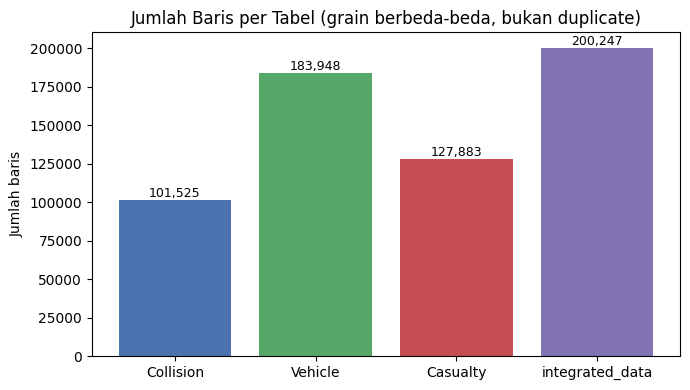

In [115]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(tabel_grain['Tabel'], tabel_grain['Rows'], color=['#4C72B0', '#55A868', '#C44E52', '#8172B2'])
ax.set_ylabel('Jumlah baris')
ax.set_title('Jumlah Baris per Tabel (grain berbeda-beda, bukan duplicate)')
for i, v in enumerate(tabel_grain['Rows']):
    ax.text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=9)
plt.tight_layout(); plt.show()


**Evaluasi:**

Jumlah baris `integrated_data` (jumlah baris aktual) lebih besar daripada jumlah baris `Collision` (101.525). Perbedaan ini terjadi karena data memiliki hubungan `one-to-many`: satu `collision` dapat memiliki beberapa `vehicle`, dan satu `vehicle` dapat berkaitan dengan beberapa `casualty`.

Perubahan jumlah baris tersebut bukan menunjukkan duplikasi data. Pada STAGE 3, cardinality setiap merge divalidasi menggunakan `validate="one_to_many"` dan referential integrity menunjukkan 100% key yang cocok tanpa baris *unmatched*.

Pada `integrated_data`, fitur yang berasal dari level `Casualty`, seperti `age_of_casualty` dan `casualty_adjusted_severity_*`, bernilai `NaN` pada baris vehicle yang tidak memiliki casualty yang terhubung. Kondisi ini merupakan konsekuensi dari penggunaan `left merge`, bukan error pada data.

Kondisi tersebut juga memengaruhi cakupan PCA pada STAGE 5 karena baris yang memiliki `NaN` pada analytical feature tidak dapat digunakan dalam complete-case analysis. Dampaknya terhadap cakupan PCA dibahas lebih lanjut pada Bagian 6.10.

---
## 6.5 Attribute Selection Visualization

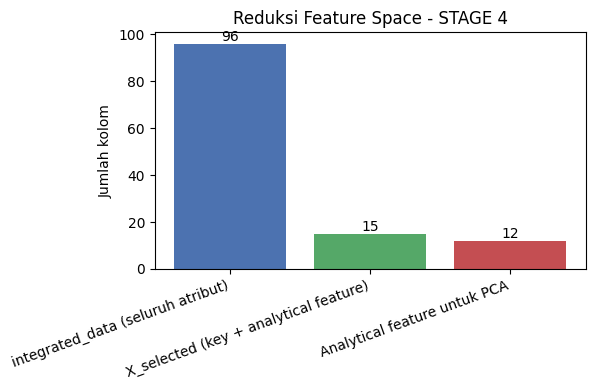

In [116]:
tabel_feature_space = pd.DataFrame([
    {"Tahap": "integrated_data (seluruh atribut)", "Jumlah Kolom": integrated_data.shape[1]},
    {"Tahap": "X_selected (key + analytical feature)", "Jumlah Kolom": X_selected.shape[1]},
    {"Tahap": "Analytical feature untuk PCA", "Jumlah Kolom": len(ANALYTICAL_NUMERIC_KEPT)},
])
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(tabel_feature_space['Tahap'], tabel_feature_space['Jumlah Kolom'], color=['#4C72B0', '#55A868', '#C44E52'])
ax.set_ylabel('Jumlah kolom')
ax.set_title('Reduksi Feature Space - STAGE 4')
plt.xticks(rotation=20, ha='right')
for i, v in enumerate(tabel_feature_space['Jumlah Kolom']):
    ax.text(i, v, str(v), ha='center', va='bottom')
plt.tight_layout(); plt.show()


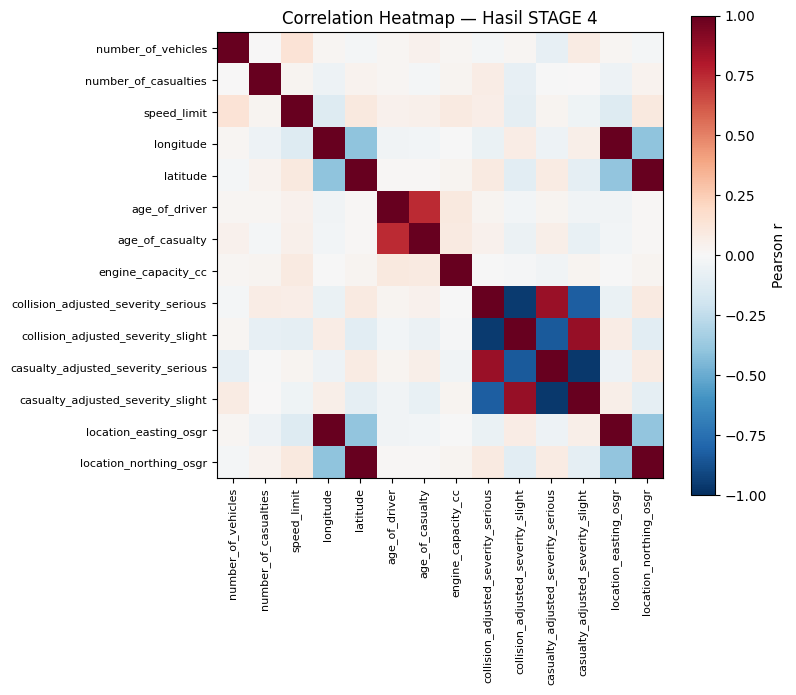

In [117]:
# Visualisasi menggunakan correlation matrix yang sudah dihitung dan divalidasi pada STAGE 4.
# Tidak dilakukan correlation analysis baru pada STAGE 6.
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr_matrix.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(KOLOM_UNTUK_CORR)))
ax.set_yticks(range(len(KOLOM_UNTUK_CORR)))
ax.set_xticklabels(KOLOM_UNTUK_CORR, rotation=90, fontsize=8)
ax.set_yticklabels(KOLOM_UNTUK_CORR, fontsize=8)
plt.colorbar(im, ax=ax, label='Pearson r')
ax.set_title("Correlation Heatmap — Hasil STAGE 4")
plt.tight_layout()
plt.show()


**Catatan:**

Heatmap ini menggunakan kolom dan metode Pearson yang sama dengan yang digunakan pada STAGE 4. Dengan demikian, heatmap ini merupakan visualisasi dari hasil correlation analysis yang sudah dilakukan, bukan analisis korelasi baru.

Pada STAGE 4, korelasi tinggi pada klaster `*_adjusted_severity_*` digunakan sebagai evidence untuk pemeriksaan redundansi. Namun, korelasi tinggi tidak langsung menjadi alasan untuk menghapus atribut.

Keempat atribut `adjusted_severity` tetap dipertahankan karena definisi pada Data Guide belum memberikan dasar yang cukup untuk menyatakan bahwa atribut-atribut tersebut merupakan duplikat atau dapat saling menggantikan. Pembahasan dan keputusan tersebut sudah dicatat pada STAGE 4 Bagian 4.7.

---
## 6.6 PCA Explained Variance

Scree plot dan cumulative variance plot memakai `pca_full` (hasil STAGE 5), dengan target 90% dan posisi komponen final (PC8).

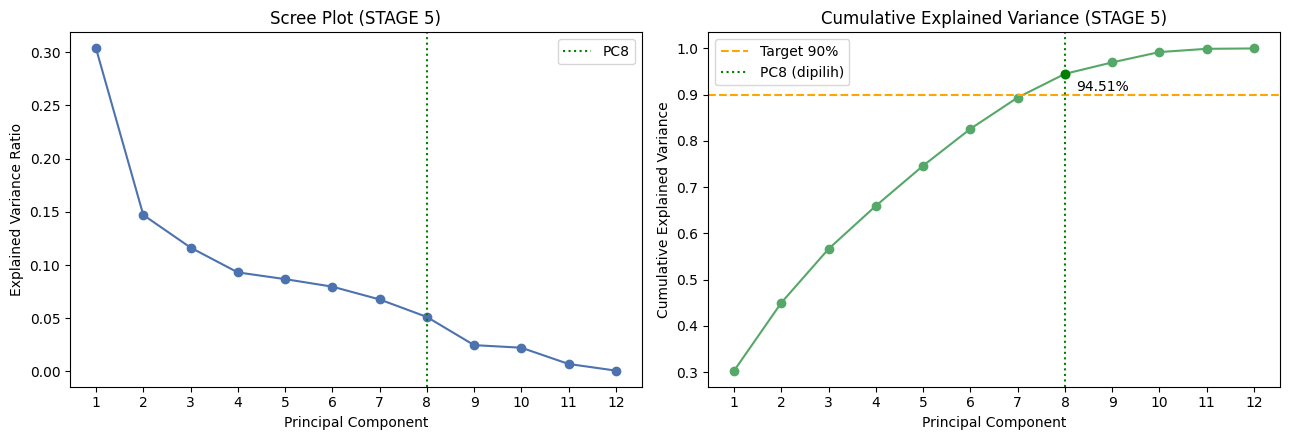

Komponen final: PC8 | Cumulative explained variance: 94.51%


In [118]:
n_pcs = len(evr)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(range(1, n_pcs + 1), evr, marker='o', color='#4C72B0')
axes[0].axvline(N_COMPONENTS_FINAL, color='green', linestyle=':', label=f'PC{N_COMPONENTS_FINAL}')
axes[0].set_xlabel('Principal Component'); axes[0].set_ylabel('Explained Variance Ratio')
axes[0].set_title('Scree Plot (STAGE 5)'); axes[0].set_xticks(range(1, n_pcs + 1)); axes[0].legend()
axes[1].plot(range(1, n_pcs + 1), cum_evr, marker='o', color='#55A868')
axes[1].axhline(TARGET_CUM_VARIANCE, color='orange', linestyle='--', label=f'Target {TARGET_CUM_VARIANCE*100:.0f}%')
axes[1].axvline(N_COMPONENTS_FINAL, color='green', linestyle=':', label=f'PC{N_COMPONENTS_FINAL} (dipilih)')
axes[1].scatter([N_COMPONENTS_FINAL], [cum_evr[N_COMPONENTS_FINAL-1]], color='green', zorder=5)
axes[1].annotate(f'{cum_evr[N_COMPONENTS_FINAL-1]*100:.2f}%', (N_COMPONENTS_FINAL, cum_evr[N_COMPONENTS_FINAL-1]),
                  textcoords='offset points', xytext=(8, -12))
axes[1].set_xlabel('Principal Component'); axes[1].set_ylabel('Cumulative Explained Variance')
axes[1].set_title('Cumulative Explained Variance (STAGE 5)'); axes[1].set_xticks(range(1, n_pcs + 1)); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"Komponen final: PC{N_COMPONENTS_FINAL} | Cumulative explained variance: {cum_evr[N_COMPONENTS_FINAL-1]*100:.2f}%")


---
## 6.7 PCA Loading Visualization

Hanya PC1 dan PC2 (explained variance terbesar) yang ditampilkan, memakai `loadings` hasil STAGE 5.

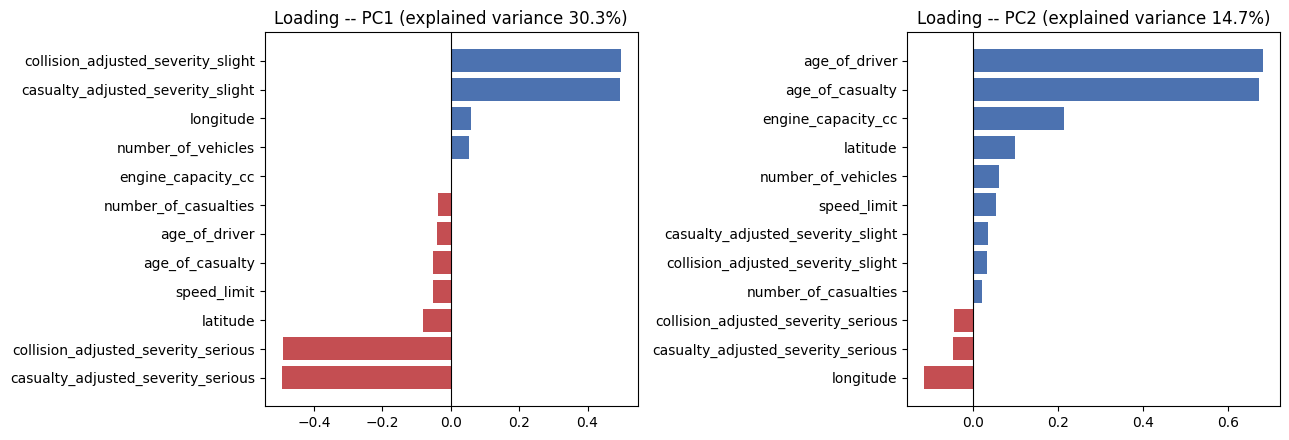

PC1 -- fitur dengan absolute loading terbesar: ['collision_adjusted_severity_slight', 'casualty_adjusted_severity_slight', 'casualty_adjusted_severity_serious']
PC2 -- fitur dengan absolute loading terbesar: ['age_of_driver', 'age_of_casualty', 'engine_capacity_cc']


In [119]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, pc in zip(axes, ['PC1', 'PC2']):
    nilai = loadings[pc].sort_values()
    warna = ['#C44E52' if v < 0 else '#4C72B0' for v in nilai]
    ax.barh(nilai.index, nilai.values, color=warna)
    ax.set_title(f"Loading -- {pc} (explained variance {evr[int(pc[2:])-1]*100:.1f}%)")
    ax.axvline(0, color='black', linewidth=0.8)
plt.tight_layout(); plt.show()

print("PC1 -- fitur dengan absolute loading terbesar:", loadings['PC1'].abs().sort_values(ascending=False).head(3).index.tolist())
print("PC2 -- fitur dengan absolute loading terbesar:", loadings['PC2'].abs().sort_values(ascending=False).head(3).index.tolist())


**Interpretasi (deskriptif):**

PC1 memiliki kontribusi terbesar dari kelompok `*_adjusted_severity_*` berdasarkan nilai absolut loading. PC2 memiliki kontribusi terbesar dari `age_of_driver` dan `age_of_casualty`.

Hasil ini menunjukkan fitur yang memiliki kontribusi paling besar dalam membentuk kombinasi linear pada masing-masing principal component. Hasil tersebut tidak menunjukkan hubungan sebab-akibat atau bahwa suatu fitur menyebabkan terbentuknya PC.

---

## 6.8 PCA Projection (PC1 vs PC2)

`pca_output` memiliki jumlah baris complete-case titik sehingga seluruh data akan terlalu padat jika ditampilkan dalam scatter plot. Untuk meningkatkan keterbacaan visualisasi, digunakan sampling khusus untuk keperluan plot dengan `random_state=42`.

Sampling ini hanya digunakan untuk visualisasi dan tidak mengubah `pca_output`, hasil PCA, maupun jumlah data yang digunakan dalam perhitungan PCA.

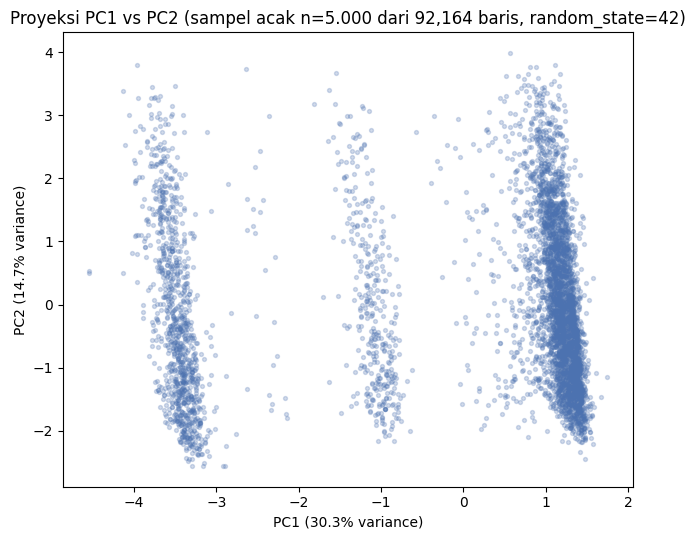

In [120]:
sampel_plot = pca_output.sample(n=5000, random_state=42)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(sampel_plot['PC1'], sampel_plot['PC2'], alpha=0.25, s=8, color='#4C72B0')
ax.set_xlabel(f'PC1 ({evr[0]*100:.1f}% variance)')
ax.set_ylabel(f'PC2 ({evr[1]*100:.1f}% variance)')
ax.set_title(f'Proyeksi PC1 vs PC2 (sampel acak n=5.000 dari {len(pca_output):,} baris, random_state=42)')
plt.tight_layout(); plt.show()


**Interpretasi:**

Visualisasi ini menunjukkan pola sebaran observasi pada ruang PC1–PC2. Pola yang terlihat tidak digunakan untuk menyimpulkan adanya cluster tertentu karena tidak dilakukan metode clustering pada pipeline ini.

Dengan demikian, scatter plot digunakan untuk melihat distribusi dan pola sebaran data pada dua principal component pertama, bukan untuk menentukan kelompok data.

---
## 6.9 Before vs After Preprocessing (Tabel Utama)

In [121]:
tabel_utama = pd.DataFrame([

    {
        "Kondisi": "Sebelum preprocessing (raw)",
        "Rows": f"{len(collision_raw)} / {len(vehicle_raw)} / {len(casualty_raw)}",
        "Columns/Features": (
            f"{collision_raw.shape[1]} / "
            f"{vehicle_raw.shape[1]} / "
            f"{casualty_raw.shape[1]}"
        ),
        "Keterangan": (
            "Collision, Vehicle, dan Casualty masih terpisah; "
            "kode -1 belum diperiksa maknanya"
        )
    },

    {
        "Kondisi": "Setelah cleaning (STAGE 2)",
        "Rows": (
            f"{len(collision_clean)} / "
            f"{len(vehicle_clean)} / "
            f"{len(casualty_clean)}"
        ),
        "Columns/Features": (
            f"{collision_clean.shape[1]} / "
            f"{vehicle_clean.shape[1]} / "
            f"{casualty_clean.shape[1]}"
        ),
        "Keterangan": (
            "Jumlah baris dan kolom tetap; "
            "kode -1 diubah menjadi NaN pada kolom yang terverifikasi "
            "sebagai missing value berdasarkan Data Guide"
        )
    },

    {
        "Kondisi": "Setelah integration (STAGE 3)",
        "Rows": f"{integrated_data.shape[0]:,}",
        "Columns/Features": f"{integrated_data.shape[1]} kolom",
        "Keterangan": (
            "Grain campuran: casualty yang terhubung dengan vehicle "
            "atau vehicle tanpa casualty; referential integrity 100%"
        )
    },

    {
        "Kondisi": "Setelah attribute selection (STAGE 4)",
        "Rows": f"{X_selected.shape[0]:,}",
        "Columns/Features": (
            f"{len(ANALYTICAL_NUMERIC_KEPT)} analytical feature + "
            f"{len(KEY_COLS)} key"
        ),
        "Keterangan": (
            "Jumlah baris tetap; jumlah kolom berkurang dari 96 menjadi 15. "
            "Perubahan hanya berlaku pada feature set, bukan pada dataset utama"
        )
    },

    {
        "Kondisi": "PCA input (STAGE 5)",
        "Rows": f"{X_pca_ready.shape[0]:,}",
        "Columns/Features": "12 analytical feature",
        "Keterangan": (
            "Menggunakan subset complete-case dengan data lengkap "
            "pada seluruh 12 analytical feature"
        )
    },

    {
        "Kondisi": "PCA output (STAGE 5)",
        "Rows": f"{pca_output.shape[0]:,}",
        "Columns/Features": (
            f"{N_COMPONENTS_FINAL} principal component + "
            f"{len(KEY_COLS)} key"
        ),
        "Keterangan": (
            f"{cum_evr[N_COMPONENTS_FINAL-1]*100:.2f}% "
            "cumulative explained variance"
        )
    },

])

tabel_utama

,Kondisi,Rows,Columns/Features,Keterangan
0,Sebelum preprocessing (raw),101525 / 183948 / 127883,44 / 32 / 23,"Collision, Vehicle, dan Casualty masih terpisa..."
1,Setelah cleaning (STAGE 2),101525 / 183948 / 127883,44 / 32 / 23,Jumlah baris dan kolom tetap; kode -1 diubah m...
2,Setelah integration (STAGE 3),"200,247",96 kolom,Grain campuran: casualty yang terhubung dengan...
3,Setelah attribute selection (STAGE 4),"200,247",12 analytical feature + 3 key,Jumlah baris tetap; jumlah kolom berkurang dar...
4,PCA input (STAGE 5),"92,164",12 analytical feature,Menggunakan subset complete-case dengan data l...
5,PCA output (STAGE 5),"92,164",8 principal component + 3 key,94.51% cumulative explained variance


### Definisi Penting

- **Columns** = seluruh kolom yang terdapat pada dataset/file CSV asli.
- **Analytical features** = subset kolom numerik yang dipilih setelah evaluasi redundansi pada STAGE 4 dan digunakan sebagai input analisis korelasi serta PCA.
- **Principal components** = variabel/sumbu baru yang dihasilkan dari transformasi linear PCA terhadap analytical features. Principal components bukan kolom asli dan bukan hasil penghapusan analytical features.

---
## 6.10 PCA Coverage

**Bagian ini wajib ada** karena STAGE 5 hanya memakai persentase coverage aktual dari `X_selected`.

In [122]:
tabel_coverage = pd.DataFrame([
    {"Population": "Total X_selected", "Rows": X_selected.shape[0], "Percentage": "100%"},
    {"Population": "Complete-case used for PCA", "Rows": X_pca_ready.shape[0],
     "Percentage": f"{X_pca_ready.shape[0]/X_selected.shape[0]*100:.2f}%"},
    {"Population": "Not used in PCA", "Rows": X_selected.shape[0]-X_pca_ready.shape[0],
     "Percentage": f"{(X_selected.shape[0]-X_pca_ready.shape[0])/X_selected.shape[0]*100:.2f}%"},
])
tabel_coverage


,Population,Rows,Percentage
0,Total X_selected,200247,100%
1,Complete-case used for PCA,92164,46.03%
2,Not used in PCA,108083,53.97%


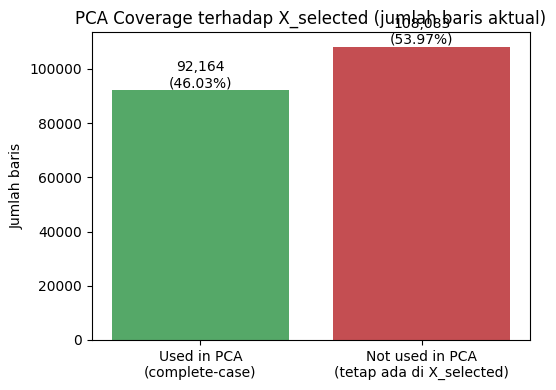

In [123]:
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.bar(['Used in PCA\n(complete-case)', 'Not used in PCA\n(tetap ada di X_selected)'],
       [X_pca_ready.shape[0], X_selected.shape[0]-X_pca_ready.shape[0]], color=['#55A868', '#C44E52'])
ax.set_ylabel('Jumlah baris')
ax.set_title('PCA Coverage terhadap X_selected (jumlah baris aktual)')
for i, v in enumerate([X_pca_ready.shape[0], X_selected.shape[0]-X_pca_ready.shape[0]]):
    ax.text(i, v, f'{v:,}\n({v/X_selected.shape[0]*100:.2f}%)', ha='center', va='bottom')
plt.tight_layout(); plt.show()


### Cakupan Data pada PCA

`X_selected` tetap memiliki jumlah baris aktual baris. Namun, PCA hanya menggunakan jumlah baris complete-case baris atau persentase coverage aktual dari keseluruhan data karena hanya baris tersebut yang memenuhi *complete-case criteria*, yaitu tidak memiliki `NaN` pada seluruh 12 analytical feature.

Sebanyak baris yang tidak memenuhi complete-case atau persentase baris yang tidak memenuhi complete-case tidak dihapus dari `X_selected` maupun `integrated_data`. Baris tersebut hanya tidak diikutsertakan dalam perhitungan PCA karena memiliki missing value pada setidaknya satu dari 12 analytical feature.

Berdasarkan hasil pemeriksaan pada STAGE 5, sebanyak jumlah baris vehicle tanpa casualty yang dihitung aktual dari baris yang tidak memenuhi complete-case yang tidak memenuhi complete-case berasal dari kondisi vehicle yang tidak memiliki casualty terhubung. Kondisi tersebut merupakan konsekuensi struktural dari integration pada STAGE 3, sehingga beberapa atribut `Casualty` bernilai `NaN`.

Baris lainnya tidak memenuhi complete-case karena terdapat missing value pada analytical feature seperti `age_of_driver`, `age_of_casualty`, atau `engine_capacity_cc`.

Dengan demikian, pembatasan complete-case hanya berlaku pada perhitungan PCA dan tidak mengubah atau menghapus data pada `X_selected` maupun `integrated_data`.

In [124]:
# Angka pendukung Insight 4 (PC1 explained variance dan fitur dominannya) -- dihitung dari variabel aktual
print(f"PC1 explained variance ratio: {evr[0]*100:.2f}% (terbesar dari seluruh 12 komponen)")
print("Fitur dengan absolute loading terbesar pada PC1:", loadings['PC1'].abs().sort_values(ascending=False).head(4).index.tolist())


PC1 explained variance ratio: 30.34% (terbesar dari seluruh 12 komponen)
Fitur dengan absolute loading terbesar pada PC1: ['collision_adjusted_severity_slight', 'casualty_adjusted_severity_slight', 'casualty_adjusted_severity_serious', 'collision_adjusted_severity_serious']


---

## 6.11 Key Insights

### Insight 1 — Feature Reduction

**Finding:**  
12 analytical features dari STAGE 4 ditransformasikan menjadi jumlah principal components terpilih pada data yang memenuhi complete-case criteria.

**Evidence:**  
jumlah principal components terpilih menjelaskan cumulative explained variance aktual cumulative explained variance. Jumlah dimensi berkurang sebesar persentase reduksi dimensi aktual, dari 12 menjadi `N_COMPONENTS_FINAL`.

**Meaning:**  
Dimensionality reduction berhasil dilakukan, tetapi pengurangannya tidak terlalu besar. Hal ini sejalan dengan hasil STAGE 4, dimana sebagian besar analytical feature tidak menunjukkan korelasi linear yang tinggi satu sama lain.

### Insight 2 — PCA Coverage Terbatas

**Finding:**  
PCA hanya menggunakan jumlah baris complete-case dari jumlah baris aktual baris `X_selected`.

**Evidence:**  
Sebanyak jumlah baris complete-case baris (persentase coverage aktual) memenuhi complete-case criteria, sedangkan baris yang tidak memenuhi complete-case (persentase baris yang tidak memenuhi complete-case) tidak digunakan dalam perhitungan PCA.

**Meaning:**  
baris yang tidak memenuhi complete-case tersebut tidak dihapus dari `X_selected` maupun `integrated_data`. Hasil PCA, termasuk explained variance dan loading, hanya menggambarkan subset jumlah baris complete-case baris yang memiliki data lengkap pada seluruh 12 analytical feature.

### Insight 3 — Integration Berpengaruh terhadap Missingness

**Finding:**  
Sebagian besar baris yang tidak memenuhi complete-case criteria berkaitan dengan vehicle yang tidak memiliki casualty terhubung.

**Evidence:**  
Dari baris yang tidak memenuhi complete-case yang tidak digunakan dalam PCA, sebanyak jumlah baris vehicle tanpa casualty yang dihitung aktual baris memiliki `casualty_reference` bernilai `NaN`. Kondisi ini diperiksa melalui `X_selected['casualty_reference'].isna()`.

**Meaning:**  
Missing value pada atribut level-casualty sebagian muncul sebagai konsekuensi dari struktur integration pada STAGE 3. Pada hasil `left merge`, vehicle yang tidak memiliki casualty tetap dipertahankan, sehingga atribut casualty pada baris tersebut bernilai `NaN`. Kondisi ini perlu diperhatikan ketika menginterpretasikan cakupan PCA.

### Insight 4 — Severity Berkontribusi Besar pada PC1

**Finding:**  
PC1 memiliki kontribusi terbesar dari kelompok `*_adjusted_severity_*` berdasarkan nilai absolut loading.

**Evidence:**  
Hasil loading pada Bagian 6.7 menunjukkan bahwa beberapa fitur `adjusted_severity` memiliki nilai absolut loading terbesar pada PC1.

**Meaning:**  
Kelompok severity memberikan kontribusi besar dalam membentuk PC1. Hal ini sejalan dengan hasil STAGE 4 yang menunjukkan korelasi tinggi pada kelompok `adjusted_severity`. Keempat fitur tersebut tetap dipertahankan pada STAGE 4 karena belum terdapat evidence yang cukup untuk menyatakan bahwa fitur-fitur tersebut redundan atau dapat saling menggantikan. PCA kemudian merangkum variasi dari fitur-fitur tersebut dalam principal component.

### Insight 5 — Redundansi Koordinat Ditangani Sebelum PCA

**Finding:**  
Koordinat OSGR (`location_easting_osgr` dan `location_northing_osgr`) tidak dimasukkan ke dalam 12 analytical features.

**Evidence:**  
Pada STAGE 4, `location_easting_osgr` memiliki korelasi 0,9995 dengan `longitude`, sedangkan `location_northing_osgr` memiliki korelasi 0,99997 dengan `latitude`. Keempat atribut tersebut juga sama-sama merepresentasikan lokasi collision dengan sistem koordinat yang berbeda.

**Meaning:**  
Koordinat OSGR dikeluarkan dari analytical feature set karena memberikan informasi lokasi yang tumpang tindih dengan `longitude` dan `latitude`. Dengan demikian, PCA menggunakan satu representasi koordinat geografis dan tidak memasukkan kedua sistem koordinat tersebut secara bersamaan.

---

## 6.12 Overall Evaluation (Faktual, Tanpa Skor)

**STAGE 1 — Profiling:**  
Kondisi awal dataset berhasil dipahami sebelum dilakukan perubahan data. Struktur dataset terdiri dari 44 kolom pada `Collision`, 32 kolom pada `Vehicle`, dan 23 kolom pada `Casualty`. Grain setiap dataset, candidate key, missing value, duplicate, serta nilai `-1` diperiksa menggunakan hasil profiling dan pemeriksaan data.

**STAGE 2 — Cleaning:**  
Cleaning dilakukan berdasarkan evidence dari data dan Data Guide. Nilai `-1` diperiksa berdasarkan definisi masing-masing kolom sebelum ditentukan treatment-nya. Nilai `-1` yang terbukti merupakan missing value diubah menjadi `NaN`, sedangkan nilai dengan arti lain atau arti yang belum dapat dipastikan tetap dipertahankan. Contohnya, `age_of_vehicle` dan `driver_distance_banding` tidak diubah karena belum terdapat definisi yang cukup untuk menentukan arti `-1`.

**STAGE 3 — Integration:**  
Ketiga dataset digabung secara hierarkis dengan tetap memperhatikan grain dan relationship antar-dataset. Relationship `Collision → Vehicle` dan `Vehicle → Casualty` divalidasi menggunakan `validate="one_to_many"`. Referential integrity pada hubungan `Vehicle → Collision`, `Casualty → Collision`, dan `Casualty → Vehicle` juga diperiksa dan menunjukkan 100% key yang cocok tanpa baris *unmatched*.

**STAGE 4 — Attribute Selection:**  
Dari 96 kolom `integrated_data`, dipilih 12 analytical features untuk analisis numerik dan PCA. Pemilihan dilakukan berdasarkan profiling atribut, Data Guide, dan pemeriksaan redundansi. Koordinat OSGR dikeluarkan karena memberikan informasi lokasi yang tumpang tindih dengan `longitude` dan `latitude`, sedangkan atribut dengan korelasi tinggi pada kelompok `adjusted_severity` tetap dipertahankan karena belum terdapat evidence yang cukup untuk menyatakan redundansi. Attribute selection hanya mengubah feature set dan tidak menghapus kolom dari `integrated_data`.

**STAGE 5 — PCA & Dimensionality Reduction:**  
PCA menggunakan 12 analytical features tanpa memasukkan identifier. Karena terdapat missing value, PCA dilakukan pada jumlah baris complete-case dari jumlah baris aktual baris yang memenuhi complete-case criteria, atau persentase coverage aktual dari `X_selected`. Pada subset tersebut, 12 analytical features ditransformasikan menjadi jumlah principal components terpilih yang menjelaskan cumulative explained variance aktual cumulative explained variance. Sebanyak baris yang tidak memenuhi complete-case lainnya tidak dihapus dari `X_selected` maupun `integrated_data`; baris tersebut hanya tidak digunakan dalam perhitungan PCA.

**STAGE 6 — Visualization & Evaluation:**  
Hasil dari STAGE 1–5 divisualisasikan dan dibandingkan menggunakan angka aktual dari setiap tahap. Visualisasi digunakan untuk membantu melihat perubahan data, hasil integration, correlation, feature selection, serta hasil PCA. STAGE 6 tidak mengubah keputusan atau data dari STAGE 1–5, tetapi digunakan untuk mengevaluasi dan menyajikan hasil pipeline secara keseluruhan.

---

# 6.13 STAGE 6 VALIDATION GATE

### Consistency

- STAGE 6 menggunakan output aktual STAGE 1–5 yang sudah tersedia di notebook gabungan. Konsistensi diperiksa melalui validation gate pada akhir pipeline.
- Tidak ada keputusan pada STAGE 1–5 yang diubah pada STAGE 6. Tahap ini hanya memvisualisasikan dan mengevaluasi output yang sudah tersedia.
- Nama variabel yang digunakan tetap konsisten dengan tahap sebelumnya, seperti `integrated_data`, `X_selected`, `X_pca_ready`, `pca_full`, `pca_final`, `loadings`, dan `pca_output`.
- Angka pada tabel dan visualisasi dihitung dari dataframe atau variabel aktual, bukan ditulis secara manual.

### Visualization

- Setiap visualisasi pada Bagian 6.3–6.10 memiliki tujuan analitis yang dijelaskan pada teks pendamping.
- Angka yang ditampilkan pada grafik berasal dari data aktual.
- Visualisasi dibuat dengan mempertimbangkan keterbacaan. Misalnya, correlation heatmap menggunakan analytical features yang dianalisis, bukan seluruh 96 kolom, dan scatter plot PCA menggunakan sampling hanya untuk keperluan visualisasi.
- Setiap visualisasi memiliki tujuan yang berbeda sehingga tidak digunakan untuk menampilkan informasi yang sama secara berulang.

### Before vs After

- Kondisi data sebelum dan sesudah proses utama dibandingkan pada Bagian 6.9.
- Perbedaan grain antar-dataset dan antar-stage dijelaskan pada Bagian 6.4 sehingga perubahan jumlah baris tidak diinterpretasikan hanya berdasarkan angka.
- Analytical features dibedakan dari key/identifier pada pembahasan feature selection dan PCA.
- Subset data yang digunakan untuk PCA dibedakan dari keseluruhan `X_selected` dan `integrated_data`.
- Complete-case pada PCA tidak dianggap sebagai penghapusan baris dari dataset utama.

### PCA

- PCA menggunakan 12 analytical features dan menghasilkan jumlah principal components terpilih yang dipilih berdasarkan target cumulative explained variance.
- Jumlah principal component final diperiksa melalui ``N_COMPONENTS_FINAL` mencapai target 90%`.
- Cumulative explained variance sebesar cumulative explained variance aktual dihitung dari hasil PCA aktual menggunakan `cum_evr[N_COMPONENTS_FINAL-1]`, bukan ditulis secara manual.
- Reduksi dimensi sebesar persentase reduksi dimensi aktual dihitung dari jumlah dimensi awal dan akhir, yaitu 12 menjadi `N_COMPONENTS_FINAL`.
- PCA menggunakan jumlah baris complete-case dari jumlah baris aktual baris `X_selected`, atau persentase coverage aktual dari keseluruhan baris.
- Sebanyak baris yang tidak memenuhi complete-case yang tidak memenuhi complete-case criteria tidak dihapus dari `X_selected` maupun `integrated_data`. Baris tersebut hanya tidak digunakan dalam perhitungan PCA.

### Interpretation

- Interpretasi principal component dan loading bersifat deskriptif dan tidak digunakan untuk membuat klaim sebab-akibat.
- Loading dijelaskan sebagai kontribusi feature terhadap kombinasi linear pada masing-masing principal component.
- Tidak dibuat klaim mengenai cluster atau domain risk karena metode clustering atau analisis risiko tidak dilakukan dalam pipeline ini.
- PCA tidak digunakan atau disebut sebagai metode prediksi.
- Explained variance dilaporkan sebagai cumulative explained variance, yaitu proporsi variance data yang dijelaskan oleh principal components yang dipilih, bukan sebagai persentase informasi yang "tersisa".

---

### Kesimpulan Akhir Pipeline

Dataset UK Road Safety 2025 yang terdiri dari `Collision`, `Vehicle`, dan `Casualty` telah melalui seluruh tahapan preprocessing dan analisis yang ditetapkan:

- STAGE 1 melakukan profiling untuk memahami struktur, grain, key, dan kondisi awal data.
- STAGE 2 melakukan cleaning berdasarkan evidence dari data dan Data Guide.
- STAGE 3 melakukan integration dengan memperhatikan grain, relationship, dan referential integrity.
- STAGE 4 melakukan attribute selection berdasarkan profiling, Data Guide, dan pemeriksaan redundansi.
- STAGE 5 menerapkan PCA pada 12 analytical features dengan pelaporan complete-case coverage secara eksplisit.
- STAGE 6 menyajikan dan mengevaluasi hasil dari STAGE 1–5 melalui visualisasi dan perbandingan before-after.


---

## Ringkasan Akhir (untuk laporan/PPT)

### STAGE 6 — Visualisasi & Evaluasi

**Tujuan**

Menyajikan hasil STAGE 1–5 melalui visualisasi serta membandingkan kondisi data pada beberapa tahap utama pipeline.

**Visualisasi utama**

1. Data quality comparison — jumlah `NaN` sebelum dan sesudah cleaning
2. Grain dan row count — perbandingan `Collision`, `Vehicle`, `Casualty`, dan `integrated_data`
3. Feature space — perbandingan 96 kolom `integrated_data`, 15 kolom `X_selected`, dan 12 analytical features yang menjadi input PCA
4. Correlation heatmap — hubungan antar analytical features dan koordinat OSGR yang digunakan untuk pemeriksaan redundansi
5. PCA scree plot dan cumulative explained variance
6. PCA loading — kontribusi analytical features pada PC1 dan PC2
7. Proyeksi PC1 vs PC2 — visualisasi menggunakan sampel 5.000 titik hanya untuk keterbacaan
8. PCA coverage — perbandingan jumlah baris complete-case baris yang digunakan dalam PCA dengan jumlah baris aktual baris `X_selected`

**Hasil utama**

- Analytical features setelah STAGE 4: **12**
- PCA input: **jumlah baris complete-case baris complete-case**
- PCA coverage: **persentase coverage aktual** dari jumlah baris aktual baris `X_selected`
- Principal components yang dipertahankan: **8**
- Cumulative explained variance: **cumulative explained variance aktual**
- Dimensionality reduction: **persentase reduksi dimensi aktual**, dari 12 analytical features menjadi jumlah principal components terpilih

**Key insights**

Lima insight utama disajikan pada Bagian 6.11 dengan struktur **Finding → Evidence → Meaning**, mencakup feature reduction, cakupan PCA, pengaruh integration terhadap missingness, kontribusi severity pada PC1, serta penanganan redundansi koordinat sebelum PCA.

**Limitations**

PCA hanya dihitung pada **jumlah baris complete-case baris (persentase coverage aktual)** yang memenuhi complete-case criteria, yaitu tidak memiliki `NaN` pada seluruh 12 analytical features.

Sebanyak **baris yang tidak memenuhi complete-case (persentase baris yang tidak memenuhi complete-case)** tidak digunakan dalam perhitungan PCA karena memiliki missing value pada setidaknya satu analytical feature. Baris tersebut **tidak dihapus** dan tetap tersimpan pada `X_selected` dan `integrated_data`.

Oleh karena itu, explained variance, loading, dan proyeksi PC yang dihasilkan pada STAGE 5 hanya menggambarkan **subset complete-case jumlah baris complete-case baris**, bukan keseluruhan jumlah baris aktual baris `X_selected`.

---

# Sumber & Landasan Teori

**Sumber dataset:** Department for Transport (DfT), *Road safety open data*. DfT menyediakan file record-level untuk collision, vehicle, dan casualty serta Data Guide untuk mendekode field berkode. Data final 2025 tersedia sebagai file terpisah untuk collisions, vehicles, dan casualties.

**Landasan teori:** preprocessing mencakup data cleaning, data integration, dan data reduction/dimensionality reduction. Pada tahap PCA, fitur numerik yang telah dipilih dipersiapkan, distandardisasi ketika skala berbeda, lalu ditransformasikan menjadi principal components. Explained variance digunakan untuk mengevaluasi jumlah komponen yang dipertahankan.

**Prinsip dokumentasi:** angka hasil dan kesimpulan akhir harus mengikuti output aktual notebook. Markdown tidak digunakan sebagai pengganti perhitungan Python; apabila hasil aktual berbeda dari contoh/angka lama, hasil aktual menjadi acuan.
